<a href="https://colab.research.google.com/github/Digital-City-Lab-MUNI/Incremental-Learning-MycroftMinds/blob/main/notebooks/data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports

In [ ]:
# prompt: connect to drive

from google.colab import drive
drive.mount('/content/drive')


In [1]:
import glob
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = (15,8)

# Meteorological data

In [ ]:
meteo_file_path = '../../data/old_data/meteo_data_0.csv'

meteo_data = pd.read_csv(meteo_file_path)

print('\nShape:', meteo_data.shape,'\n')
meteo_data.head()


Shape: (564115, 59) 



,dateTime,usUnits,interval,barometer,pressure,altimeter,inTemp,outTemp,inHumidity,outHumidity,...,windBatteryStatus,rainBatteryStatus,outTempBatteryStatus,inTempBatteryStatus,cloudbase,windrun,cloudcover,aqi,visibility,humidex
0,1704063607,28.122289,11.448417,1069.693466,1002.549461,1068.574185,NaN,12.663842,NaN,102.416825,...,NaN,NaN,NaN,NaN,445.284266,10.443268,NaN,NaN,NaN,12.634540
1,1704063667,27.940057,11.443831,1073.046950,1005.058712,1040.885134,NaN,12.636567,NaN,105.161522,...,NaN,NaN,NaN,NaN,434.815965,10.445008,NaN,NaN,NaN,12.620366
2,1704063727,28.237231,11.430884,1128.777787,1032.193596,1068.674938,NaN,12.669738,NaN,102.461041,...,NaN,NaN,NaN,NaN,434.863894,10.442467,NaN,NaN,NaN,12.785041
3,1704063787,28.493802,11.435472,1091.024790,1043.835644,1040.939487,NaN,12.713868,NaN,104.504860,...,NaN,NaN,NaN,NaN,435.580647,10.442767,NaN,NaN,NaN,12.700933
4,1704063847,28.160142,11.447994,1056.312488,1060.539662,1051.091724,NaN,12.769091,NaN,103.323499,...,NaN,NaN,NaN,NaN,437.380130,10.442791,NaN,NaN,NaN,12.726492


In [ ]:
meteo_data.columns

Index(['dateTime', 'usUnits', 'interval', 'barometer', 'pressure', 'altimeter',
       'inTemp', 'outTemp', 'inHumidity', 'outHumidity', 'windSpeed',
       'windDir', 'windGust', 'windGustDir', 'rainRate', 'rain', 'dewpoint',
       'windchill', 'appTemp', 'heatindex', 'ET', 'radiation', 'UV',
       'extraTemp1', 'extraTemp2', 'extraTemp3', 'soilTemp1', 'soilTemp2',
       'soilTemp3', 'soilTemp4', 'leafTemp1', 'leafTemp2', 'extraHumid1',
       'extraHumid2', 'soilMoist1', 'soilMoist2', 'soilMoist3', 'soilMoist4',
       'leafWet1', 'leafWet2', 'rxCheckPercent', 'txBatteryStatus',
       'consBatteryVoltage', 'hail', 'hailRate', 'heatingTemp',
       'heatingVoltage', 'supplyVoltage', 'referenceVoltage',
       'windBatteryStatus', 'rainBatteryStatus', 'outTempBatteryStatus',
       'inTempBatteryStatus', 'cloudbase', 'windrun', 'cloudcover', 'aqi',
       'visibility', 'humidex'],
      dtype='object')

## Missing values

In [ ]:
meteo_data.isna().sum()

,0
dateTime,0
usUnits,0
interval,0
barometer,9
pressure,172374
altimeter,172374
inTemp,564115
outTemp,136522
inHumidity,564115
outHumidity,9


### Drop completely empty columns

In [ ]:
# find columns where all entries are nans
full_nan_columns = meteo_data.columns[meteo_data.isna().sum() == meteo_data.shape[0]]
# drop from table
meteo_data = meteo_data.drop(columns=full_nan_columns)
print(meteo_data.columns)
meteo_data.head()

Index(['dateTime', 'usUnits', 'interval', 'barometer', 'pressure', 'altimeter',
       'outTemp', 'outHumidity', 'windSpeed', 'windDir', 'windGust',
       'rainRate', 'rain', 'dewpoint', 'windchill', 'appTemp', 'heatindex',
       'ET', 'radiation', 'extraTemp1', 'cloudbase', 'windrun', 'humidex'],
      dtype='object')


,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,dewpoint,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex
0,1704063607,28.122289,11.448417,1069.693466,1002.549461,1068.574185,12.663842,102.416825,11.118473,288.969291,...,11.063217,12.682637,9.998148,12.708195,10.400040,10.4,12.585423,445.284266,10.443268,12.634540
1,1704063667,27.940057,11.443831,1073.046950,1005.058712,1040.885134,12.636567,105.161522,11.115148,278.100723,...,11.078087,12.572785,9.991198,12.662347,10.400041,10.4,12.594205,434.815965,10.445008,12.620366
2,1704063727,28.237231,11.430884,1128.777787,1032.193596,1068.674938,12.669738,102.461041,11.122942,286.036262,...,11.162717,12.684598,9.975972,12.754826,10.400039,10.4,12.560174,434.863894,10.442467,12.785041
3,1704063787,28.493802,11.435472,1091.024790,1043.835644,1040.939487,12.713868,104.504860,11.129976,288.390746,...,11.116352,12.734981,9.988581,12.740940,10.400040,10.4,12.561834,435.580647,10.442767,12.700933
4,1704063847,28.160142,11.447994,1056.312488,1060.539662,1051.091724,12.769091,103.323499,11.145599,286.208564,...,11.153900,12.685889,9.988616,12.815468,10.400041,10.4,12.519398,437.380130,10.442791,12.726492


/usr/local/lib/python3.11/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


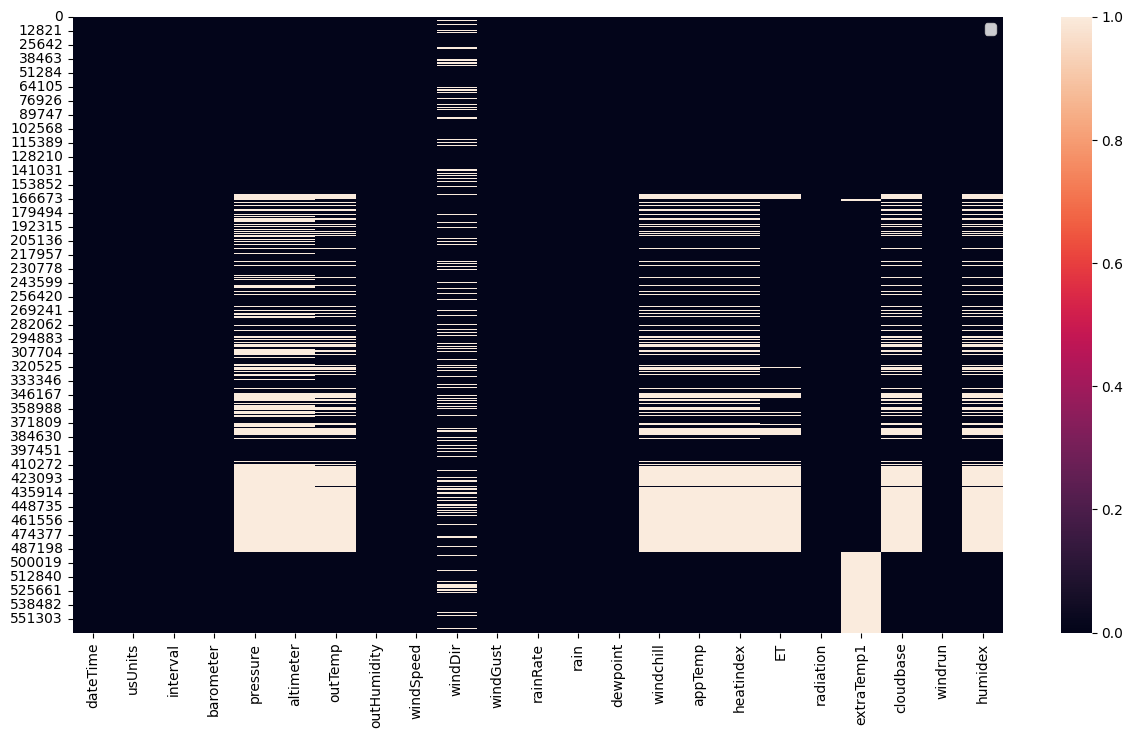

In [ ]:
sns.heatmap(meteo_data.isna())
plt.legend({1.0:'missing'})

In [ ]:
pd.concat(
    [meteo_data.count(), meteo_data.isna().sum(), ((meteo_data.isna().sum()/meteo_data.shape[0])*100).round(2)],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
dateTime,564115,0,0.00
usUnits,564115,0,0.00
interval,564115,0,0.00
barometer,564106,9,0.00
pressure,391741,172374,30.56
altimeter,391741,172374,30.56
outTemp,427593,136522,24.20
outHumidity,564106,9,0.00
windSpeed,564115,0,0.00
windDir,458500,105615,18.72


## Time

In [ ]:
meteo_data['time'] = pd.to_datetime(meteo_data["dateTime"], unit="s", utc=True)
meteo_data.head(7)

,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex,time
0,1704063607,28.122289,11.448417,1069.693466,1002.549461,1068.574185,12.663842,102.416825,11.118473,288.969291,...,12.682637,9.998148,12.708195,10.400040,10.4,12.585423,445.284266,10.443268,12.634540,2023-12-31 23:00:07+00:00
1,1704063667,27.940057,11.443831,1073.046950,1005.058712,1040.885134,12.636567,105.161522,11.115148,278.100723,...,12.572785,9.991198,12.662347,10.400041,10.4,12.594205,434.815965,10.445008,12.620366,2023-12-31 23:01:07+00:00
2,1704063727,28.237231,11.430884,1128.777787,1032.193596,1068.674938,12.669738,102.461041,11.122942,286.036262,...,12.684598,9.975972,12.754826,10.400039,10.4,12.560174,434.863894,10.442467,12.785041,2023-12-31 23:02:07+00:00
3,1704063787,28.493802,11.435472,1091.024790,1043.835644,1040.939487,12.713868,104.504860,11.129976,288.390746,...,12.734981,9.988581,12.740940,10.400040,10.4,12.561834,435.580647,10.442767,12.700933,2023-12-31 23:03:07+00:00
4,1704063847,28.160142,11.447994,1056.312488,1060.539662,1051.091724,12.769091,103.323499,11.145599,286.208564,...,12.685889,9.988616,12.815468,10.400041,10.4,12.519398,437.380130,10.442791,12.726492,2023-12-31 23:04:07+00:00
5,1704063907,28.002909,11.426826,1092.177181,1062.735102,1024.194222,12.730212,103.371117,11.140244,294.800193,...,12.789894,9.979058,12.789229,10.400038,10.4,12.579644,438.598288,10.443876,12.744336,2023-12-31 23:05:07+00:00
6,1704063967,27.965193,11.434872,1111.526058,1017.215645,1051.998496,12.855405,104.332876,11.113689,298.079972,...,12.779279,9.988623,12.688778,10.400039,10.4,12.571861,427.797648,10.443282,12.699158,2023-12-31 23:06:07+00:00


## Time frequency intervals

In [ ]:
print(meteo_data.set_index('time').resample('h').size().describe())
print('\nHead:')
display(meteo_data.set_index('time').resample('h').size().sort_values().head(15))
meteo_data.set_index('time').resample('h').size().sort_values().tail(15)

count    9403.000000
mean       59.993087
std         0.751978
min        16.000000
25%        60.000000
50%        60.000000
75%        60.000000
max       104.000000
dtype: float64

Head:


,0
time,
2024-10-27 00:00:00+00:00,16
2024-04-10 08:00:00+00:00,33
2025-01-26 17:00:00+00:00,35
2024-04-10 09:00:00+00:00,53
2024-08-10 07:00:00+00:00,54
2024-11-19 19:00:00+00:00,59
2024-06-03 08:00:00+00:00,59
2024-03-31 01:00:00+00:00,59
2024-09-17 20:00:00+00:00,60


,0
time,
2024-05-10 01:00:00+00:00,60
2024-05-10 02:00:00+00:00,60
2024-05-10 03:00:00+00:00,60
2024-05-10 12:00:00+00:00,60
2024-05-10 05:00:00+00:00,60
2024-05-10 06:00:00+00:00,60
2024-05-10 07:00:00+00:00,60
2024-05-10 08:00:00+00:00,60
2024-05-10 09:00:00+00:00,60


Check weird 104 values per minute

In [ ]:
meteo_data[(meteo_data['time'].dt.date == np.datetime64('2024-10-27')) & (meteo_data['time'].dt.hour==1)].head(50)

,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex,time
432036,1729990869,28.251757,11.462162,1081.513000,NaN,NaN,NaN,102.312135,10.400000,NaN,...,NaN,NaN,NaN,10.400056,10.4,21.557081,NaN,10.400000,NaN,2024-10-27 01:01:09+00:00
432037,1729990929,28.488686,11.488960,1053.331616,NaN,NaN,NaN,104.241387,10.400000,NaN,...,NaN,NaN,NaN,10.400056,10.4,22.011637,NaN,10.400000,NaN,2024-10-27 01:02:09+00:00
432038,1729990989,28.547511,11.456847,1116.559848,NaN,NaN,NaN,105.766514,10.400000,NaN,...,NaN,NaN,NaN,10.400057,10.4,21.991312,NaN,10.400000,NaN,2024-10-27 01:03:09+00:00
432039,1729991049,27.954351,11.440778,1031.867918,NaN,NaN,NaN,105.228780,10.400000,NaN,...,NaN,NaN,NaN,10.400055,10.4,22.087195,NaN,10.400000,NaN,2024-10-27 01:04:09+00:00
432040,1729991109,28.154686,11.432451,1107.817197,NaN,NaN,NaN,100.459010,11.013588,104.468547,...,NaN,NaN,NaN,10.400054,10.4,22.323051,NaN,10.436937,NaN,2024-10-27 01:05:09+00:00
432041,1729991168,28.170369,11.470467,1061.937448,NaN,NaN,NaN,103.411820,11.117753,105.014231,...,NaN,NaN,NaN,10.400055,10.4,22.039202,NaN,10.443398,NaN,2024-10-27 01:06:08+00:00
432042,1729991228,27.551834,11.466126,1091.116887,NaN,NaN,NaN,102.623139,11.124744,103.775822,...,NaN,NaN,NaN,10.400055,10.4,21.947873,NaN,10.443910,NaN,2024-10-27 01:07:08+00:00
432043,1729991288,27.661814,11.441252,1055.234828,NaN,NaN,NaN,106.199183,11.009928,104.544136,...,NaN,NaN,NaN,10.400059,10.4,21.724457,NaN,10.438392,NaN,2024-10-27 01:08:08+00:00
432044,1729991348,27.573597,11.454120,1068.667561,NaN,NaN,NaN,104.557286,11.016817,106.542233,...,NaN,NaN,NaN,10.400056,10.4,21.880057,NaN,10.437672,NaN,2024-10-27 01:09:08+00:00
432045,1729991408,28.136127,11.416791,1102.353341,NaN,NaN,NaN,104.308644,11.019745,103.571606,...,NaN,NaN,NaN,10.400054,10.4,22.258822,NaN,10.438210,NaN,2024-10-27 01:10:08+00:00


It looks like some values from `2024-10-27 00:00:00` might've moved to `2024-10-27 01:00:00`

## Time range of data

In [ ]:
print('We have data from:', meteo_data['time'].min(),'\nuntil:', meteo_data['time'].max())

We have data from: 2023-12-31 23:00:07+00:00 
until: 2025-01-26 17:34:02+00:00


In [ ]:
full_range = pd.DataFrame(
    index=pd.date_range(meteo_data['time'].min(),
                        meteo_data['time'].max(),
                        freq='min')
  )

print(full_range.index)
meteo_data_min = full_range.join(meteo_data, how='left').squeeze()
meteo_data_min

DatetimeIndex(['2023-12-31 23:00:07+00:00', '2023-12-31 23:01:07+00:00',
               '2023-12-31 23:02:07+00:00', '2023-12-31 23:03:07+00:00',
               '2023-12-31 23:04:07+00:00', '2023-12-31 23:05:07+00:00',
               '2023-12-31 23:06:07+00:00', '2023-12-31 23:07:07+00:00',
               '2023-12-31 23:08:07+00:00', '2023-12-31 23:09:07+00:00',
               ...
               '2025-01-26 17:24:07+00:00', '2025-01-26 17:25:07+00:00',
               '2025-01-26 17:26:07+00:00', '2025-01-26 17:27:07+00:00',
               '2025-01-26 17:28:07+00:00', '2025-01-26 17:29:07+00:00',
               '2025-01-26 17:30:07+00:00', '2025-01-26 17:31:07+00:00',
               '2025-01-26 17:32:07+00:00', '2025-01-26 17:33:07+00:00'],
              dtype='datetime64[ns, UTC]', length=564154, freq='min')


,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex,time
2023-12-31 23:00:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:01:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:02:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:03:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:04:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-01-26 17:29:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2025-01-26 17:30:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2025-01-26 17:31:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2025-01-26 17:32:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT


# Smart meter data

In [ ]:
# read all smart_meter data files and concat them

#Colab version
#all_files = glob.glob('/content/drive/MyDrive/MyCroft Data/smart_meter_data_*.csv')

#Local version
all_files = glob.glob('../../data/old_data/smart_meter_data_*.csv')


li = []

for filename in all_files:
    df = pd.read_csv(filename, index_col=None, header=0)
    li.append(df)

smart_meter_data = pd.concat(li, axis=0, ignore_index=True)
# get rid of timezone
smart_meter_data['time'] = smart_meter_data['time'].apply(lambda x: x[:-6])
# turn to datetime
smart_meter_data['time'] = pd.to_datetime(smart_meter_data['time'], infer_datetime_format =True)
# sort by 'time'
smart_meter_data.sort_values(by=['time'], inplace=True)

print('\nShape:', smart_meter_data.shape, '\n')
smart_meter_data.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_16548\515238689.py:20: UserWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  smart_meter_data['time'] = pd.to_datetime(smart_meter_data['time'], infer_datetime_format =True)



Shape: (4257624, 13) 



,time,device_id,serial_number,values_state,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,2024-01-01 00:00:01.818,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,NaN,101.053959,-635.689013,670.748839,912.812015,7788.926522,5179.064362,3565.426629,8656.644587,8767.779041
1,2024-01-01 00:00:03.671,a4b80cd7-5438-44cd-8257-c9ac81684822,d1e01b37-ad48-4df1-ad14-6e13d230b11a,NaN,580.350889,88.437225,590.806417,2087.377088,10.400000,582.029120,10.669146,2131.621335,589.340500
2,2024-01-01 00:00:05.524,2659da1f-9042-45c0-bf0a-625106aff7d1,9d57c045-ed26-4ee8-9039-302c16d8c478,NaN,88.760389,-1424.991659,1459.731053,8395.834012,5005.693161,5102.830154,7492.500722,13280.395948,12607.482568
3,2024-01-01 00:00:07.650,a806abdf-9261-4d98-abd4-a519248214f0,a39a6c1c-4992-4a91-be9b-ef9d4f411a51,NaN,10.472436,10.340116,10.496186,374.374368,10.400000,10.400000,246.197746,380.981669,10.400000
4,2024-01-01 00:00:08.667,fc529a25-d538-4c5b-b51e-2f27a3ce9f1a,0810a336-2fac-46e3-8029-57dda70375d7,NaN,10.593178,10.294157,10.629040,1111.791808,10.400000,10.400000,520.117300,1132.959947,10.400000


In [4]:
smart_meter_data.describe()

,time,values_state,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,4257624,0.0,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257624e+06,4.257624e+06
mean,2024-06-30 20:43:00.341718528,NaN,7.039240e+01,-9.137543e+00,3.225422e+02,1.386879e+03,5.783489e+02,7.538119e+02,1.069650e+03,1.954853e+03,1.776910e+03
min,2024-01-01 00:00:01.818000,NaN,-2.301026e+04,-2.361441e+03,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01
25%,2024-03-31 04:55:13.284750080,NaN,1.045980e+01,-1.047457e+02,2.254765e+01,5.907761e+02,1.040000e+01,1.352155e+01,1.102317e+02,5.907848e+02,1.992162e+02
50%,2024-06-29 13:36:02.905500160,NaN,5.759210e+01,-2.834568e+00,1.376931e+02,1.052124e+03,1.040000e+01,6.605899e+01,3.185162e+02,1.056701e+03,6.116024e+02
75%,2024-10-02 07:00:25.451500032,NaN,1.162034e+02,1.040000e+01,2.799125e+02,1.672109e+03,1.040000e+01,3.681168e+02,9.121748e+02,1.756802e+03,1.161788e+03
max,2024-12-31 23:56:01.930000,NaN,1.127072e+04,1.420497e+04,2.601259e+04,9.919320e+03,2.737583e+04,2.975262e+04,1.573584e+04,3.702078e+04,4.540840e+04
std,NaN,NaN,7.289893e+02,7.374262e+02,1.017329e+03,1.536003e+03,2.896844e+03,2.930607e+03,2.151089e+03,4.064968e+03,4.810699e+03


## Missing data

In [5]:
pd.concat(
    [smart_meter_data.count(), smart_meter_data.isna().sum(), (smart_meter_data.isna().sum()/smart_meter_data.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
time,4257624,0,0.000000
device_id,4257624,0,0.000000
serial_number,4257624,0,0.000000
values_state,0,4257624,100.000000
total_power_active,4257622,2,0.000047
total_power_reactive,4257622,2,0.000047
total_power_apparent,4257622,2,0.000047
import_energy_active,4257622,2,0.000047
export_energy_active,4257622,2,0.000047
import_energy_reactive,4257622,2,0.000047


In [6]:
smart_meter_data = smart_meter_data.drop(columns=['values_state'])

## Unique devices and serial numbers

In [7]:
print("Number of unique device ids:", len(smart_meter_data.device_id.unique()))
print("Number of unique serial numbers:", len(smart_meter_data.serial_number.unique()))

Number of unique device ids: 41
Number of unique serial numbers: 41


## Check whether each unique device_id have only one unique serial_number in smart_meter_data


In [8]:
smart_meter_data.groupby('device_id')['serial_number'].nunique().max()

np.int64(1)

Yes, so we can use device_id as primary key in our operations

## Time range of data

In [9]:
print('We have data from:', smart_meter_data['time'].min(),
      '\nuntil:', smart_meter_data['time'].max())


We have data from: 2024-01-01 00:00:01.818000 
until: 2024-12-31 23:56:01.930000


## Time frequency intervals

In [10]:
smart_meter_data.groupby('device_id')['time'].diff().describe()

count                      4257583
mean     0 days 00:05:04.516912982
std      0 days 00:17:53.101294801
min                0 days 00:00:00
25%         0 days 00:04:59.965000
50%         0 days 00:05:00.077000
75%         0 days 00:05:00.201000
max         3 days 22:58:26.201000
Name: time, dtype: object

Average interval is **5 mins**, also it appears that some meters might have latent (skipped timeseries that can't be detected by `isna()`) missing data

Thoughts..

1. We'd probably need to look at data for individual meters, so 41 different time series.
- Individual meter data readings seem to have a granulairty of 5mins
2. Meteorological data is recorded per minute.
- Need to think what is the best way to merge meteo data to meter readings.

## Do all meters have the same amount of data?

In [11]:
print(smart_meter_data.groupby('device_id')['time'].count().sort_values())
smart_meter_data.groupby('device_id')['time'].count().describe()

device_id
a2aee527-f5e2-41c1-9da0-6c4fd1b1d4ba    103515
114b44b0-0dc4-45d6-a4ac-83223ea9b2d8    103738
a806abdf-9261-4d98-abd4-a519248214f0    103772
615c3df8-9ef6-4aa1-994a-87c2a7ffa0cc    103785
b14559e0-1c2e-417e-a736-f92a39bec0db    103850
8e0a1d6f-8ba6-4d0c-a025-378ace0f7291    103857
12db0eaf-e9e5-4cb5-849c-3289ef475f02    103857
84faf80e-e9d5-4552-b919-fbb8df7c7e4a    103858
4ad3e3e6-5f11-4923-a88d-668b4ddb493a    103859
4a448440-d2dd-4b27-ae02-87e7e3baa9f5    103859
61be69b4-a02a-48f8-8431-d4f07aad36d2    103859
1540b469-3e7e-4e8e-89fb-a1aceaf8dbd6    103859
265064b5-79b8-4436-8bc7-3f24062d73c3    103859
478e1210-ead4-4d55-9d35-c1090fbeb354    103859
3f3f551c-6594-4098-b9b4-af9ac4ab606c    103859
021ebc46-e284-461a-92bb-6236c7768774    103859
a5a90155-e8a3-473e-a709-3a1ae21c9a93    103859
69a3bfa0-e8e6-41be-8c42-65e899a37794    103859
62c4699f-2e30-494b-a945-0801ccaf7bf9    103859
8f361e91-54a8-4f05-bab5-a672fc9d82b6    103859
8f3a5182-51f7-4a43-a580-f272cd1c4481    103859
51c

count        41.000000
mean     103844.487805
std          58.665203
min      103515.000000
25%      103859.000000
50%      103859.000000
75%      103862.000000
max      103864.000000
Name: time, dtype: float64

No, most meters have 103_859 entries, but the others vary

## Min-Max range of each meter

In [12]:
smart_meter_data.groupby('device_id')['time'].agg(['min', 'max']).sort_values('min')

,min,max
device_id,,
e7803808-8743-4f1d-8c15-3d574a4bdf7c,2024-01-01 00:00:01.818,2024-12-31 23:55:47.715
a4b80cd7-5438-44cd-8257-c9ac81684822,2024-01-01 00:00:03.671,2024-12-31 23:55:49.355
2659da1f-9042-45c0-bf0a-625106aff7d1,2024-01-01 00:00:05.524,2024-12-31 23:55:51.017
a806abdf-9261-4d98-abd4-a519248214f0,2024-01-01 00:00:07.650,2024-12-31 23:55:53.778
fc529a25-d538-4c5b-b51e-2f27a3ce9f1a,2024-01-01 00:00:08.667,2024-12-31 23:55:54.858
3617dc75-38d4-4875-b66c-64f896b5c9f1,2024-01-01 00:00:11.628,2024-12-31 23:55:52.684
c72b9342-827b-484c-a16a-1b4019f47720,2024-01-01 00:00:13.653,2024-12-31 23:55:55.863
231e45ef-ca7a-4f80-be11-ac7e2da0274c,2024-01-01 00:00:14.671,2024-12-31 23:55:56.903
947ed086-5ce2-436f-bf18-aaabac14e71d,2024-01-01 00:00:15.588,2024-12-31 23:55:57.908


Almost each meter:
- starts at `2024-01-01 00:00:00`;
- ends at `2024-12-31 23:55:46`.

## Statistics on `total_power_active` per device

In [13]:
smart_meter_data.groupby('device_id')['total_power_active'].describe()

,count,mean,std,min,25%,50%,75%,max
device_id,,,,,,,,
021ebc46-e284-461a-92bb-6236c7768774,103858.0,101.160792,1.657201e+02,10.400000,10.400000,10.400000,136.044042,3426.903774
114b44b0-0dc4-45d6-a4ac-83223ea9b2d8,103738.0,201.687251,3.957245e+02,10.400000,23.901765,113.749702,196.452904,5368.669596
12db0eaf-e9e5-4cb5-849c-3289ef475f02,103857.0,95.665347,2.636981e+02,10.400000,10.400000,67.367261,94.617985,6177.860642
1540b469-3e7e-4e8e-89fb-a1aceaf8dbd6,103859.0,110.080167,2.505501e+02,10.400000,37.655626,46.951586,108.420233,5861.693932
231e45ef-ca7a-4f80-be11-ac7e2da0274c,103862.0,10.422787,4.101484e-02,10.400000,10.400000,10.400000,10.462114,11.246444
25069c83-3ab8-40a0-b396-df8ed85db621,103864.0,10.400001,3.180531e-04,10.400000,10.400000,10.400000,10.400000,10.502502
265064b5-79b8-4436-8bc7-3f24062d73c3,103859.0,182.951348,4.010914e+02,20.219118,65.854334,87.976504,165.061921,7690.562498
2659da1f-9042-45c0-bf0a-625106aff7d1,103862.0,-2219.577551,3.512300e+03,-23010.263048,-4097.246077,45.622311,102.701109,6121.439983
2c55f2fe-8dfd-4fb2-a838-d5717b9f1488,103859.0,113.305659,2.969447e+02,10.400000,48.738667,52.569584,107.526550,7738.513125


## Summary for some meters

Insights:
- All meters we checked have **missing data in September (especially from 14th till 18th)** and a bit in other parts. We would link this with flood that happened in Central Europe around that time.
- All meters we checked have duplicated data mostly on **27th of October at 2 AM**
- Most meters have minimum value around **10.40**, which might state the power consumption in inactivity (rest)

The table of meters we pick for experiments:
1. `f90e7387-9810-408d-885b-6f3841f4ec3f` - has very high peaks with high deviation
2. `dd40019b-5b35-4fba-b0dd-16083c1fdb84` - has high peaks with high average std
3. `3617dc75-38d4-4875-b66c-64f896b5c9f1` - has very high peaks and quite high mean power
4. `a4b80cd7-5438-44cd-8257-c9ac81684822` - has the highest mean value and comparably non-volatile deviation with few peaks
5. `522e56a5-ff0c-4ece-923f-a925aabe15e6` - has high peaks with average deviation
6. `4a448440-d2dd-4b27-ae02-87e7e3baa9f5` - has high mean with high deviation and peaks
7. `fca96b30-ca2f-41b8-b987-3207af296b03` - has average mean with with high deviation and peaks
8. `4ad3e3e6-5f11-4923-a88d-668b4ddb493a` - has average mean and quite stable (as for this dataset) deviation with high peaks

Exceptions:
1. `2659da1f-9042-45c0-bf0a-625106aff7d1` - has very low negative values with combination of high peaks
2. `231e45ef-ca7a-4f80-be11-ac7e2da0274c` - has very small std with mean value around 10.42
3. `a806abdf-9261-4d98-abd4-a519248214f0` - has very small std with mean value around 10.48
4. `c72b9342-827b-484c-a16a-1b4019f47720` - has very small std with mean value around 10.4
5. `fc529a25-d538-4c5b-b51e-2f27a3ce9f1a` - has very small std with mean value around 10.6

`export_energy_active` mostly has 0 std, but not for device *2659da1f-9042-45c0-bf0a-625106aff7d1*

## EDA on chosen smart-meters list

In [14]:
device_list = [
    "f90e7387-9810-408d-885b-6f3841f4ec3f",
    "dd40019b-5b35-4fba-b0dd-16083c1fdb84",
    "3617dc75-38d4-4875-b66c-64f896b5c9f1",
    "a4b80cd7-5438-44cd-8257-c9ac81684822",
    "522e56a5-ff0c-4ece-923f-a925aabe15e6",
    "4a448440-d2dd-4b27-ae02-87e7e3baa9f5",
    "fca96b30-ca2f-41b8-b987-3207af296b03",
    "4ad3e3e6-5f11-4923-a88d-668b4ddb493a",
    ]

In [15]:
# Create a dictionary to store data for each device for later comparison
meter_data_dict = {}

# Loop through each device in our selected list
for device_id in device_list:
    print(f"\n\n### Analyzing device: {device_id} ###")
    
    # Select the meter data for this device
    meter_data = smart_meter_data[smart_meter_data.device_id == device_id].sort_values('time').reset_index()
    meter_data = meter_data.drop(columns=['device_id', 'serial_number'])
    
    # Store in dictionary for later comparison
    meter_data_dict[device_id] = meter_data
    
    # Display basic info
    print(f"Data points: {len(meter_data)}")
    display(meter_data.head())



### Analyzing device: f90e7387-9810-408d-885b-6f3841f4ec3f ###
Data points: 103859


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,17,2024-01-01 00:00:29.381,177.644744,84.944388,221.970227,404.398339,10.4,277.659595,98.007170,415.962979,367.277117
1,58,2024-01-01 00:05:29.341,85.261896,-23.435115,142.292339,412.293572,10.4,276.419701,97.455696,411.893720,375.804478
2,99,2024-01-01 00:10:29.521,95.377396,-25.626494,146.176407,406.901530,10.4,275.817663,97.683132,407.445887,363.624210
3,140,2024-01-01 00:15:29.749,105.276273,-32.959025,155.832504,405.084261,10.4,273.574805,96.502109,401.018009,371.288807
4,181,2024-01-01 00:20:28.859,95.264861,-27.596574,155.083922,415.449790,10.4,272.612742,97.912459,414.731490,365.543901




### Analyzing device: dd40019b-5b35-4fba-b0dd-16083c1fdb84 ###
Data points: 103859


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,29,2024-01-01 00:00:50.985,65.149522,-141.117291,220.067460,425.129749,10.4,18.961278,606.762319,418.712426,620.942245
1,70,2024-01-01 00:05:51.029,18.577548,-134.087162,158.031992,423.955993,10.4,19.089873,615.805616,420.381735,622.296338
2,111,2024-01-01 00:10:51.258,18.202294,-132.736354,160.488283,424.825633,10.4,19.437516,593.121131,404.003164,626.998931
3,152,2024-01-01 00:15:51.436,58.270204,-138.086229,181.365666,423.863933,10.4,19.082839,630.521735,420.035549,609.963978
4,193,2024-01-01 00:20:50.549,56.075361,-144.970581,187.939555,408.913204,10.4,18.915928,598.448509,414.623675,635.948163




### Analyzing device: 3617dc75-38d4-4875-b66c-64f896b5c9f1 ###
Data points: 103862


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,5,2024-01-01 00:00:11.628,90.100574,-655.444129,686.285608,597.474627,10.4,13.649792,3351.489662,604.190251,3186.048769
1,46,2024-01-01 00:05:11.738,88.018299,-641.198599,690.755957,611.970251,10.4,13.664991,3290.936090,607.138700,3377.829974
2,87,2024-01-01 00:10:11.819,127.904977,-641.230588,686.566910,612.148902,10.4,13.565224,3273.739130,616.818467,3227.265864
3,128,2024-01-01 00:15:12.098,90.556367,-631.235416,699.147159,601.101614,10.4,13.731646,3309.657594,612.620233,3365.437816
4,169,2024-01-01 00:20:11.159,91.070036,-658.426492,690.739356,594.177714,10.4,13.556265,3330.913546,606.414804,3202.198845


... (6 outputs left out)



### Analyzing device: fca96b30-ca2f-41b8-b987-3207af296b03 ###
Data points: 103859


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,36,2024-01-01 00:01:03.607,175.702369,102.403440,204.872368,514.148158,10.4,291.374642,93.061456,510.603865,382.140383
1,77,2024-01-01 00:06:03.699,44.473761,-27.832070,73.118245,531.732724,10.4,297.886516,91.604968,518.059074,392.147923
2,118,2024-01-01 00:11:03.880,44.547307,-25.912703,74.550075,519.463261,10.4,300.201496,89.606260,518.310100,382.131728
3,159,2024-01-01 00:16:04.156,114.411074,107.618188,161.911073,539.415645,10.4,300.665106,93.347268,524.772173,385.067708
4,200,2024-01-01 00:21:03.171,157.706987,177.941257,229.293445,532.114614,10.4,297.534738,94.036965,508.925348,392.201114




### Analyzing device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a ###
Data points: 103859


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,39,2024-01-01 00:01:09.017,29.928655,-52.876529,89.552776,445.139434,10.4,25.370610,321.612998,433.325804,328.505192
1,80,2024-01-01 00:06:09.157,25.839230,-54.941689,85.475720,435.598357,10.4,25.303991,320.246335,439.188136,337.050497
2,121,2024-01-01 00:11:09.288,25.990540,-53.226304,83.618588,435.411454,10.4,25.693356,328.549131,442.444995,337.744824
3,162,2024-01-01 00:16:09.515,25.792384,-54.064227,85.345687,433.264465,10.4,25.556668,309.942046,433.159195,335.654964
4,203,2024-01-01 00:21:08.528,25.648472,-52.424351,83.901250,425.781692,10.4,25.370704,321.107005,434.077353,324.786357


In [16]:
# Display descriptive statistics for each meter
for device_id, meter_data in meter_data_dict.items():
    print(f"\n\n### Statistics for device: {device_id} ###")
    display(meter_data.describe())



### Statistics for device: f90e7387-9810-408d-885b-6f3841f4ec3f ###


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,1.038590e+05,103859,103859.000000,103859.000000,103859.000000,103859.000000,1.038590e+05,103859.000000,103859.000000,103859.000000,103859.000000
mean,2.128845e+06,2024-06-30 20:47:40.215042048,92.887988,35.912339,143.710498,758.486653,1.040000e+01,494.118990,200.865263,758.589713,684.595648
min,1.700000e+01,2024-01-01 00:00:29.381000,10.400000,-39.869715,40.492088,383.510167,1.040000e+01,260.496163,92.481603,379.304667,347.312979
25%,1.064520e+06,2024-03-31 05:07:59.272999936,10.400000,-12.574050,56.067967,577.420624,1.040000e+01,379.570476,151.161859,577.051147,519.961871
50%,2.128793e+06,2024-06-29 13:35:29.449999872,75.573228,-10.968860,118.364106,744.911071,1.040000e+01,487.727420,201.398179,745.375758,678.600238
75%,3.193268e+06,2024-10-02 07:07:38.540999936,112.004873,94.858376,170.800745,945.042271,1.040000e+01,611.806852,250.969950,945.289645,852.435366
max,4.257587e+06,2024-12-31 23:55:08.069000,7110.704833,1288.326740,7171.800728,1191.272314,1.040000e+01,750.554440,320.444273,1196.113862,1065.931411
std,1.229029e+06,NaN,233.414147,74.176473,240.852601,208.847129,5.329096e-15,129.038881,58.810053,208.915451,187.910442




### Statistics for device: dd40019b-5b35-4fba-b0dd-16083c1fdb84 ###


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,1.038590e+05,103859,103859.000000,103859.000000,103859.000000,103859.000000,1.038590e+05,103859.000000,103859.000000,103859.000000,103859.000000
mean,2.128857e+06,2024-06-30 20:48:01.230077952,66.601097,-122.904247,196.145868,674.196927,1.040000e+01,26.299556,1199.324847,674.226266,1215.138302
min,2.900000e+01,2024-01-01 00:00:50.985000,10.400000,-512.482329,79.502035,395.475370,1.040000e+01,18.504244,574.962126,391.095378,576.836981
25%,1.064532e+06,2024-03-31 05:08:20.963000064,22.869239,-130.373248,153.802884,554.389432,1.040000e+01,22.245115,909.871170,554.482169,921.701409
50%,2.128805e+06,2024-06-29 13:35:51.184999936,38.722470,-125.423562,165.345935,662.363423,1.040000e+01,26.229098,1193.398804,662.279261,1208.761935
75%,3.193280e+06,2024-10-02 07:07:58.430000128,66.950476,-120.119583,205.845461,802.150310,1.040000e+01,30.219138,1500.188079,802.381310,1520.345141
max,4.257599e+06,2024-12-31 23:55:27.973000,5206.982548,1543.440685,5289.503896,1016.053740,1.040000e+01,36.873375,1942.456676,1019.072891,1936.370804
std,1.229029e+06,NaN,198.242876,42.185186,197.454241,148.850202,5.329096e-15,4.607076,341.962503,148.860326,346.529697




### Statistics for device: 3617dc75-38d4-4875-b66c-64f896b5c9f1 ###


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,1.038620e+05,103862,103862.000000,103862.000000,103862.000000,103862.000000,1.038620e+05,103862.000000,103862.000000,103862.000000,103862.000000
mean,2.128871e+06,2024-06-30 20:51:04.428714752,130.678838,-646.963223,735.353844,1120.101938,1.040000e+01,16.636955,6165.902359,1120.092912,6171.853846
min,5.000000e+00,2024-01-01 00:00:11.628000,70.888051,-748.247567,602.785321,561.284548,1.040000e+01,13.471519,3105.046165,558.414339,3100.895394
25%,1.064538e+06,2024-03-31 05:11:26.206000128,88.635898,-662.193289,684.331989,855.856505,1.040000e+01,15.110484,4721.936590,855.809272,4725.264096
50%,2.128842e+06,2024-06-29 13:42:41.756999936,90.452918,-649.918897,697.119061,1113.187448,1.040000e+01,16.653082,6151.154431,1113.727784,6150.635095
75%,3.193265e+06,2024-10-02 07:04:38.168749824,106.318233,-637.872785,711.646815,1390.469894,1.040000e+01,18.195302,7630.700622,1390.794243,7636.120089
max,4.257614e+06,2024-12-31 23:55:52.684000,10907.441055,1388.227720,14331.132103,1746.422131,1.040000e+01,20.162209,9576.892962,1748.839186,9634.321256
std,1.229035e+06,NaN,342.072496,57.754791,422.583705,304.725996,5.329096e-15,1.749642,1671.748639,304.738754,1673.086251


... (6 outputs left out)



### Statistics for device: fca96b30-ca2f-41b8-b987-3207af296b03 ###


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,1.038590e+05,103859,103859.000000,103859.000000,103859.000000,103859.000000,1.038590e+05,103859.000000,103859.000000,103859.000000,103859.000000
mean,2.128864e+06,2024-06-30 20:48:13.455726592,115.829059,60.836256,152.950255,968.090748,1.040000e+01,574.239431,151.722052,968.208447,715.532631
min,3.600000e+01,2024-01-01 00:01:03.607000,18.778465,-136.662298,34.762610,486.449383,1.040000e+01,288.212741,88.900239,492.533534,365.583762
25%,1.064538e+06,2024-03-31 05:08:33.612000,21.432082,-15.817936,41.545320,740.038105,1.040000e+01,435.176491,124.924178,740.492640,549.608941
50%,2.128812e+06,2024-06-29 13:36:03.807000064,91.377286,47.689198,143.917491,963.309026,1.040000e+01,569.663372,152.641569,964.043516,711.604529
75%,3.193288e+06,2024-10-02 07:08:09.964999936,140.394815,121.026776,177.509189,1193.856315,1.040000e+01,719.534335,177.786748,1193.520655,887.080080
max,4.257606e+06,2024-12-31 23:55:39.468000,6732.355572,1004.502650,6612.525758,1525.819743,1.040000e+01,908.737027,220.077538,1526.949062,1113.848357
std,1.229029e+06,NaN,244.029613,76.312206,248.093383,260.431625,5.329096e-15,158.437309,32.505582,260.424036,190.815580




### Statistics for device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a ###


,index,time,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,1.038590e+05,103859,103859.000000,103859.000000,103859.000000,103859.000000,1.038590e+05,103859.000000,103859.000000,103859.000000,103859.000000
mean,2.128867e+06,2024-06-30 20:48:18.674403328,96.010217,-44.109462,149.854991,797.852979,1.040000e+01,37.551939,573.584799,797.799259,600.698132
min,3.900000e+01,2024-01-01 00:01:09.017000,19.665017,-111.839969,56.151629,413.412400,1.040000e+01,24.456272,297.575423,417.639001,309.694806
25%,1.064542e+06,2024-03-31 05:08:39.046499840,21.345874,-53.666174,79.182869,607.021363,1.040000e+01,31.922802,447.971740,607.267330,469.332102
50%,2.128815e+06,2024-06-29 13:36:09.164999936,97.122076,-48.781814,146.848616,780.396638,1.040000e+01,36.558654,574.205609,780.370975,600.412293
75%,3.193290e+06,2024-10-02 07:08:14.888000,115.058861,-33.664684,165.530125,996.810212,1.040000e+01,44.138207,703.889856,996.877045,737.544570
max,4.257609e+06,2024-12-31 23:55:44.399000,4660.629628,1130.038994,4581.160999,1270.018738,1.040000e+01,50.750575,868.206086,1261.329709,910.132085
std,1.229029e+06,NaN,181.059220,41.582069,185.250993,221.342354,5.329096e-15,6.917671,146.352770,221.249999,153.296919


### Comparison of `total_power_active` in meters

In [17]:
# Create a comparison dataframe for key statistics
comparison_stats = []

for device_id, meter_data in meter_data_dict.items():
    stats = {
        'device_id': device_id[:8],  # Truncated ID for readability
        'mean_power': meter_data['total_power_active'].mean(),
        'max_power': meter_data['total_power_active'].max(),
        'std_power': meter_data['total_power_active'].std(),
        'data_points': len(meter_data),
        'missing_ratio': meter_data.isna().mean().mean()
    }
    comparison_stats.append(stats)

comparison_df = pd.DataFrame(comparison_stats)
display(comparison_df)

,device_id,mean_power,max_power,std_power,data_points,missing_ratio
0,f90e7387,92.887988,7110.704833,233.414147,103859,0.0
1,dd40019b,66.601097,5206.982548,198.242876,103859,0.0
2,3617dc75,130.678838,10907.441055,342.072496,103862,0.0
3,a4b80cd7,423.603814,1353.607875,151.028616,103862,0.0
4,522e56a5,233.997712,7439.307046,540.619173,103859,0.0
5,4a448440,195.916489,6223.864815,469.062641,103859,0.0
6,fca96b30,115.829059,6732.355572,244.029613,103859,0.0
7,4ad3e3e6,96.010217,4660.629628,181.059220,103859,0.0


C:\Users\HP\AppData\Local\Temp\ipykernel_16548\3268471562.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
C:\Users\HP\AppData\Local\Temp\ipykernel_16548\3268471562.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
C:\Users\HP\AppData\Local\Temp\ipykernel_16548\3268471562.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45)


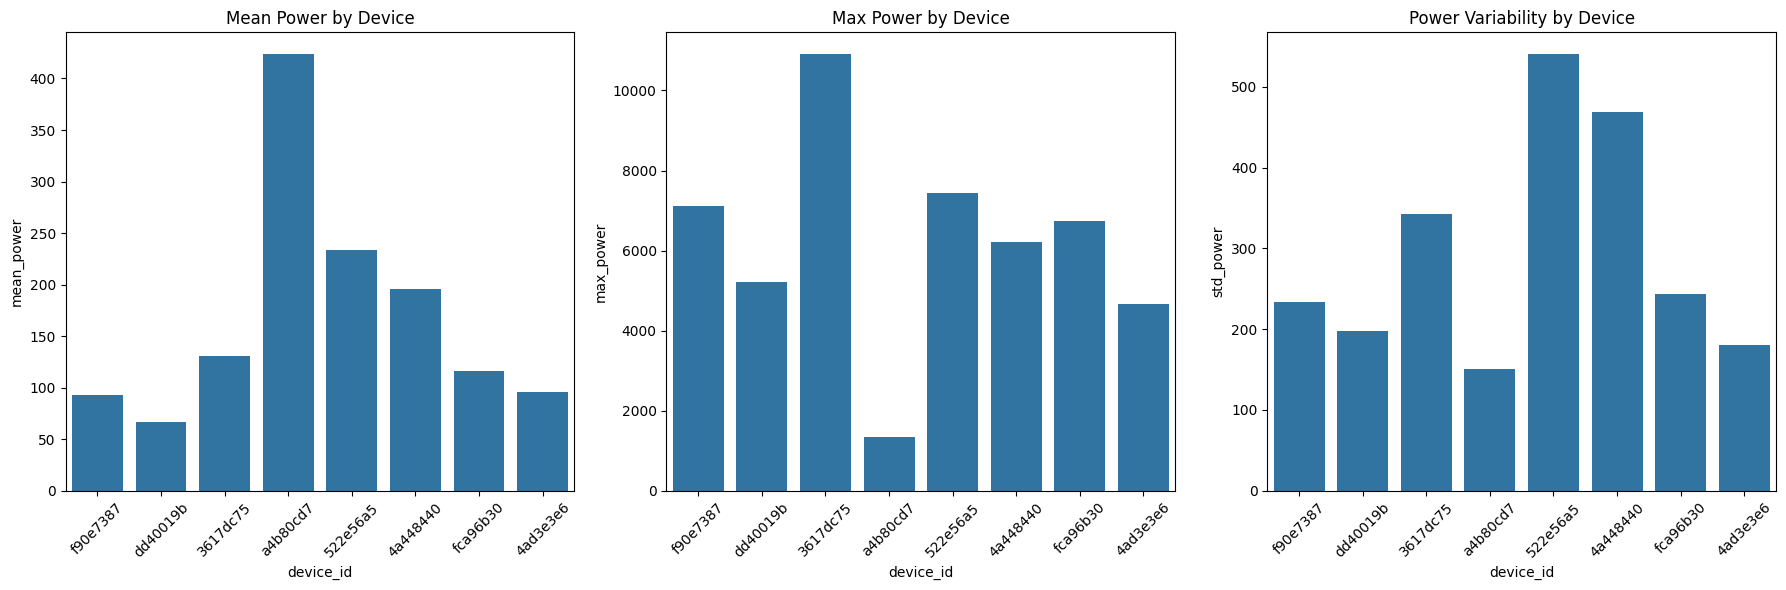

In [18]:
# Visualize the comparison statistics
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Mean power comparison
sns.barplot(x='device_id', y='mean_power', data=comparison_df, ax=axes[0])
axes[0].set_title('Mean Power by Device')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

# Max power comparison
sns.barplot(x='device_id', y='max_power', data=comparison_df, ax=axes[1])
axes[1].set_title('Max Power by Device')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)

# Standard deviation comparison
sns.barplot(x='device_id', y='std_power', data=comparison_df, ax=axes[2])
axes[2].set_title('Power Variability by Device')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

### Correlation analysis

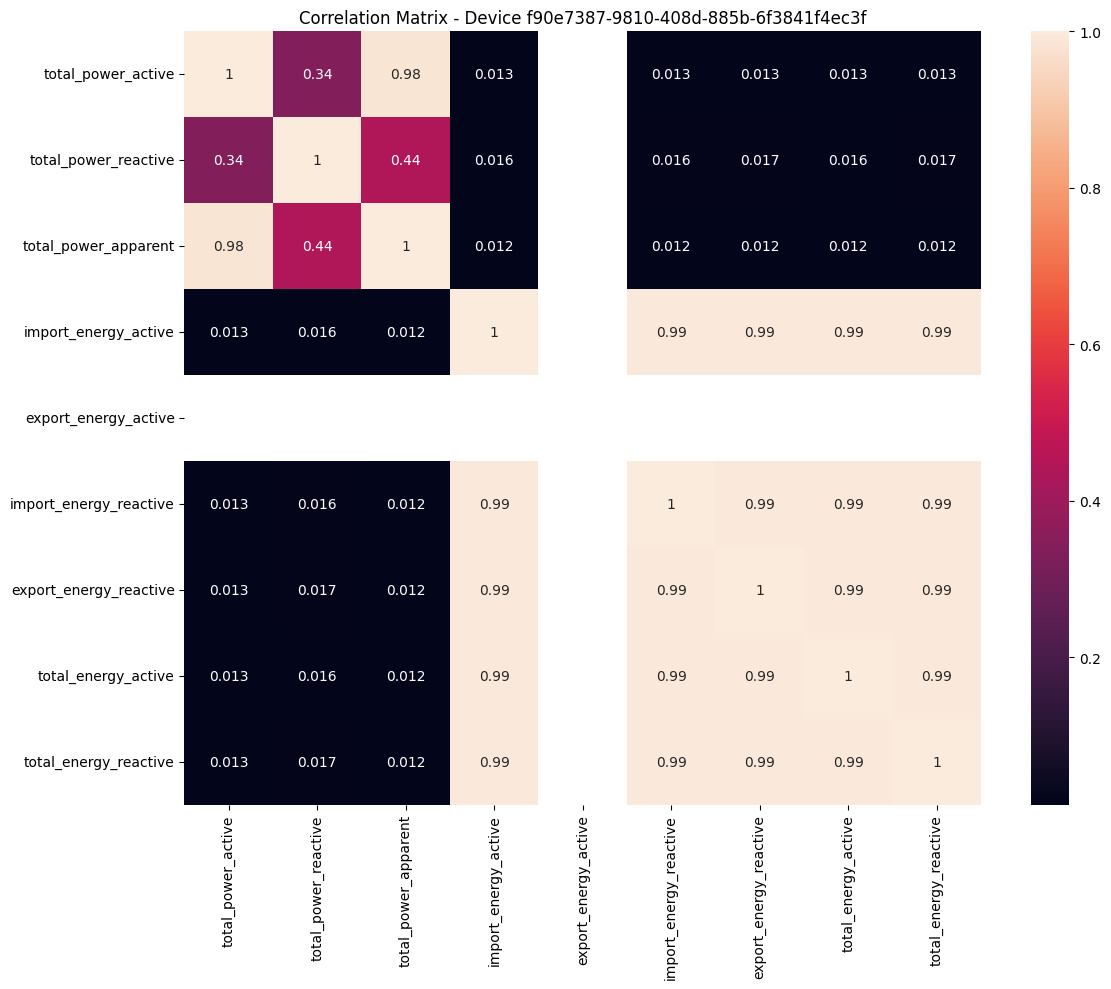

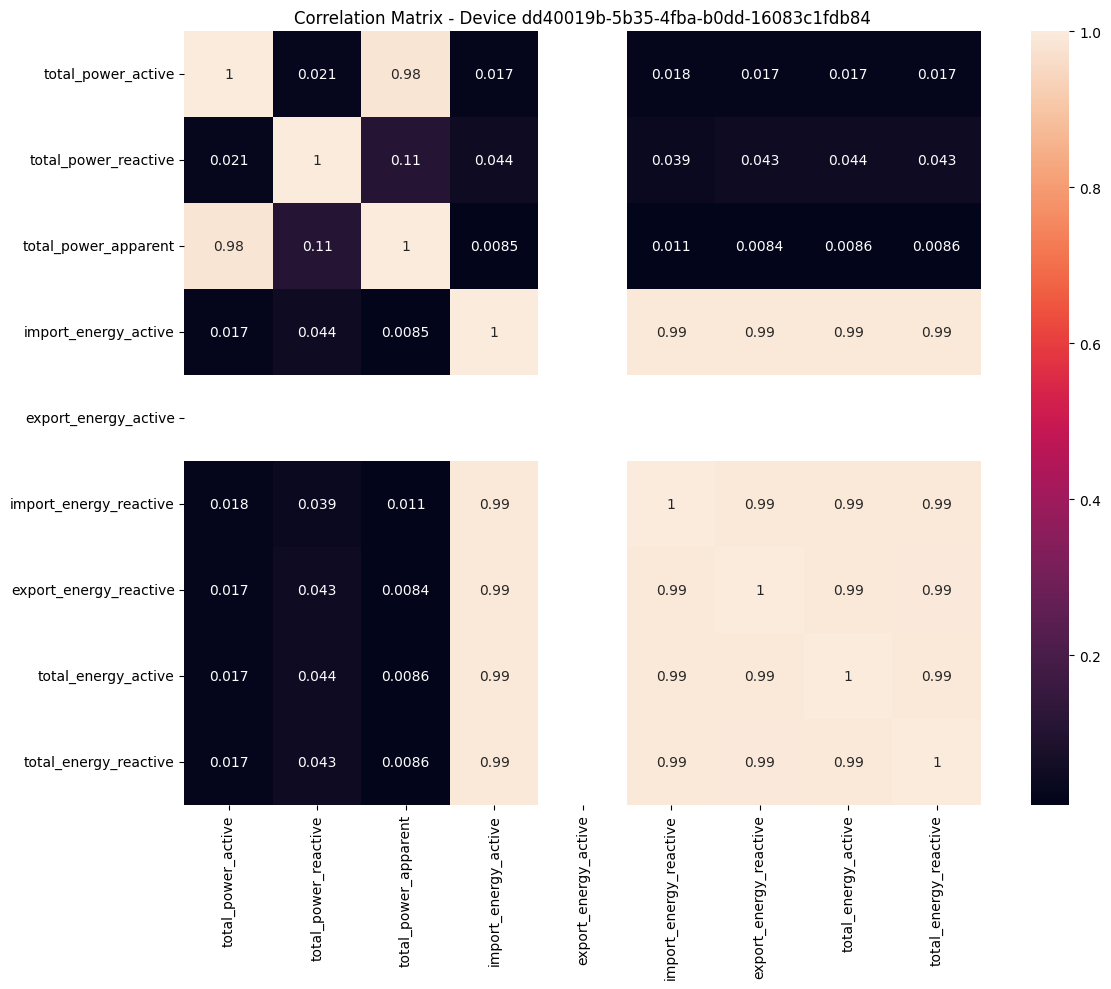

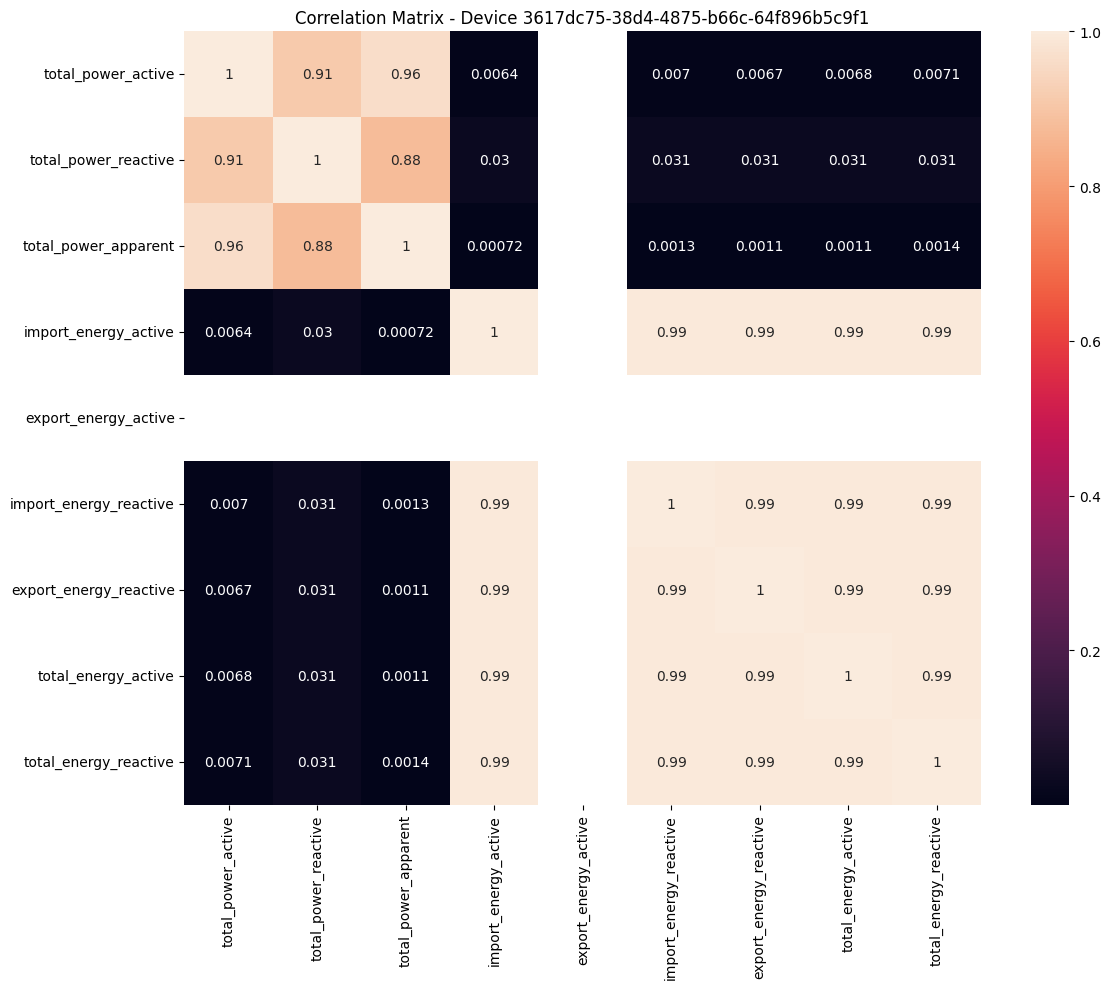

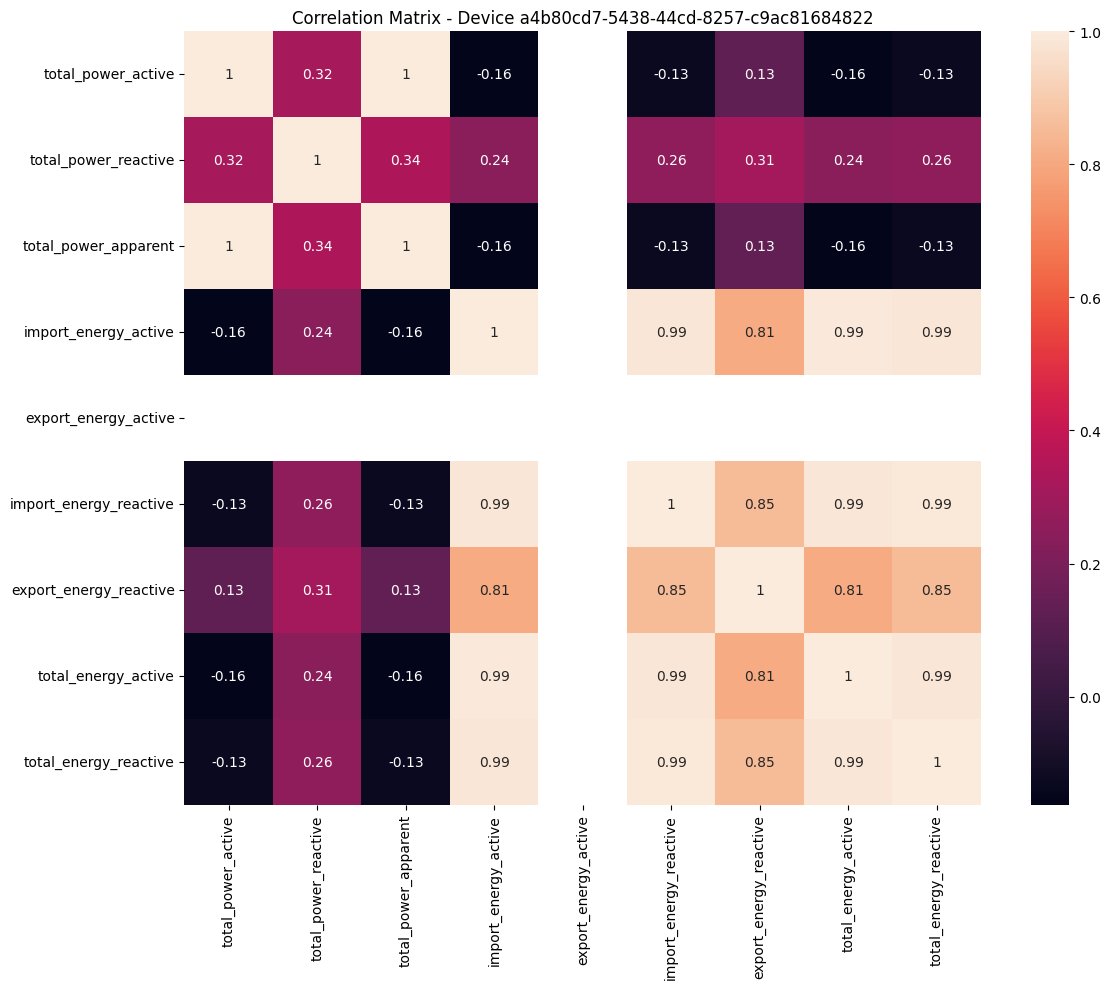

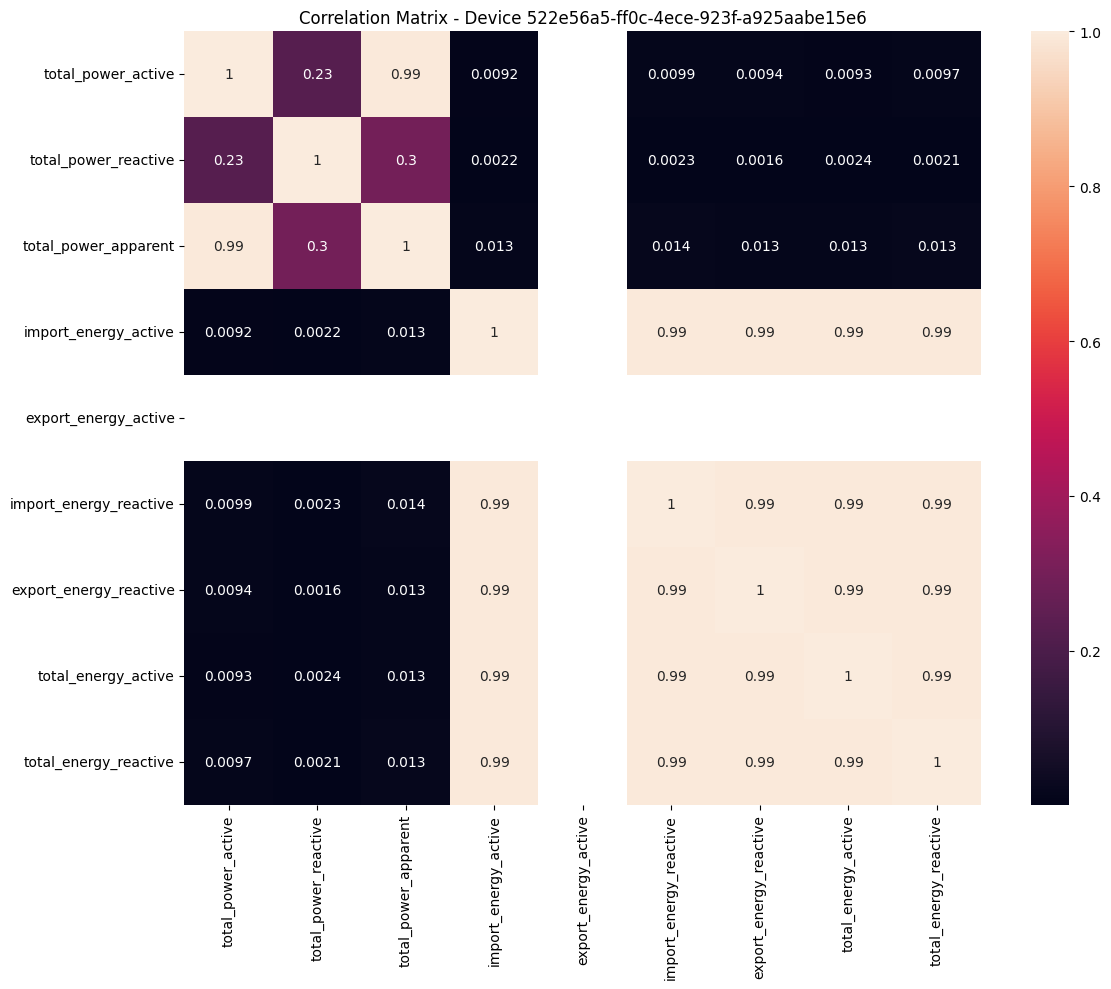

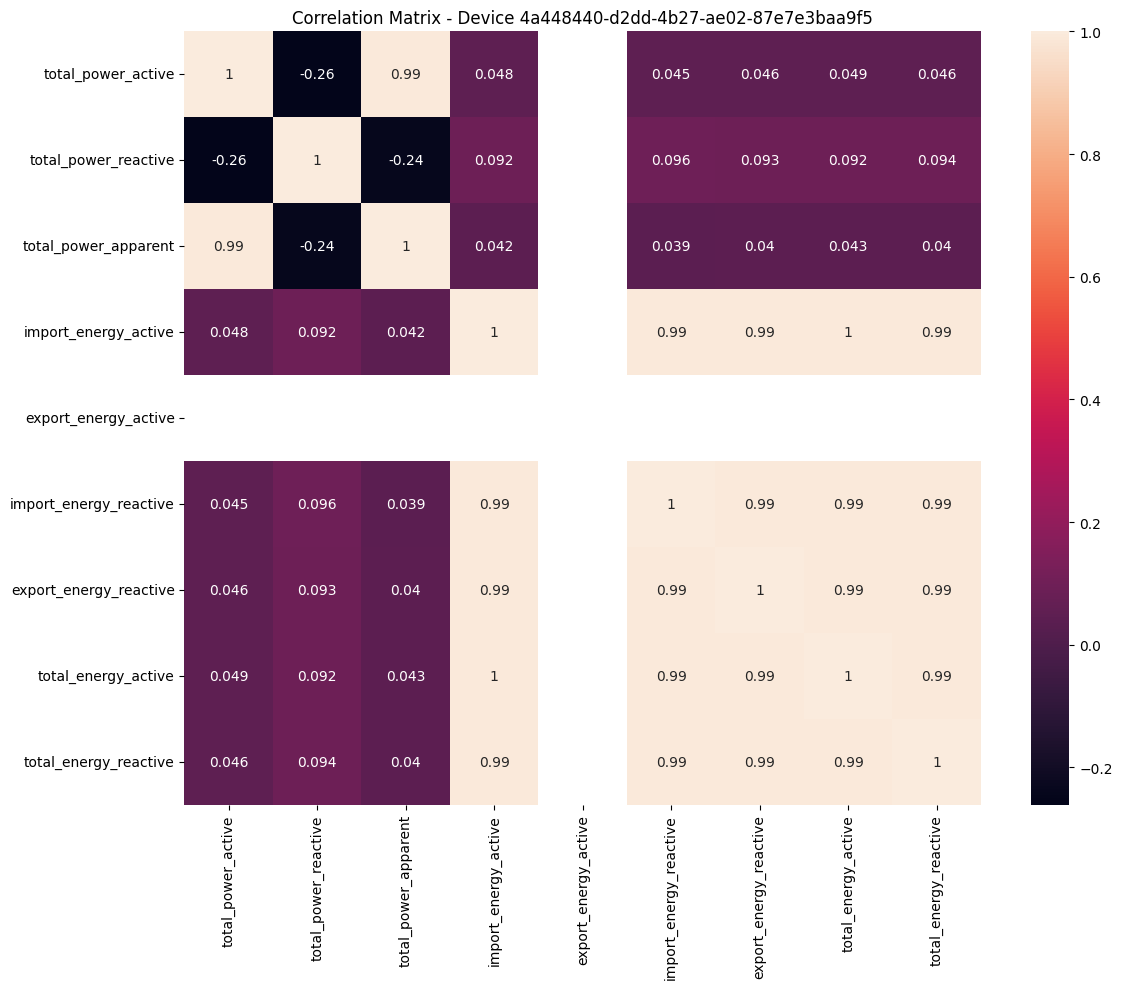

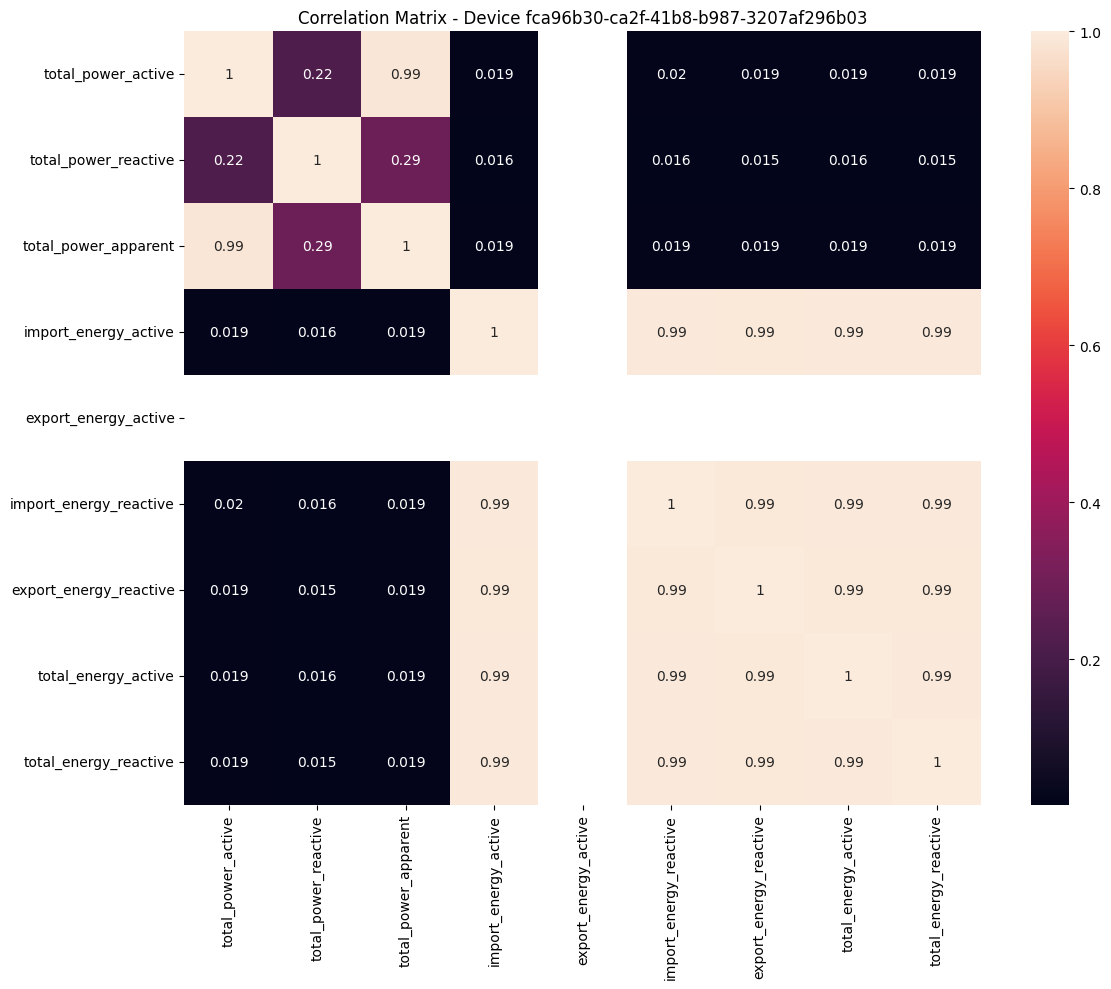

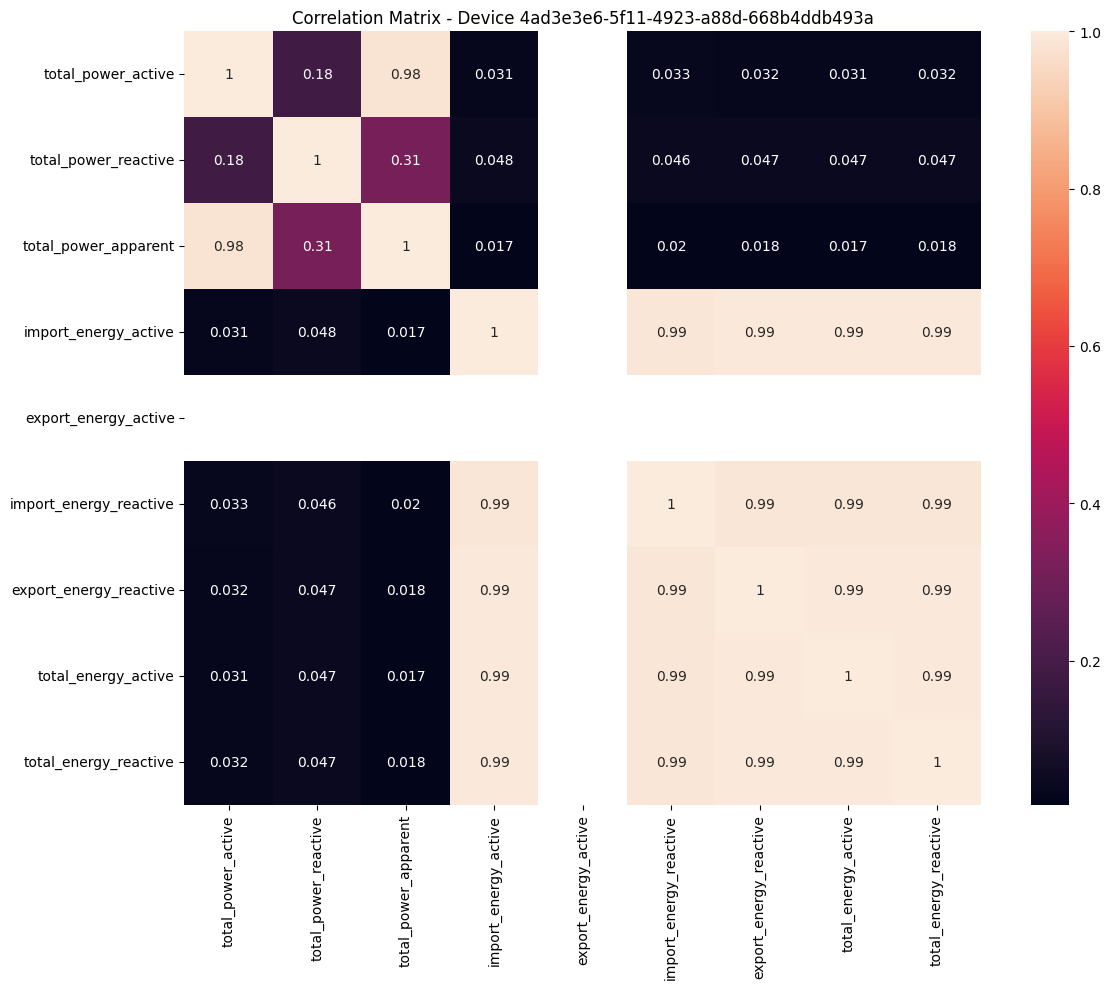

In [19]:
for device_id, meter_data in meter_data_dict.items():
    plt.figure(figsize=(12, 10))
    sns.heatmap(meter_data.drop(columns=['index', 'time']).fillna('median').corr(), annot=True)
    plt.title(f"Correlation Matrix - Device {device_id}")
    plt.tight_layout()
    plt.show()

### Power consumption comparison across meters

<Figure size 1500x600 with 0 Axes>

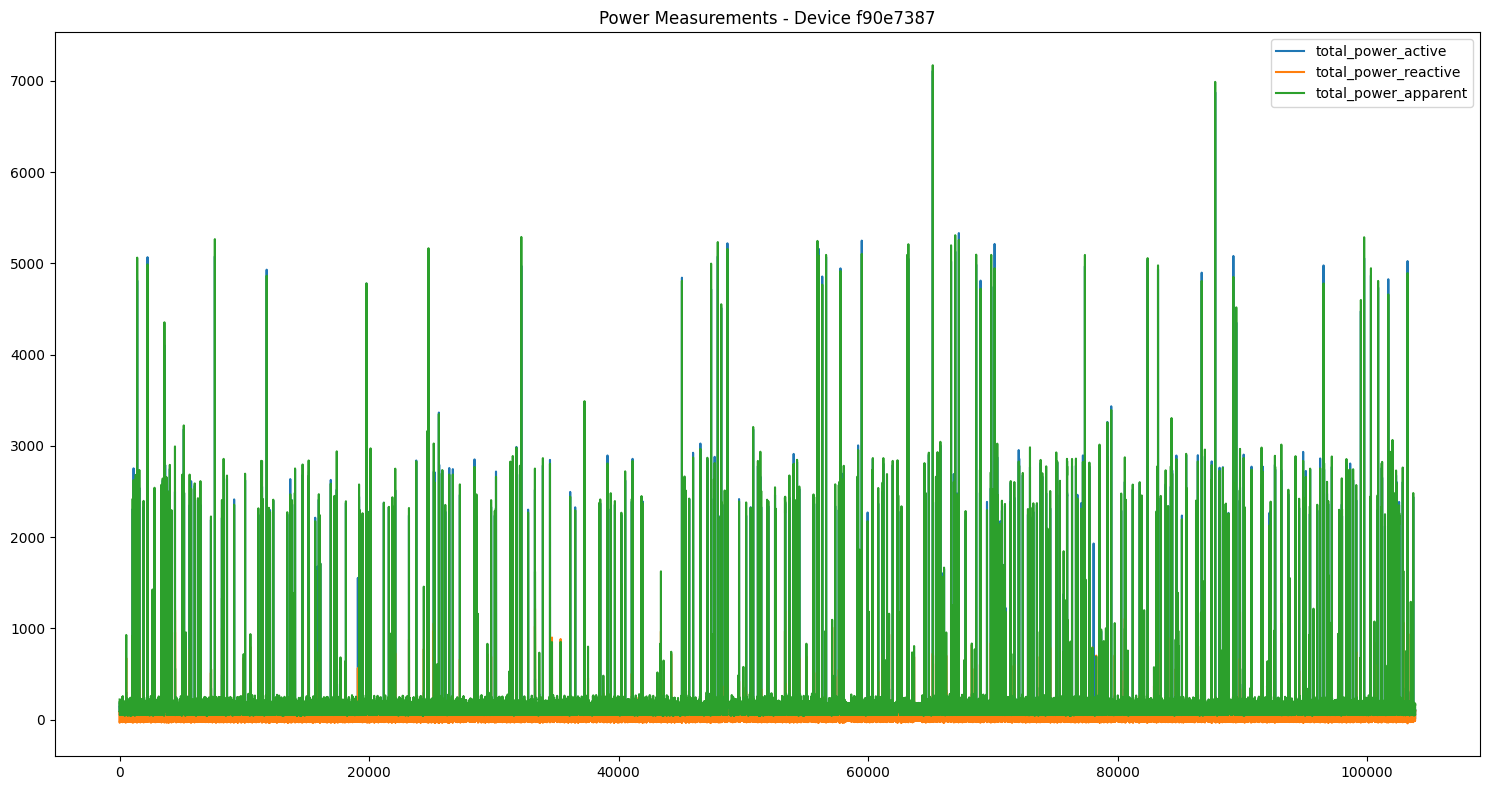

<Figure size 1500x600 with 0 Axes>

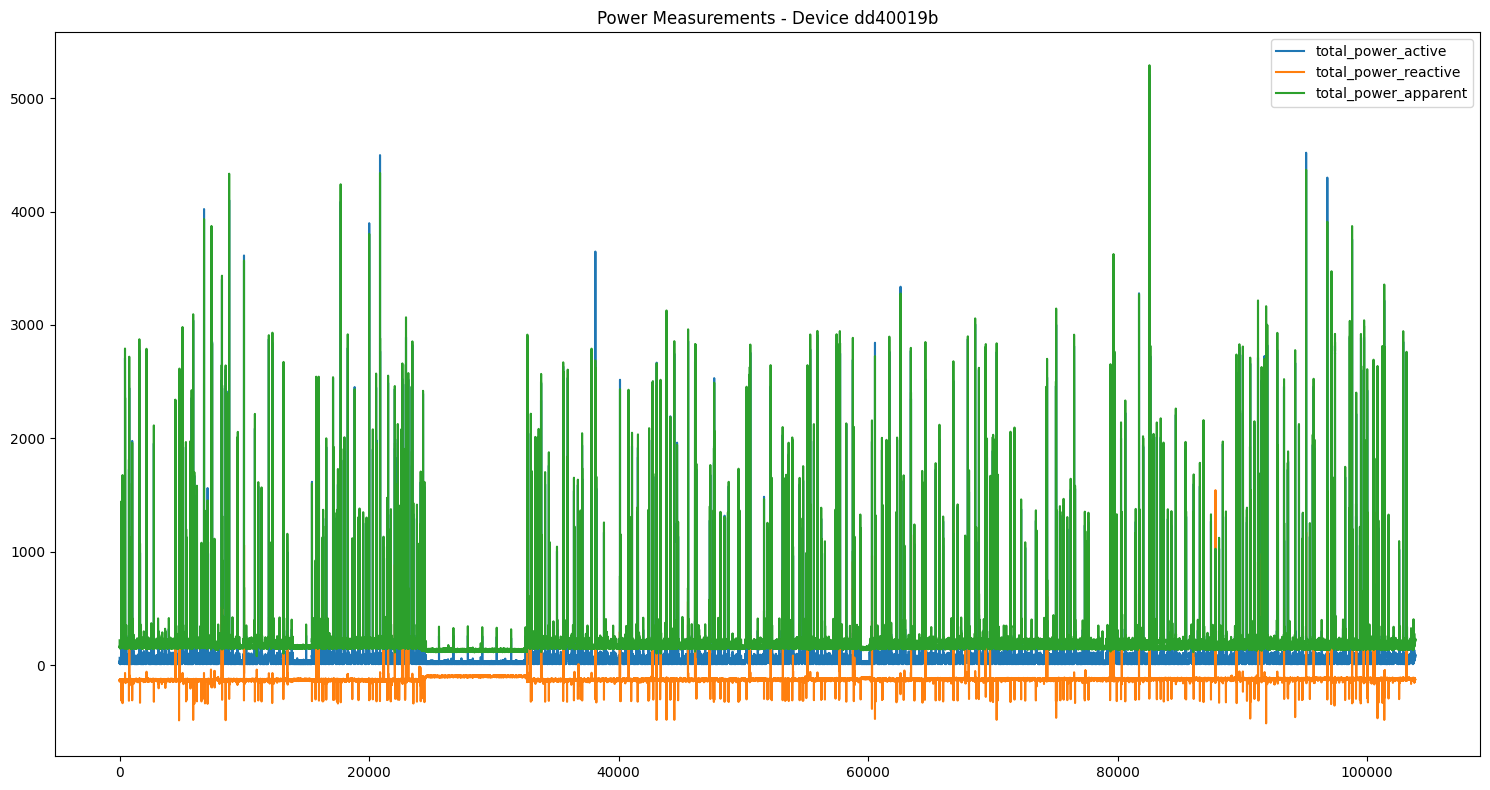

<Figure size 1500x600 with 0 Axes>

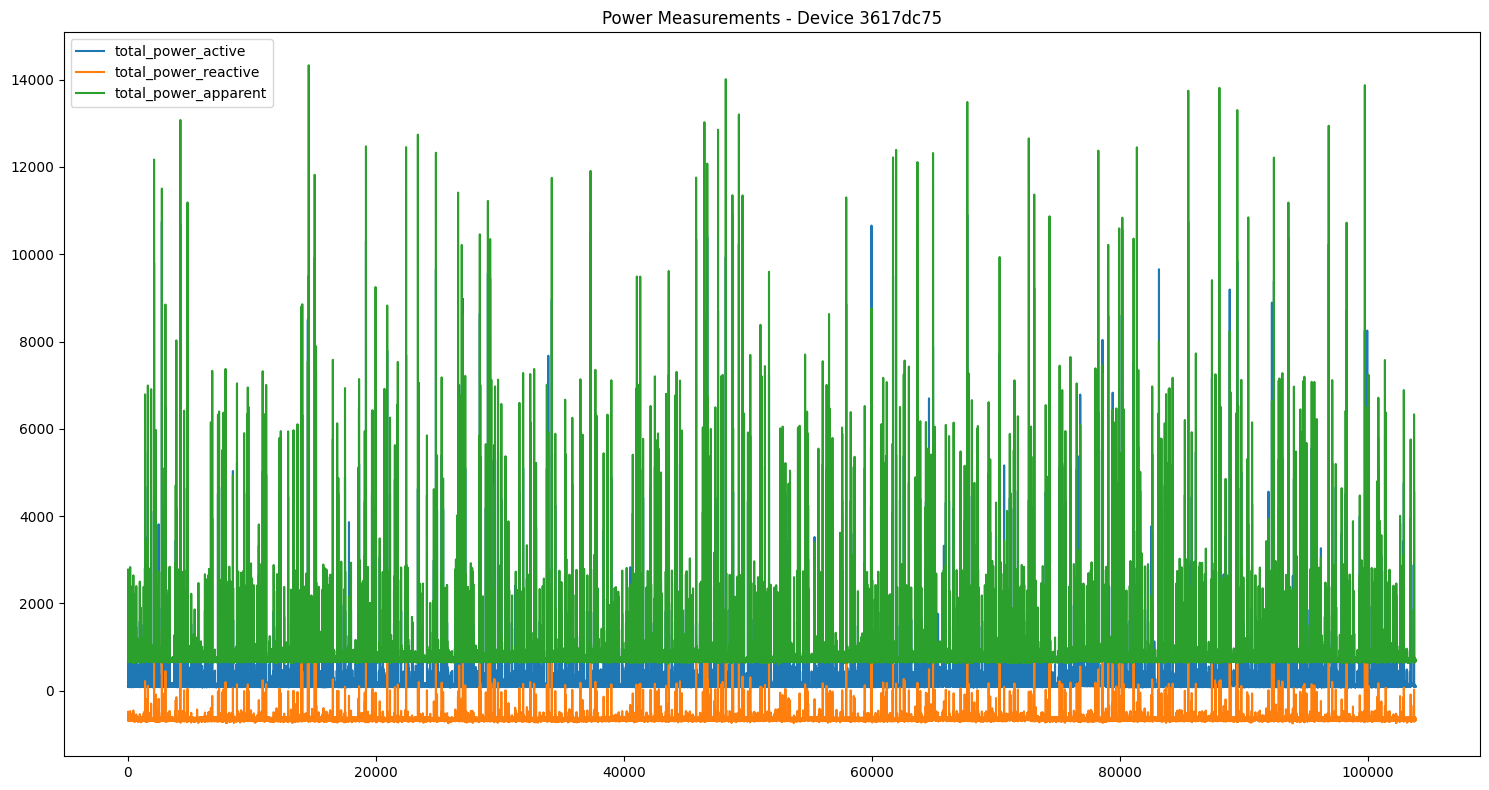

<Figure size 1500x600 with 0 Axes>

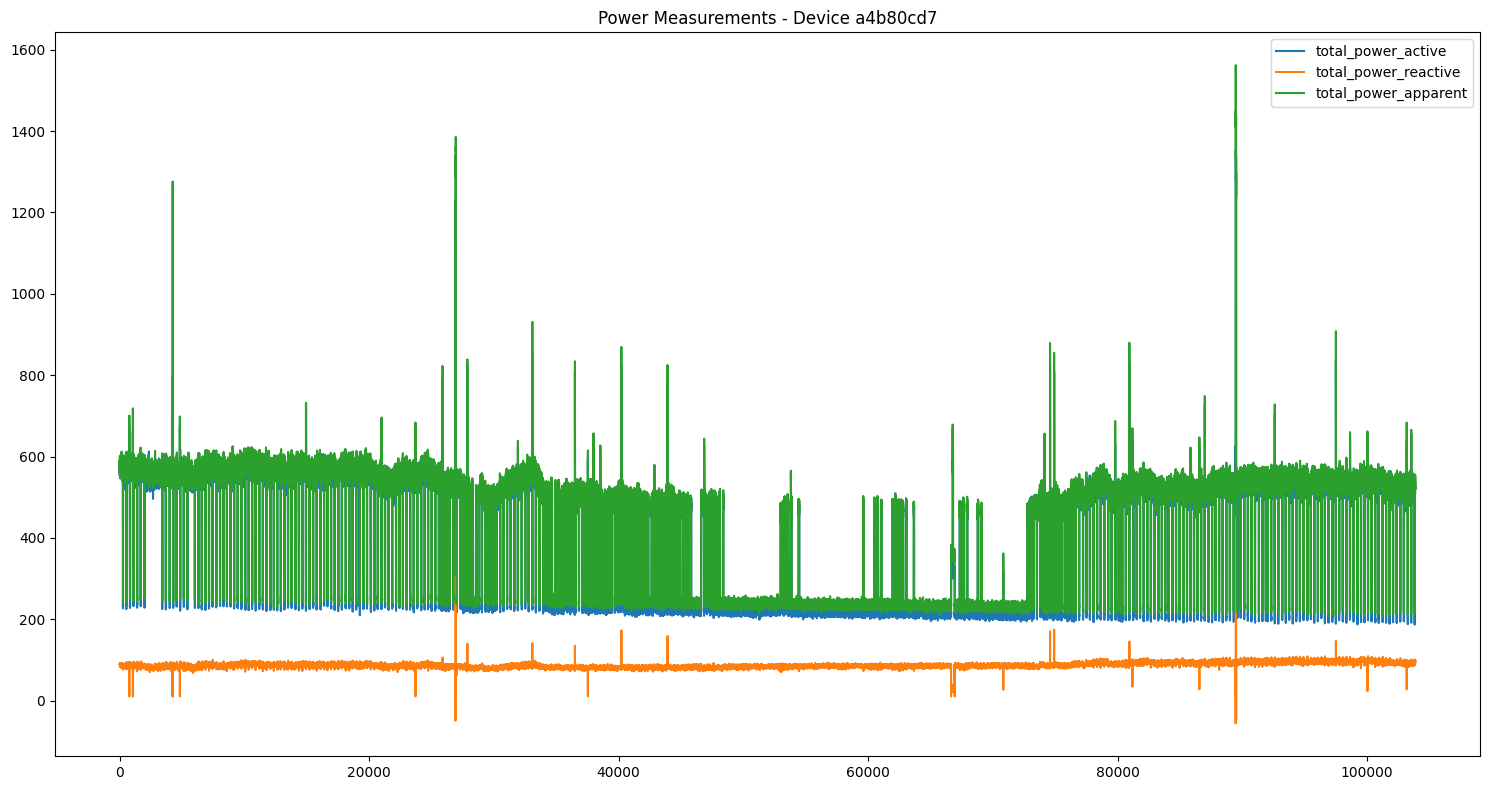

<Figure size 1500x600 with 0 Axes>

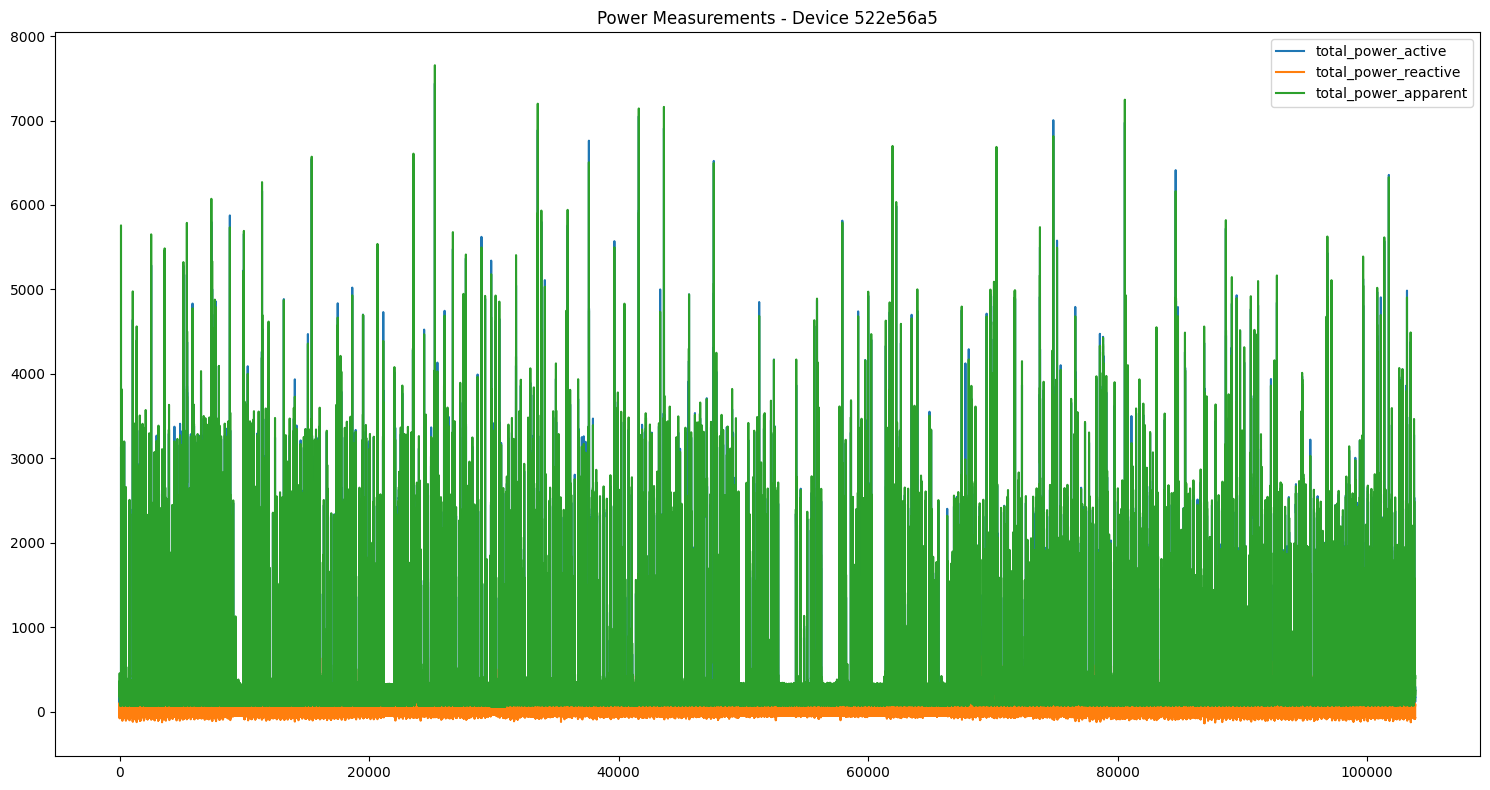

<Figure size 1500x600 with 0 Axes>

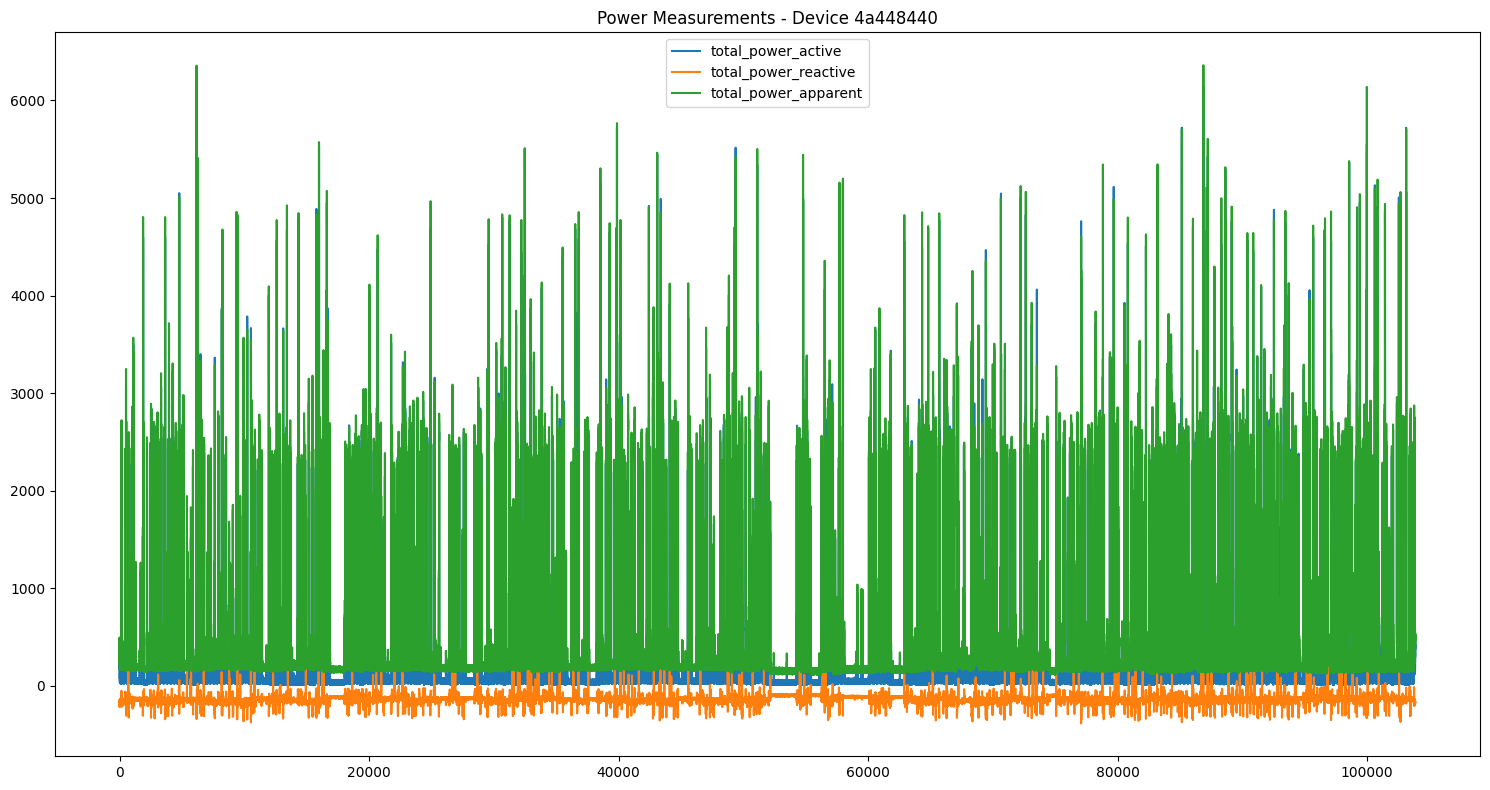

<Figure size 1500x600 with 0 Axes>

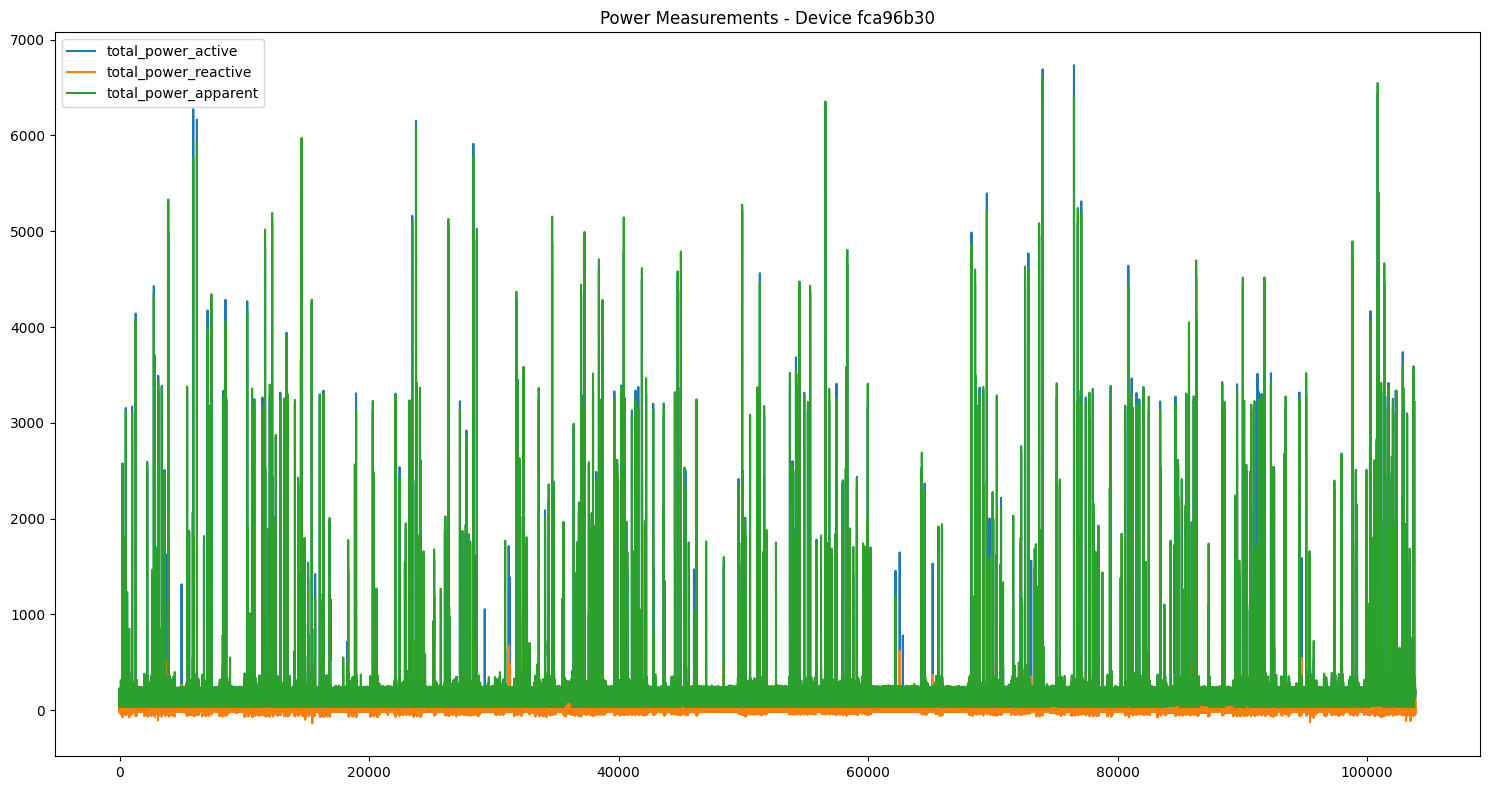

<Figure size 1500x600 with 0 Axes>

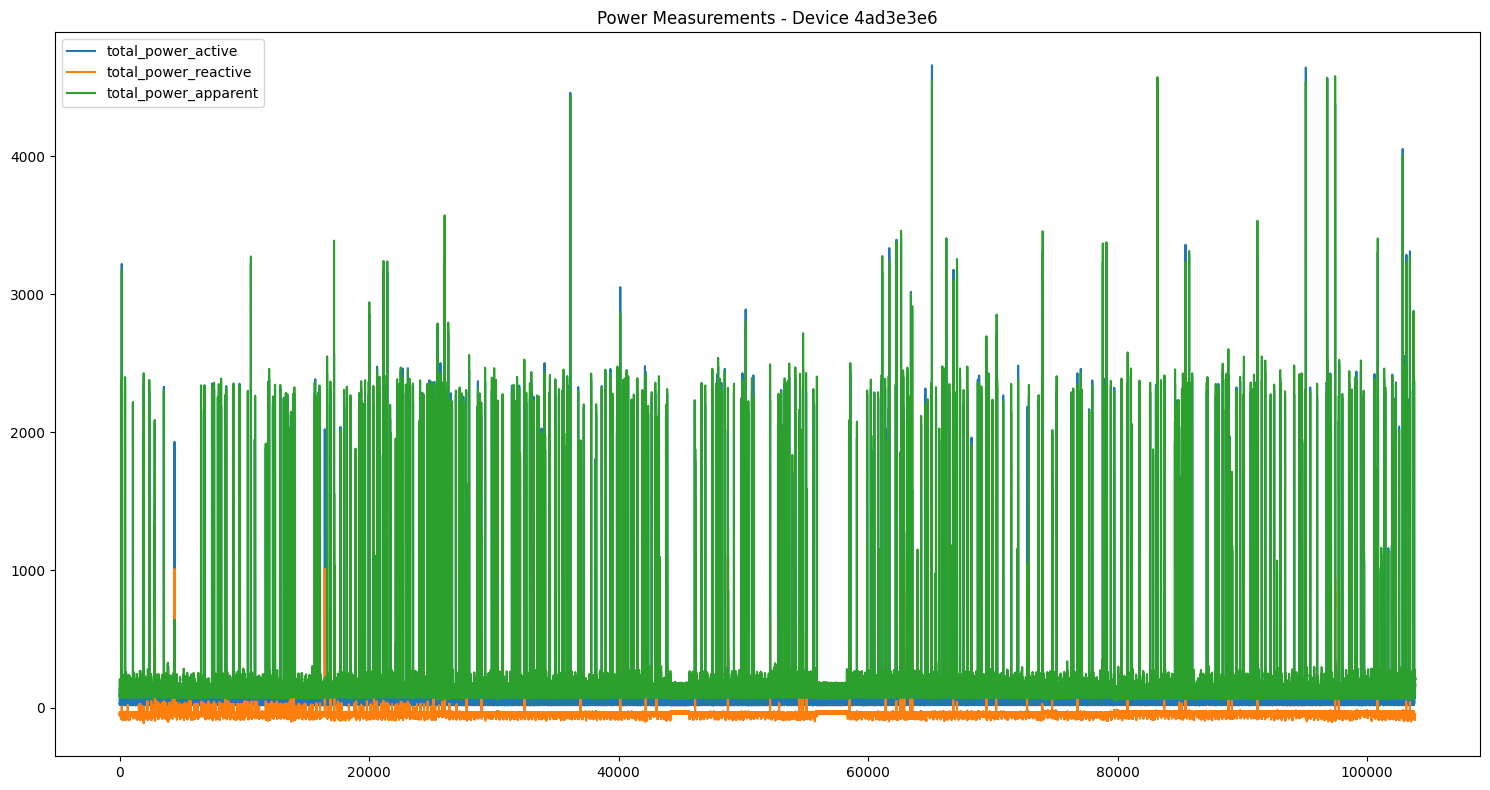

In [20]:
# Looking at power patterns for each device individually
for device_id, meter_data in meter_data_dict.items():
    plt.figure(figsize=(15, 6))
    power_cols = meter_data.columns[meter_data.columns.str.contains('power')]
    meter_data[power_cols].plot()
    plt.title(f"Power Measurements - Device {device_id[:8]}")
    plt.tight_layout()
    plt.show()

<Figure size 1500x600 with 0 Axes>

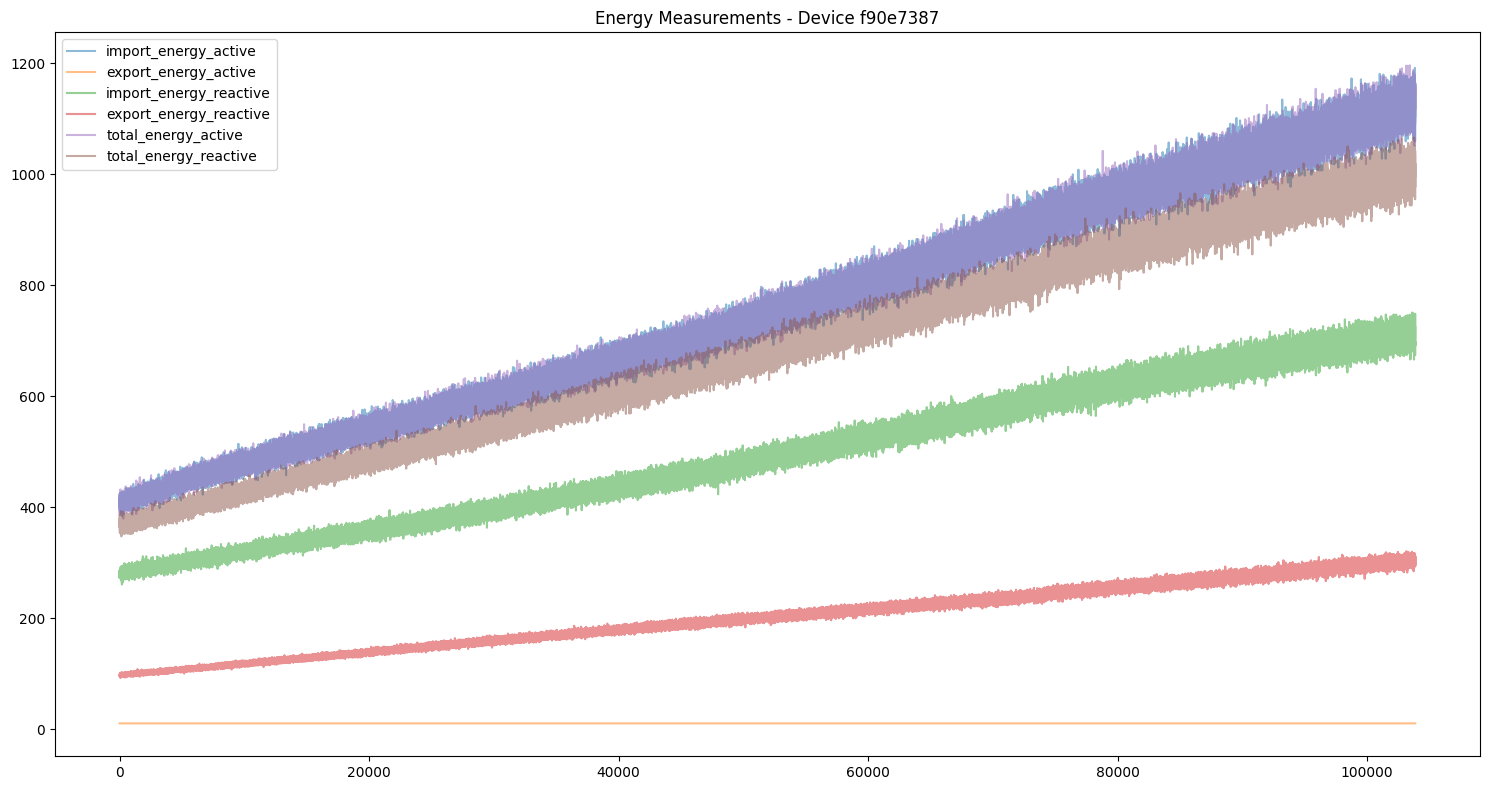

<Figure size 1500x600 with 0 Axes>

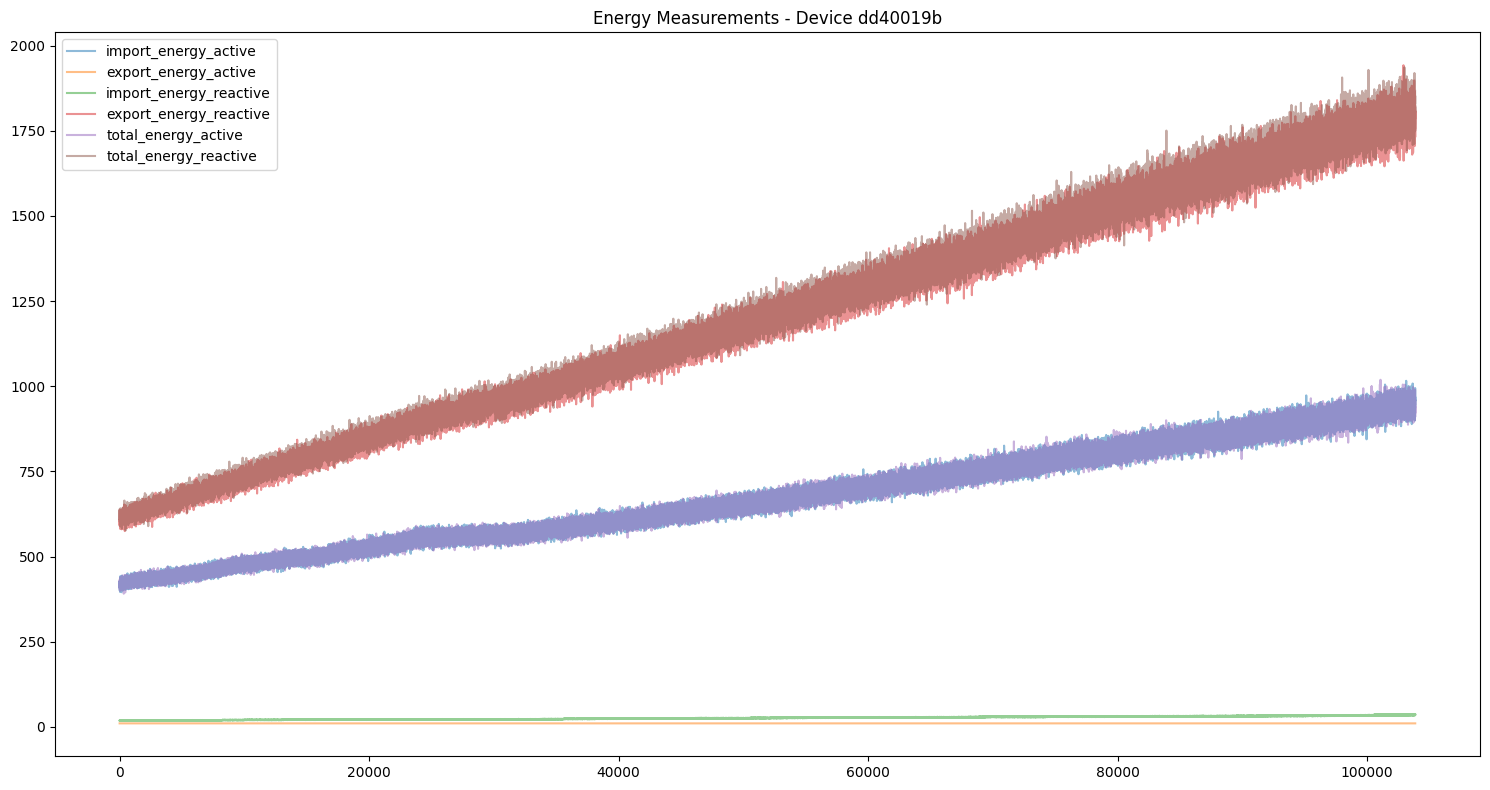

<Figure size 1500x600 with 0 Axes>

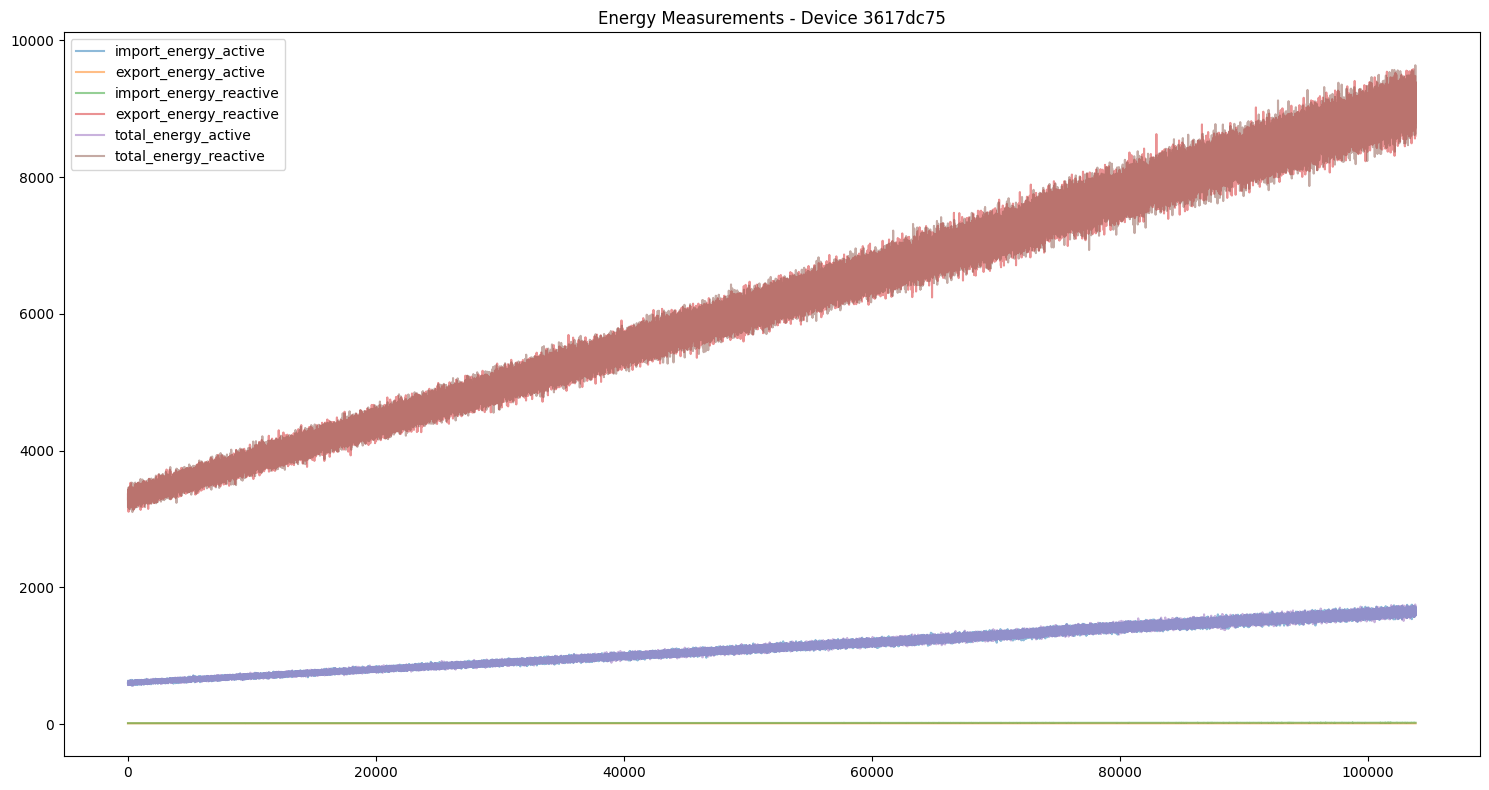

<Figure size 1500x600 with 0 Axes>

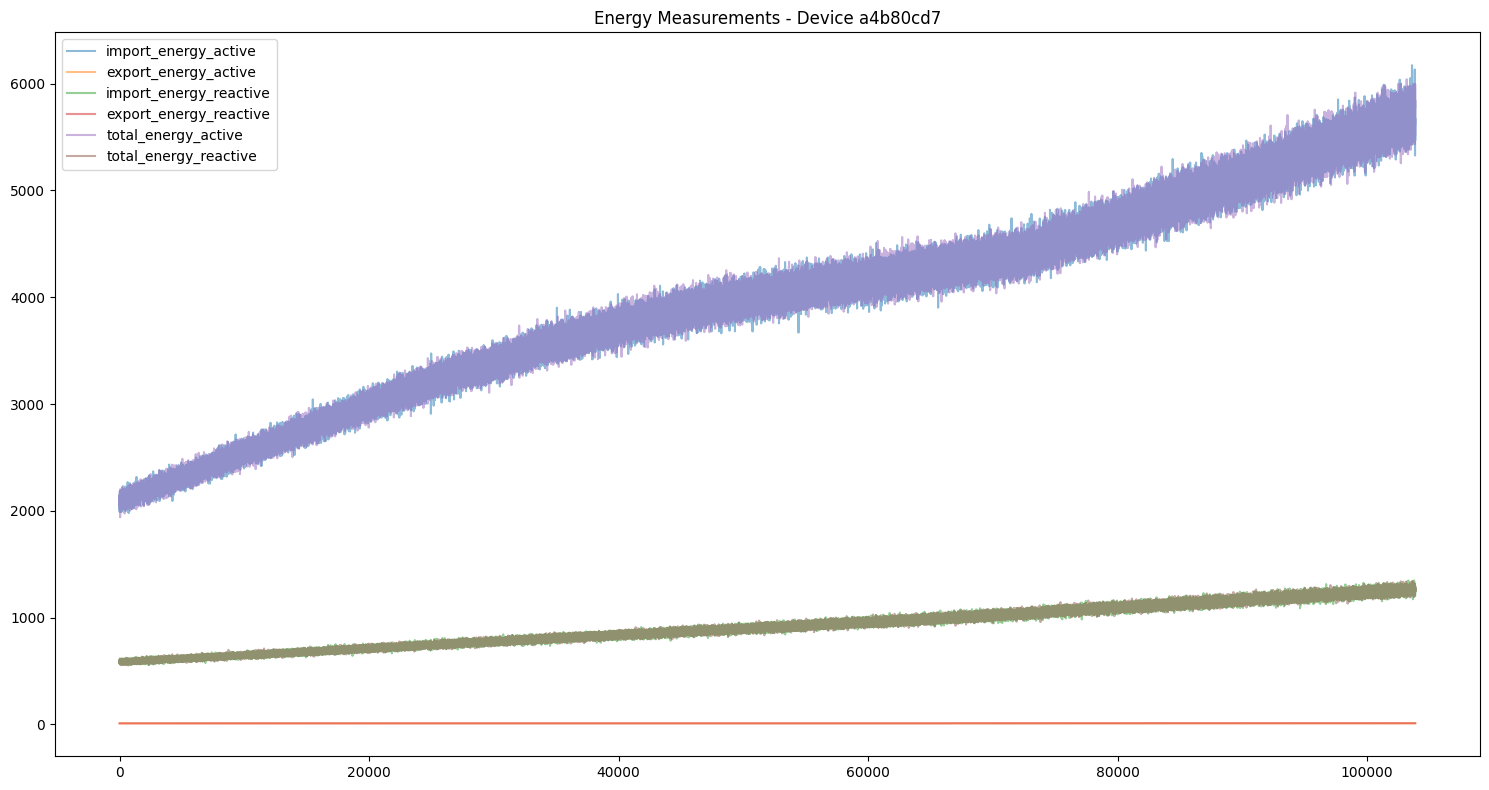

<Figure size 1500x600 with 0 Axes>

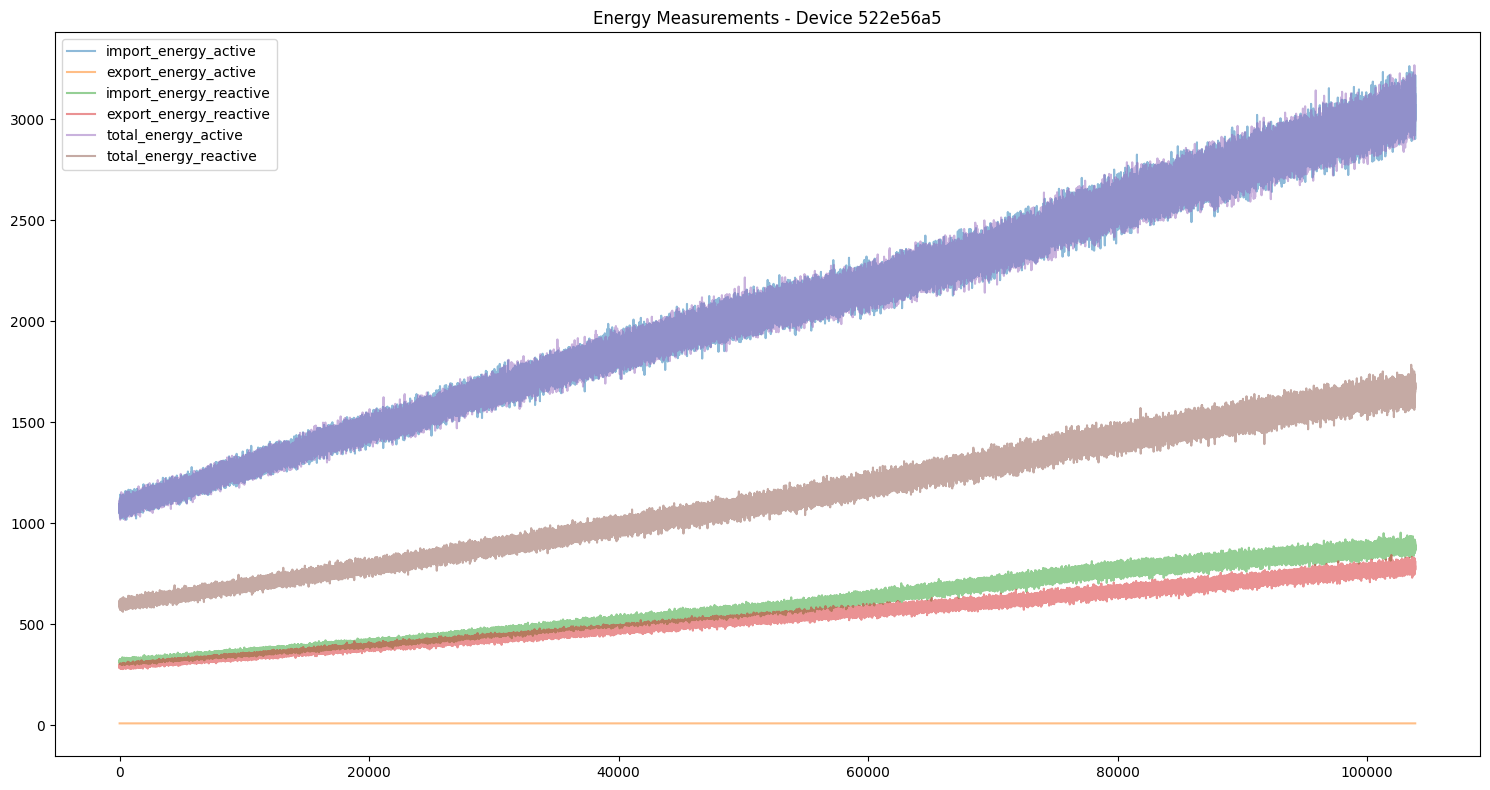

<Figure size 1500x600 with 0 Axes>

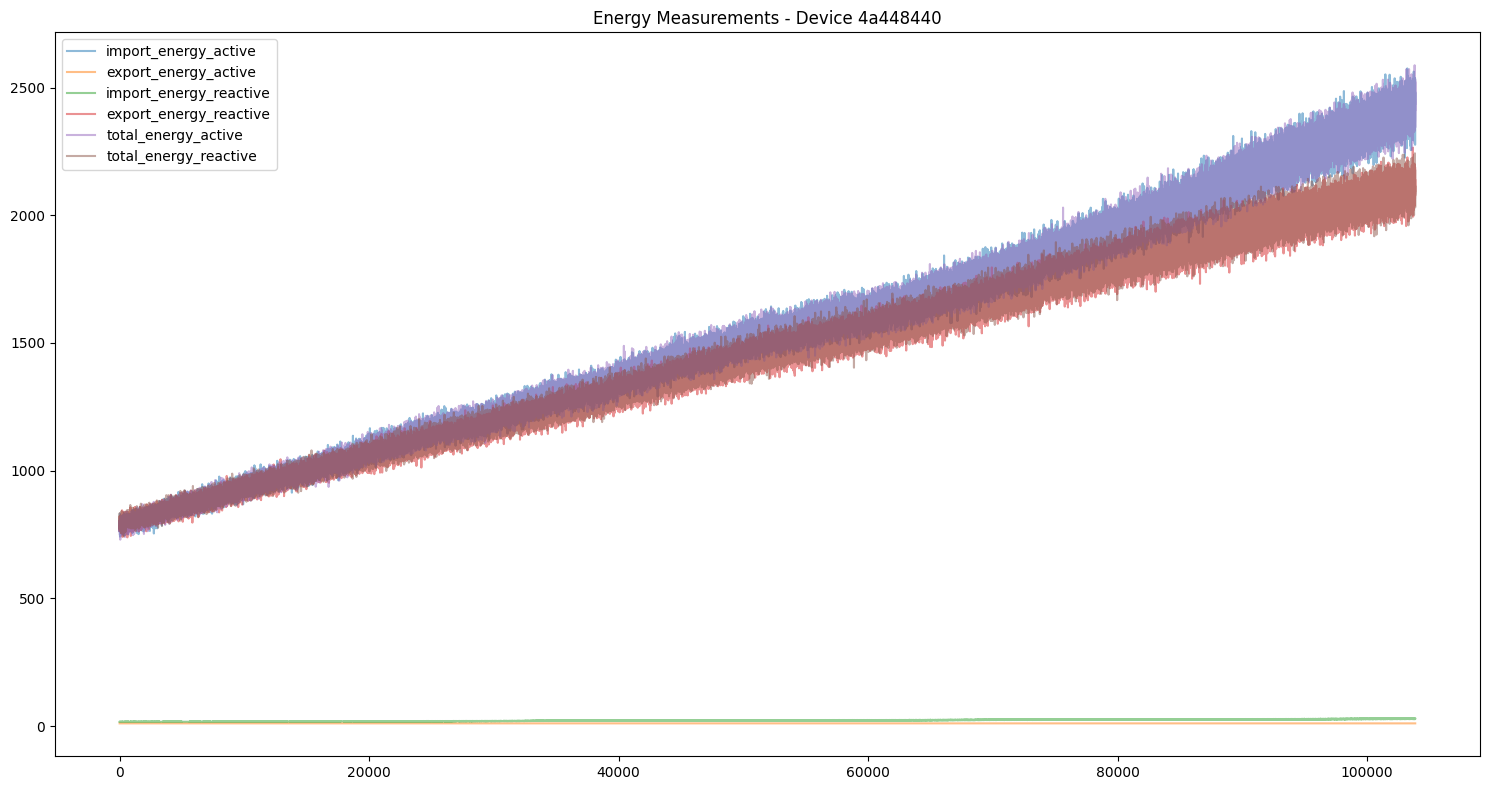

<Figure size 1500x600 with 0 Axes>

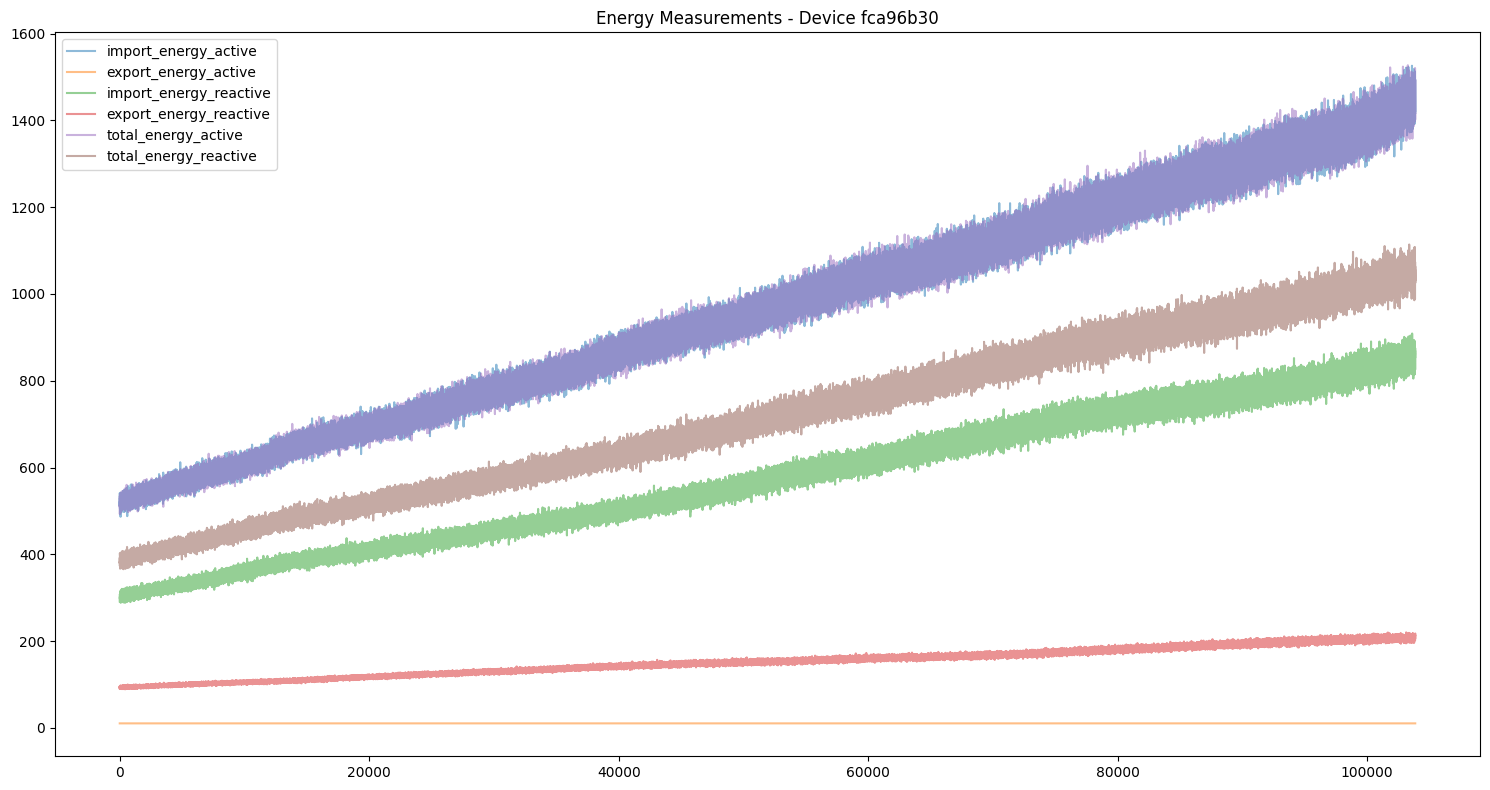

<Figure size 1500x600 with 0 Axes>

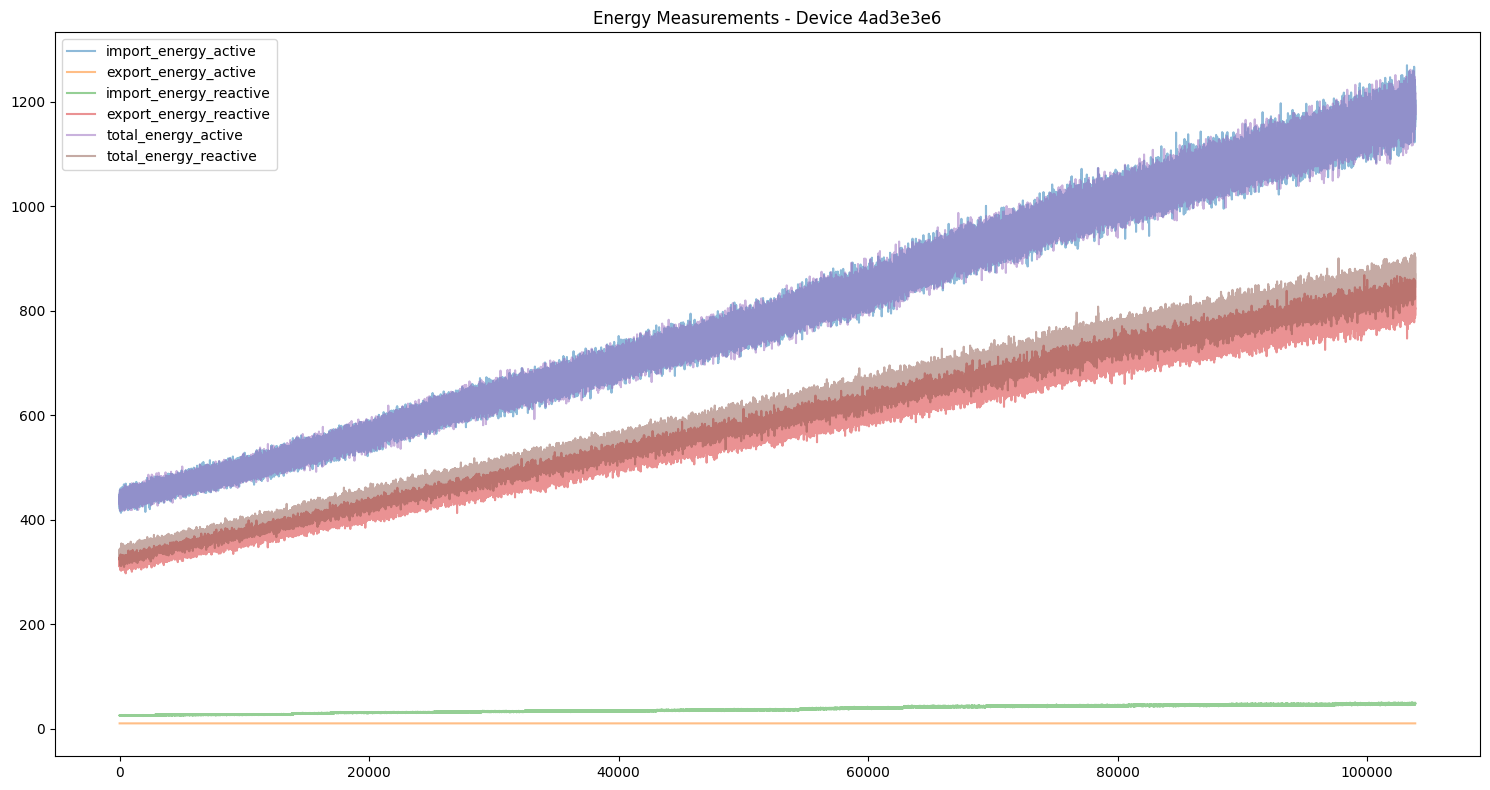

In [21]:
# Energy patterns for each device
for device_id, meter_data in meter_data_dict.items():
    plt.figure(figsize=(15, 6))
    energy_cols = meter_data.columns[meter_data.columns.str.contains('energy')]
    meter_data[energy_cols].plot(alpha=0.5)
    plt.title(f"Energy Measurements - Device {device_id[:8]}")
    plt.tight_layout()
    plt.show()

### Missing Data in September (`total_power_active`)

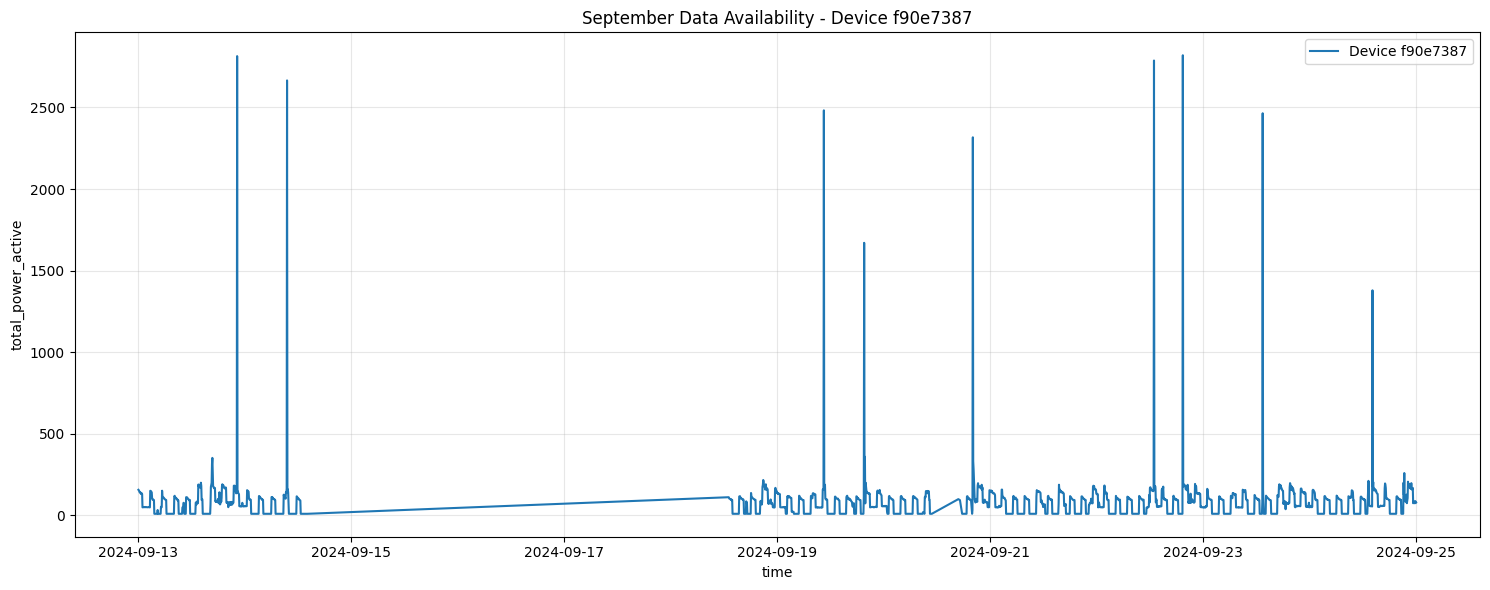

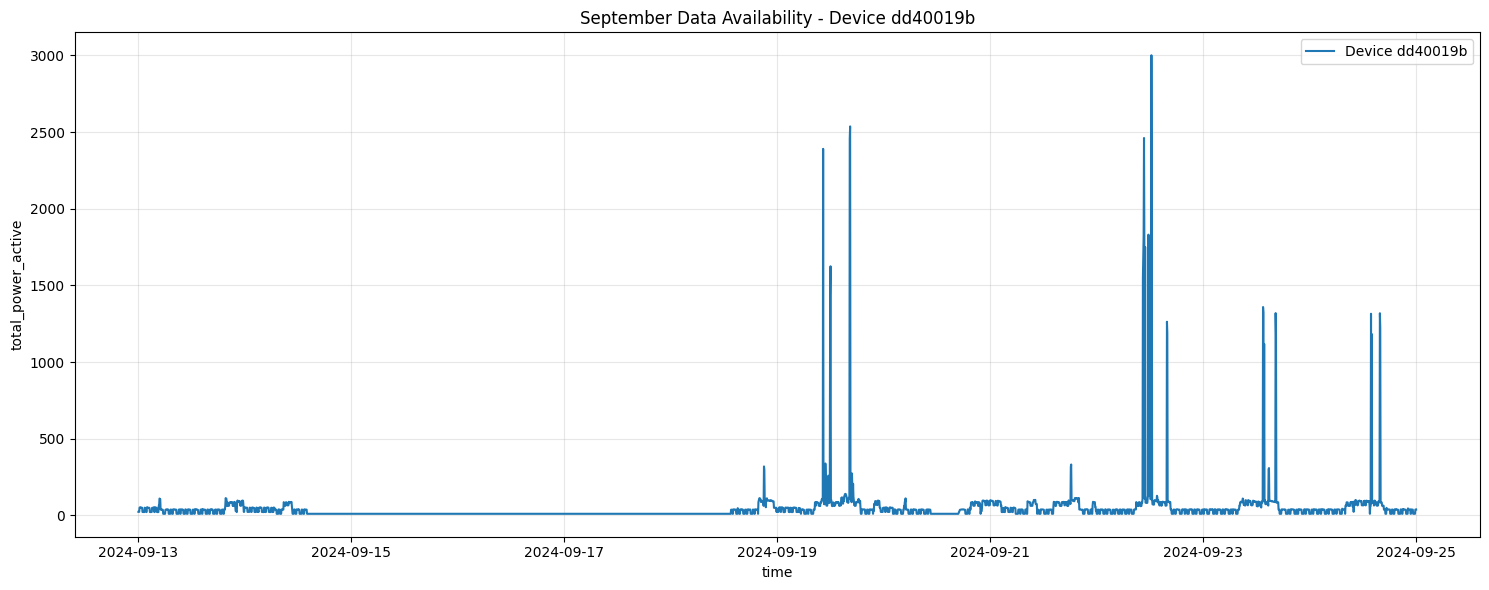

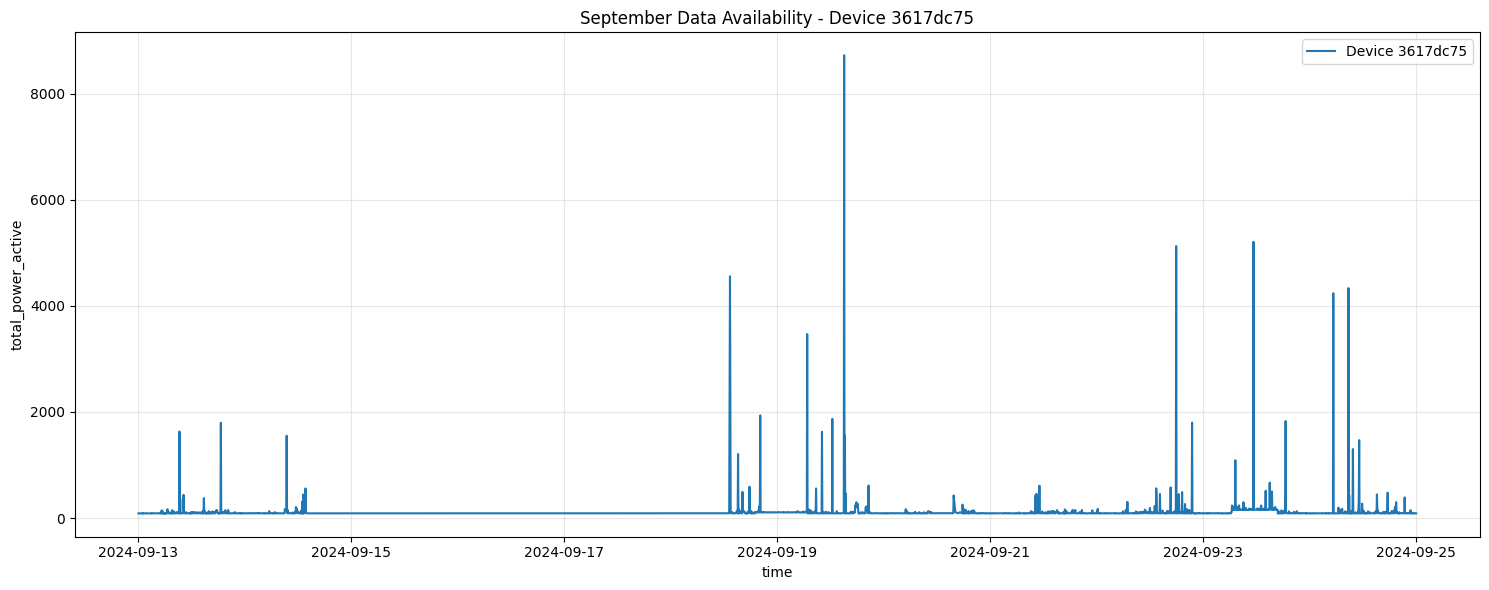

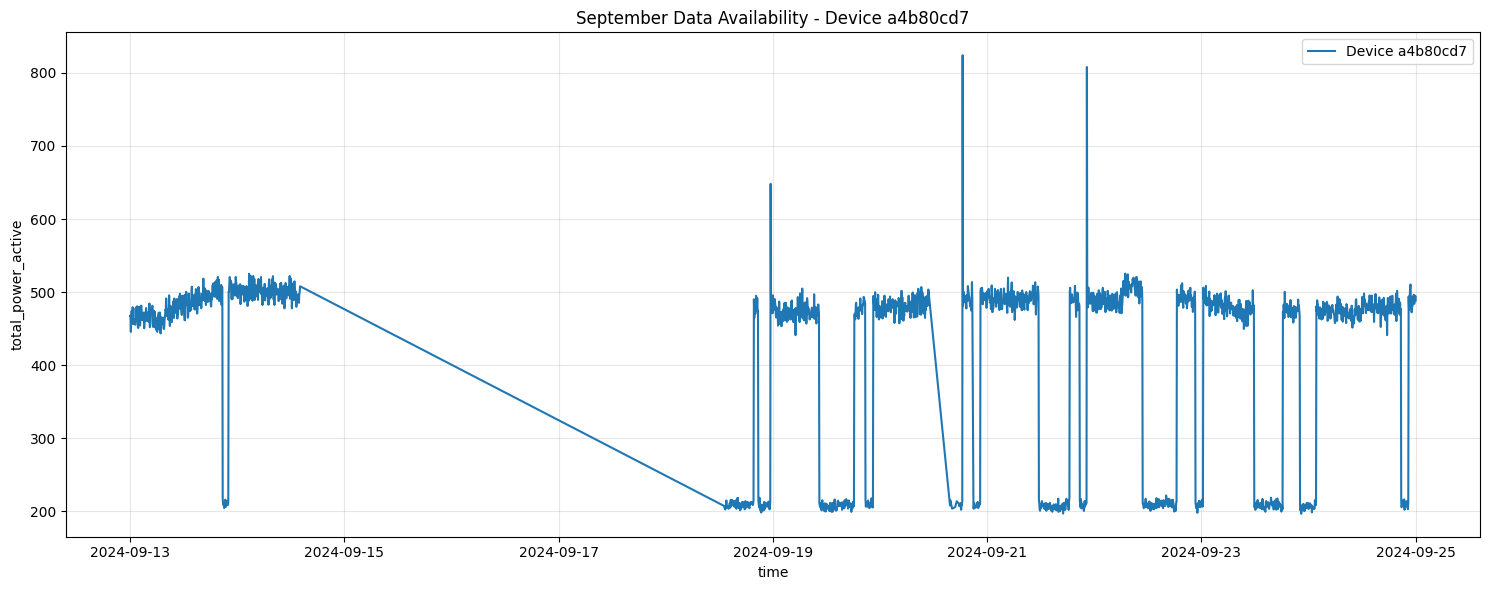

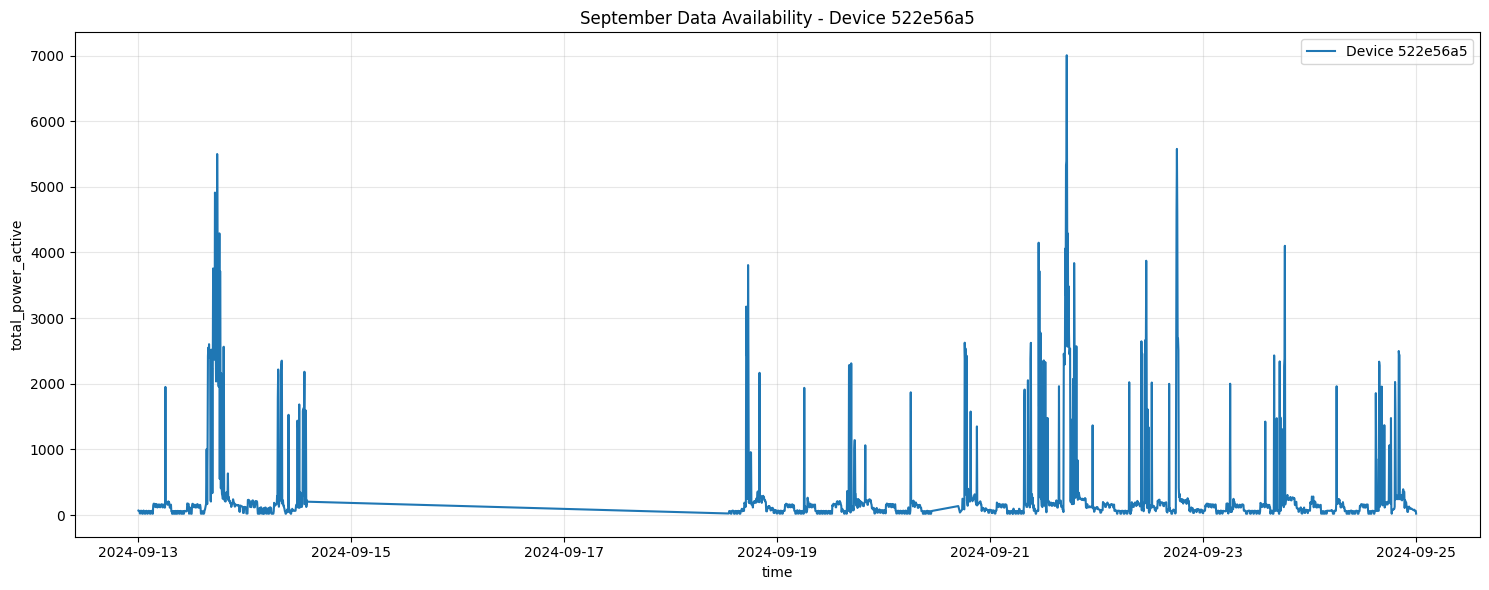

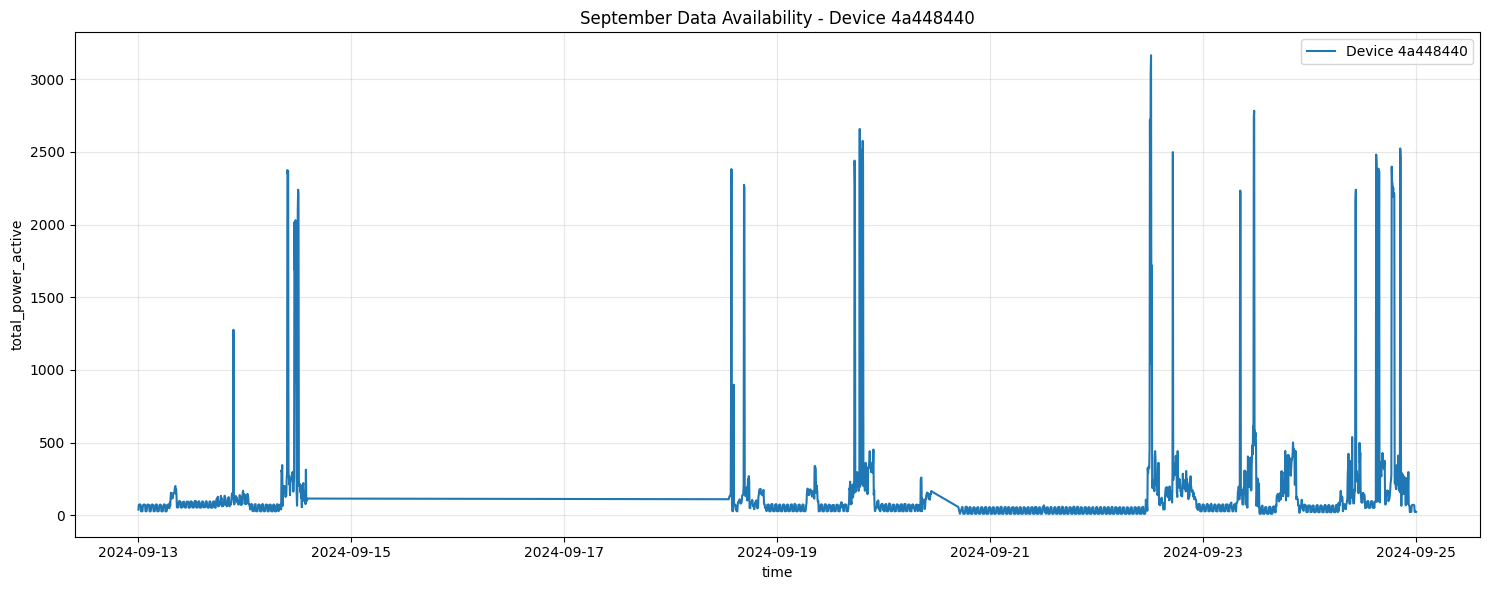

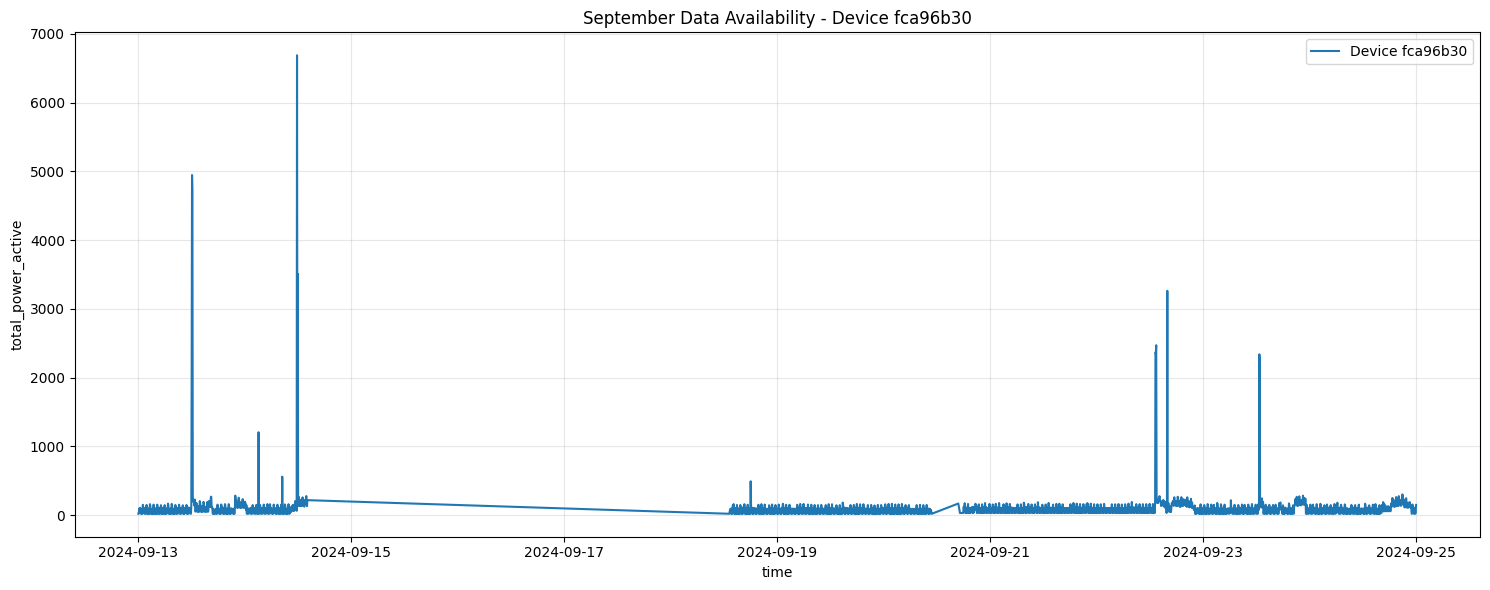

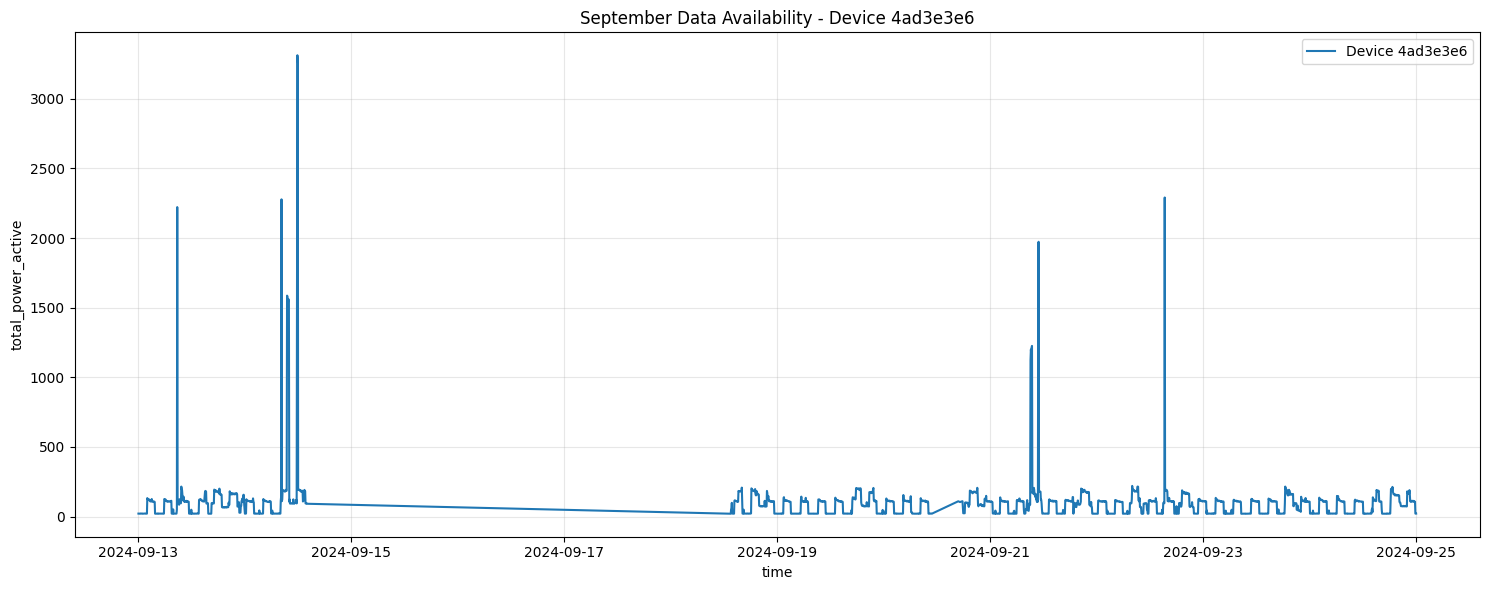

In [22]:
# Check missing data patterns in September (when we previously identified flood-related outages)
for device_id, meter_data in meter_data_dict.items():
    date_range = pd.date_range('2024-09-13', '2024-09-25', freq='min')
    
    plt.figure(figsize=(15, 6))
    filtered_data = meter_data[meter_data['time'].dt.floor('min').isin(date_range)]
    
    if len(filtered_data) > 0:
        sns.lineplot(
            x=filtered_data['time'],
            y=filtered_data['total_power_active'],
            label=f'Device {device_id[:8]}'
        )
        plt.title(f"September Data Availability - Device {device_id[:8]}")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print(f"No data available for device {device_id} during Sep 13-25 period")

### Hourly Visualization (`total_power_active`)

In [23]:
# Create hourly aggregations for each meter
hourly_data_dict = {}

for device_id, meter_data in meter_data_dict.items():
    # Group by hour
    hourly_meter_data = meter_data.groupby(meter_data['time'].dt.floor('h'))
    
    # Create index for full time range
    full_range = pd.DataFrame(
        index=pd.date_range(
            pd.DatetimeIndex(hourly_meter_data.indices.keys()).min(),
            pd.DatetimeIndex(hourly_meter_data.indices.keys()).max(), 
            freq='h'
        )
    )
    
    # Join with hourly aggregated data
    tot_pow_hour_endog = full_range.join(hourly_meter_data['total_power_active'].mean(), how='left').squeeze()
    hourly_data_dict[device_id] = tot_pow_hour_endog

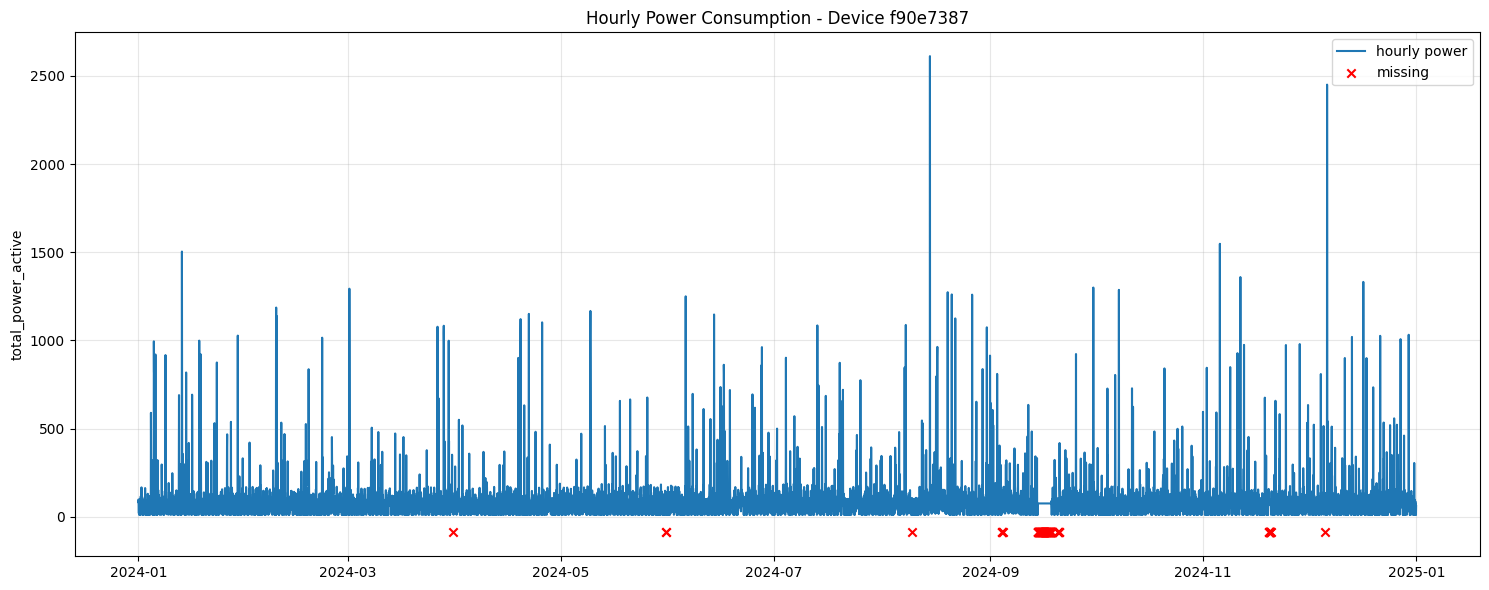

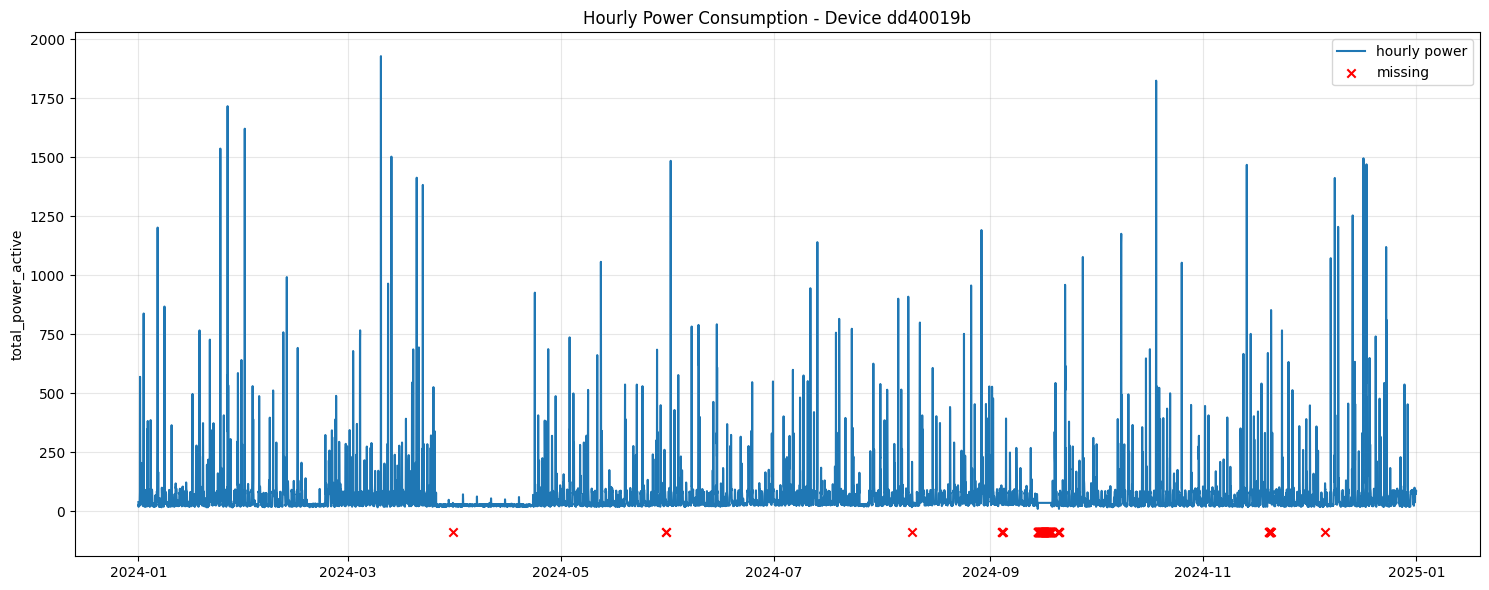

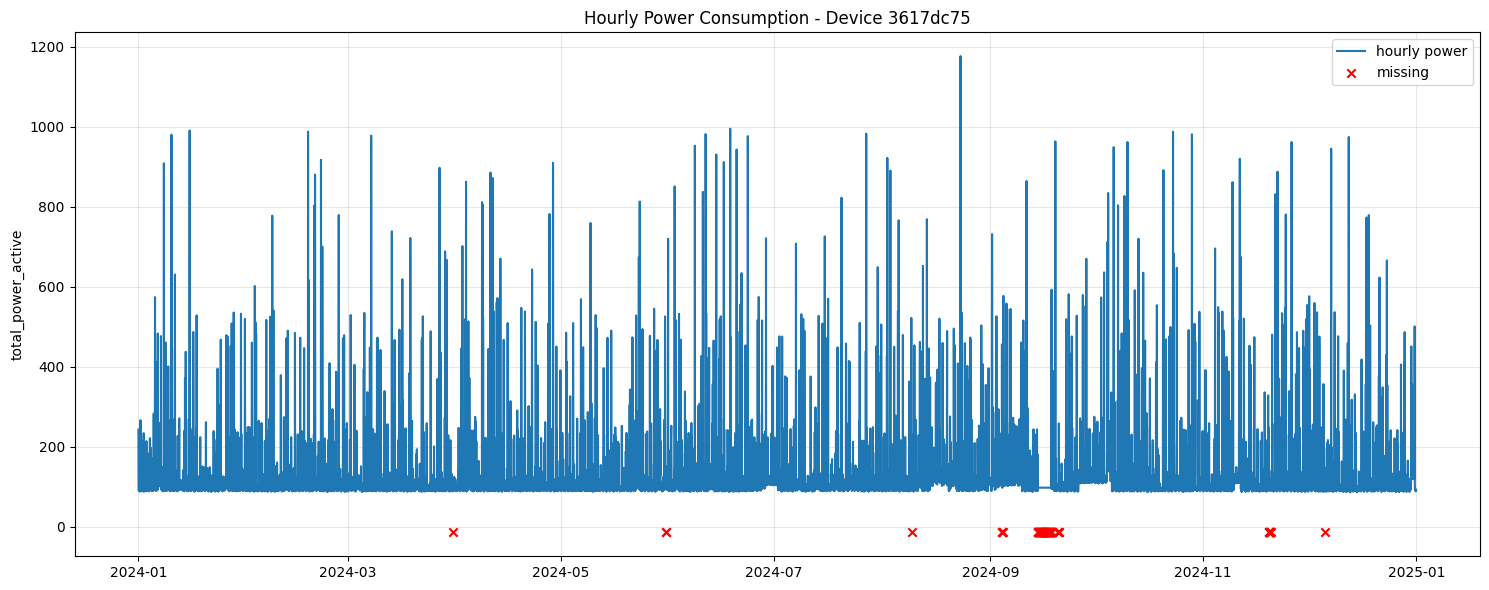

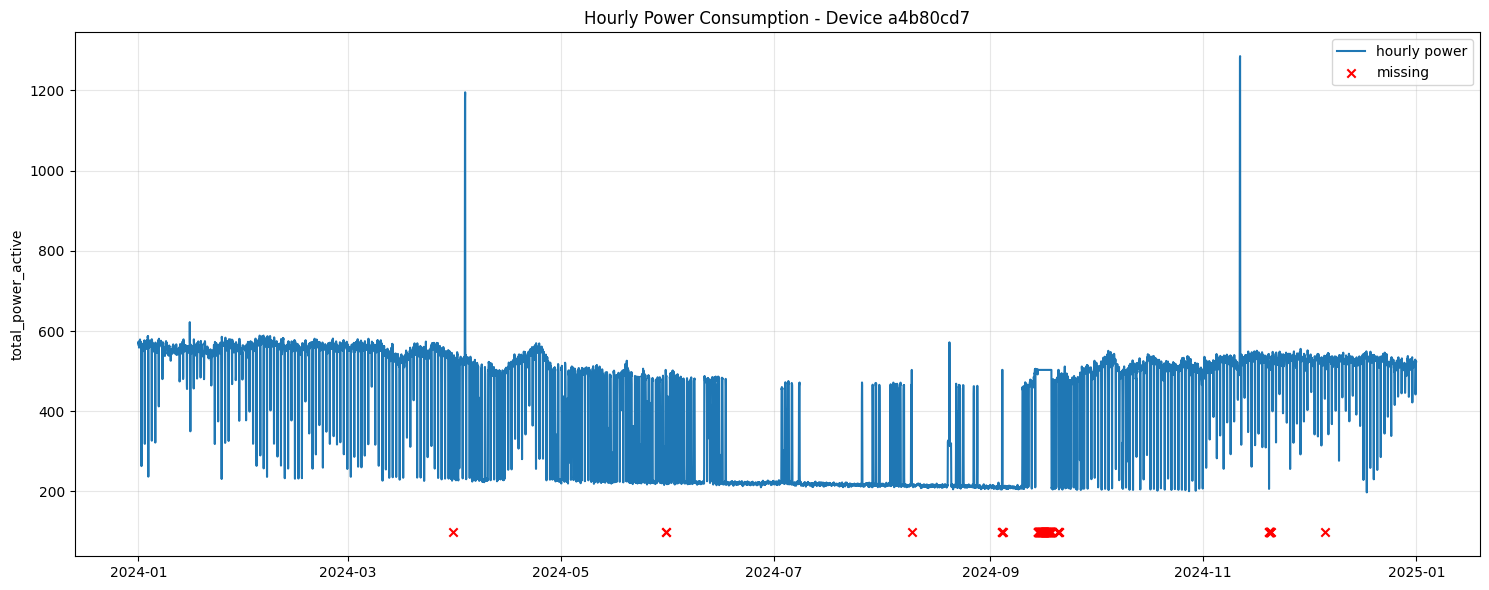

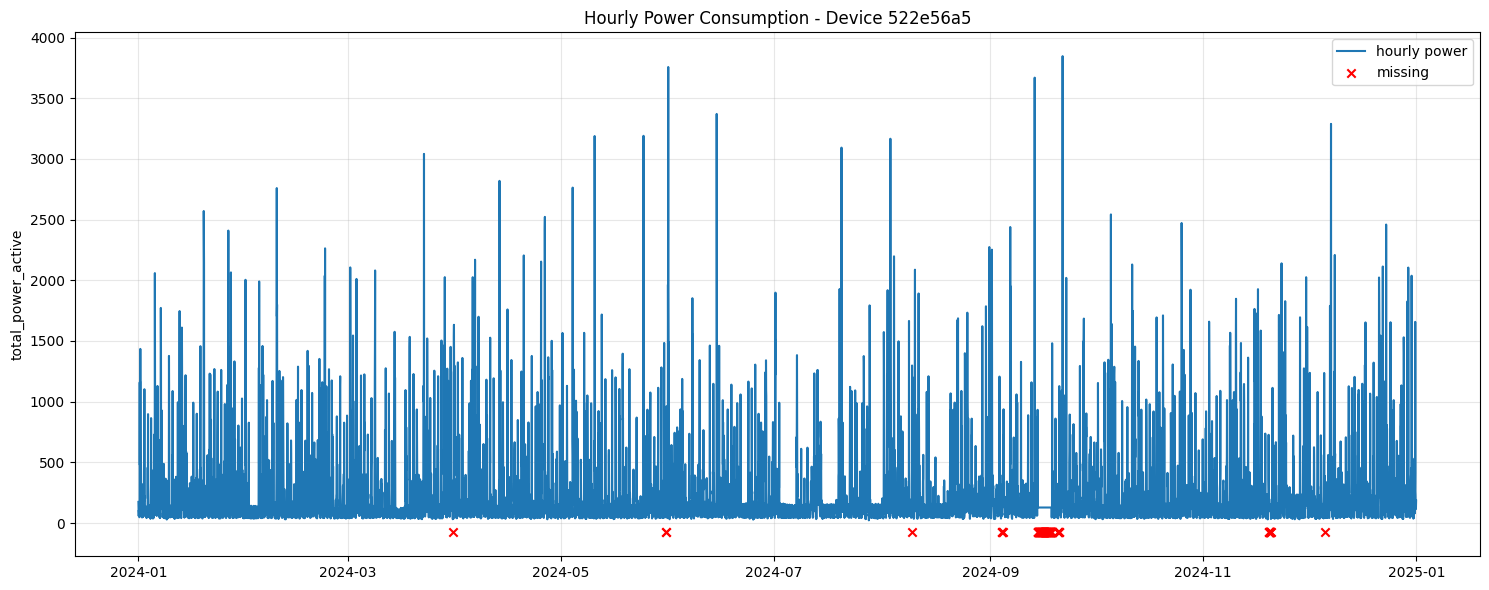

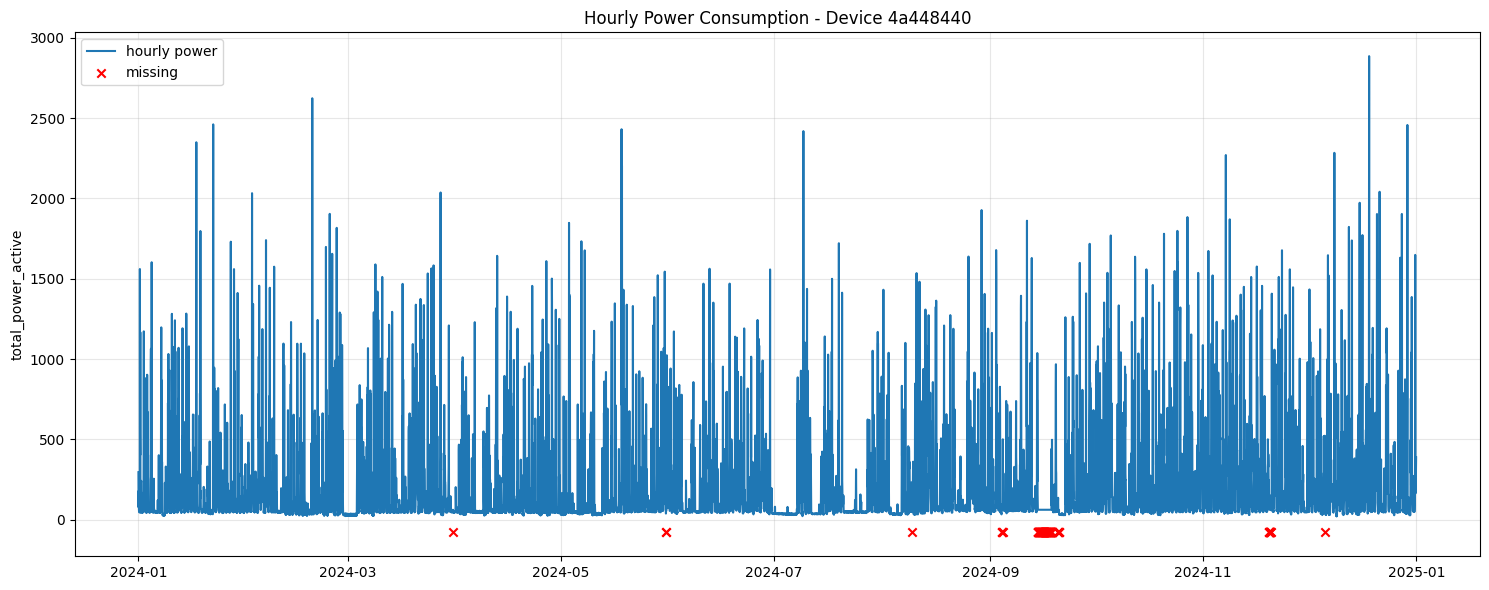

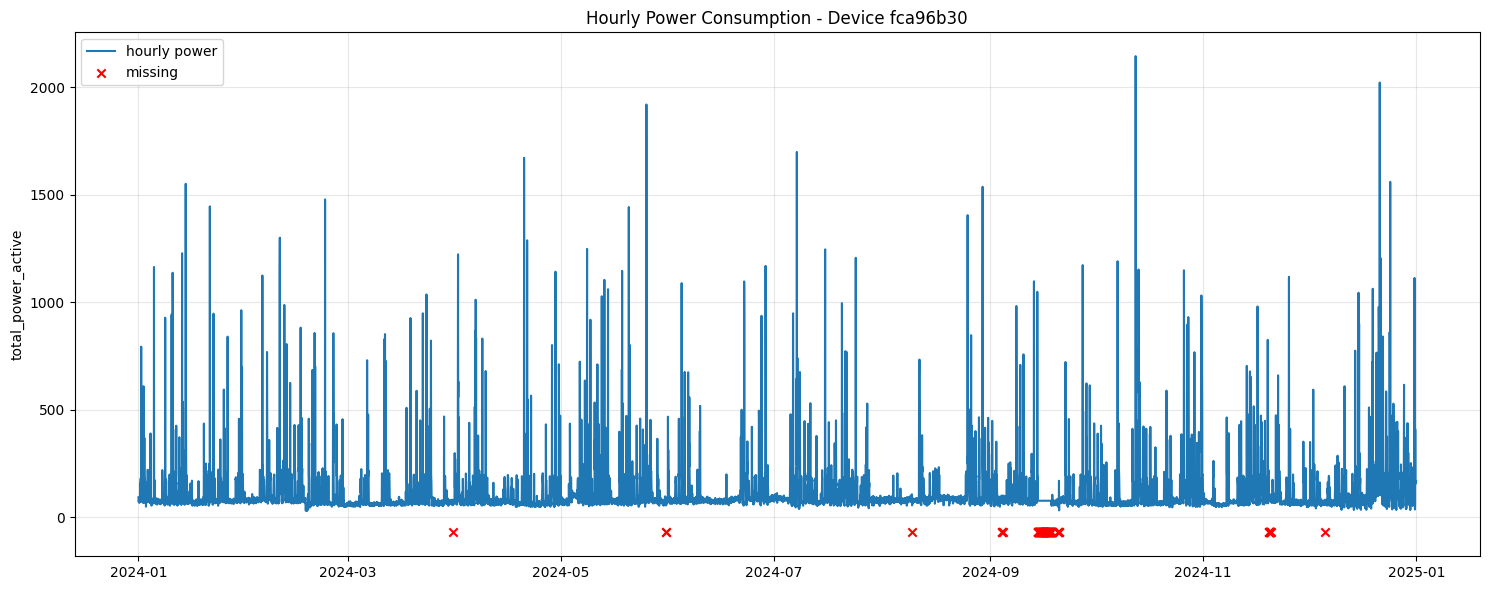

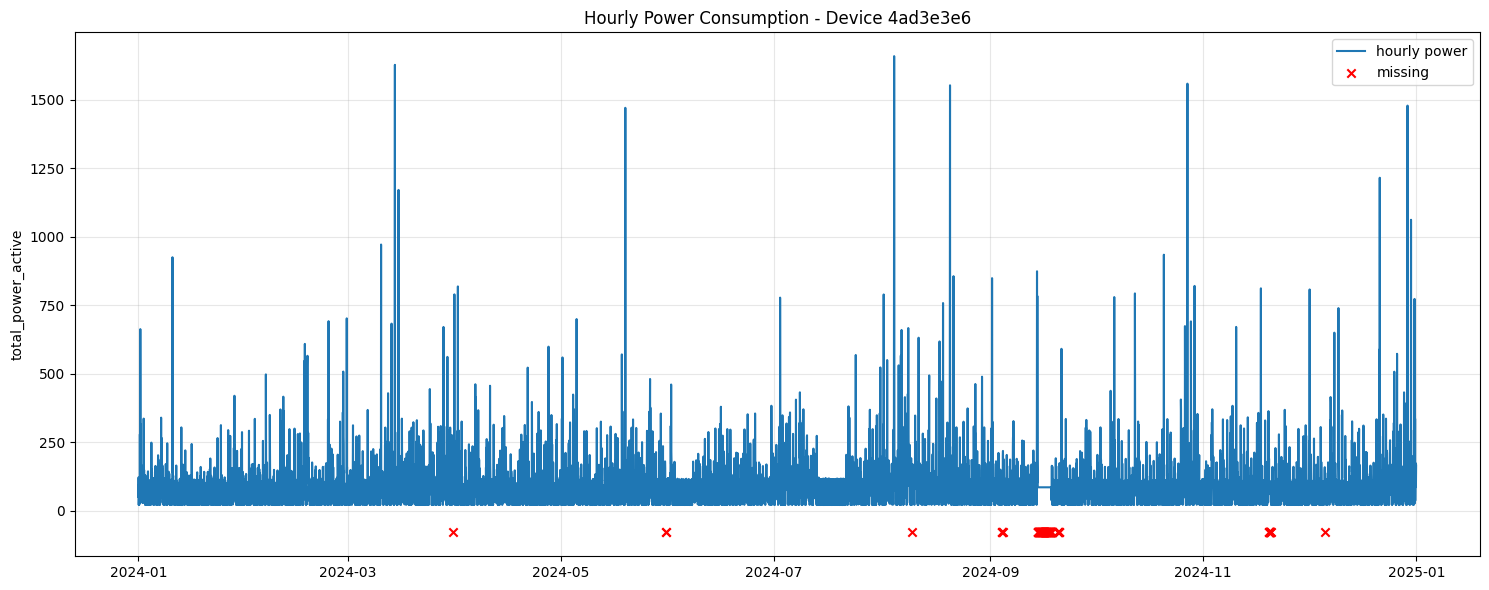

In [24]:
# Plot hourly data for each meter
for device_id, hourly_data in hourly_data_dict.items():
    plt.figure(figsize=(15, 6))
    
    # Choose a sensible default value for missing data (median or a low negative value for visibility)
    fill_value = hourly_data.median() if not pd.isna(hourly_data.median()) else -100
    
    sns.lineplot(hourly_data.fillna(fill_value), label='hourly power')
    
    # Mark missing values
    plt.scatter(
        x=hourly_data[hourly_data.isna()].index,
        y=[hourly_data.min()-100]*hourly_data[hourly_data.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"Hourly Power Consumption - Device {device_id[:8]}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Seasonality and Pattern Analysis (`total_power_active`)

#### Weekly Patterns

Device: f90e7387-981


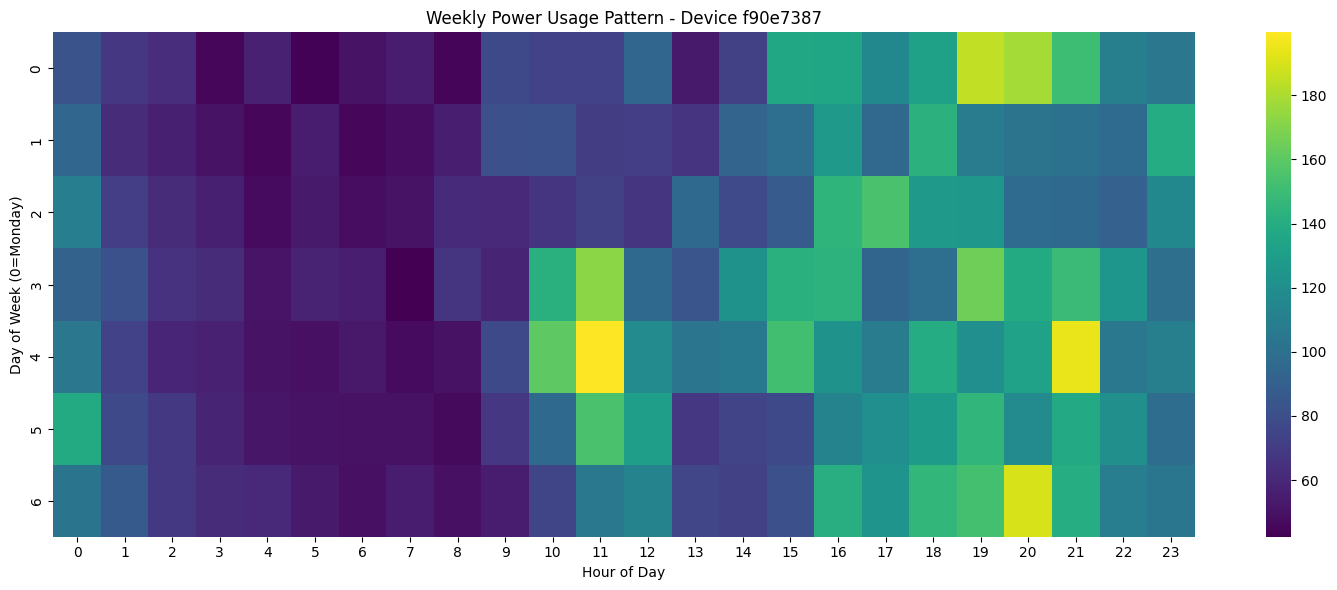

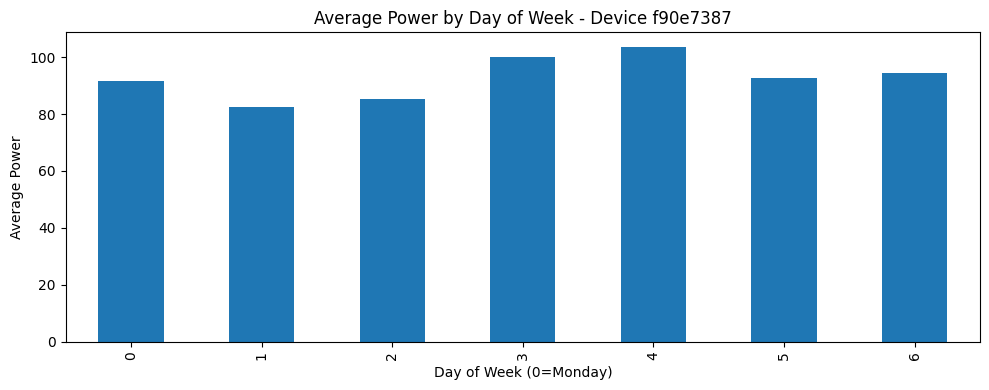

Device: dd40019b-5b3


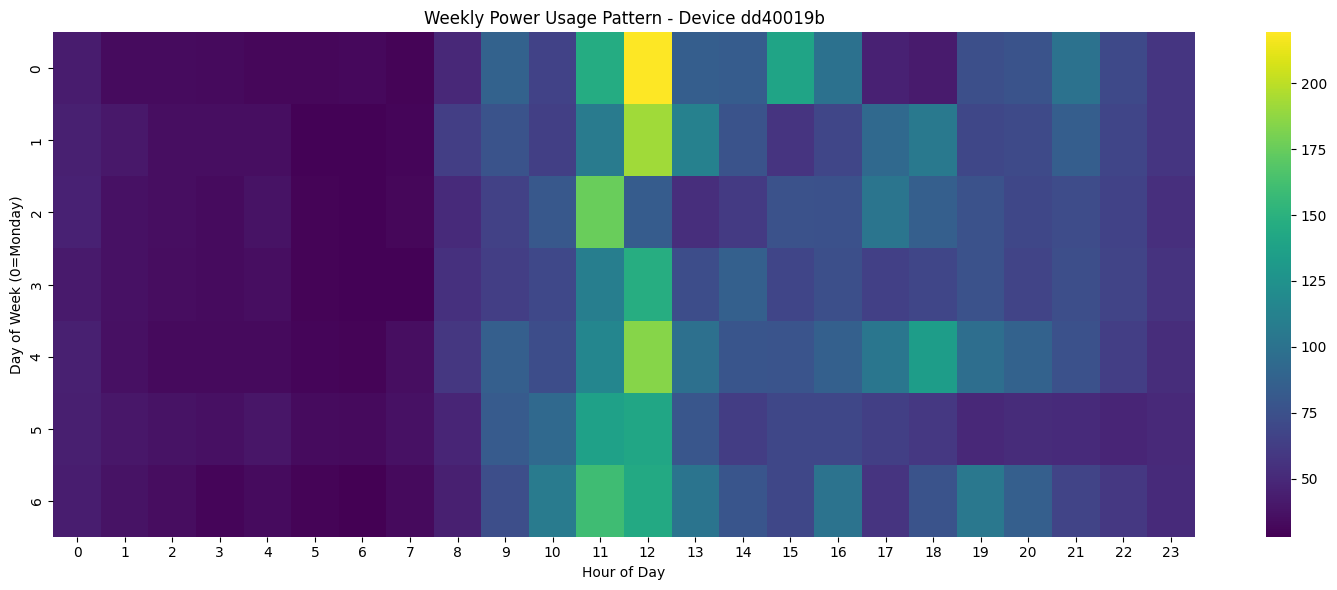

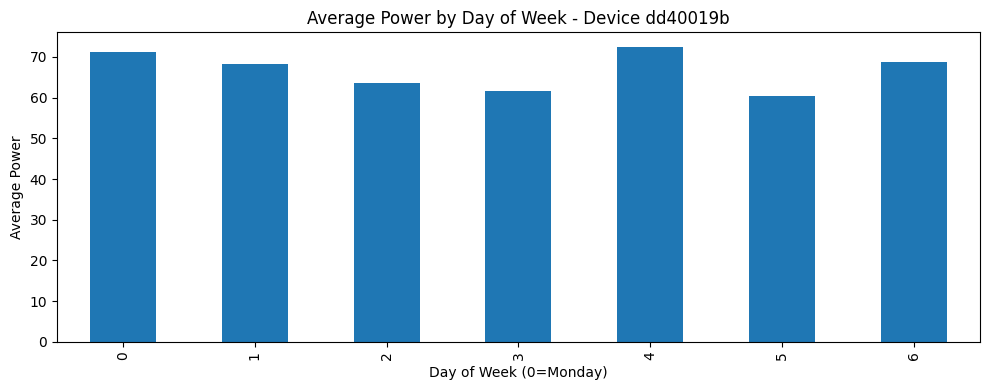

Device: 3617dc75-38d


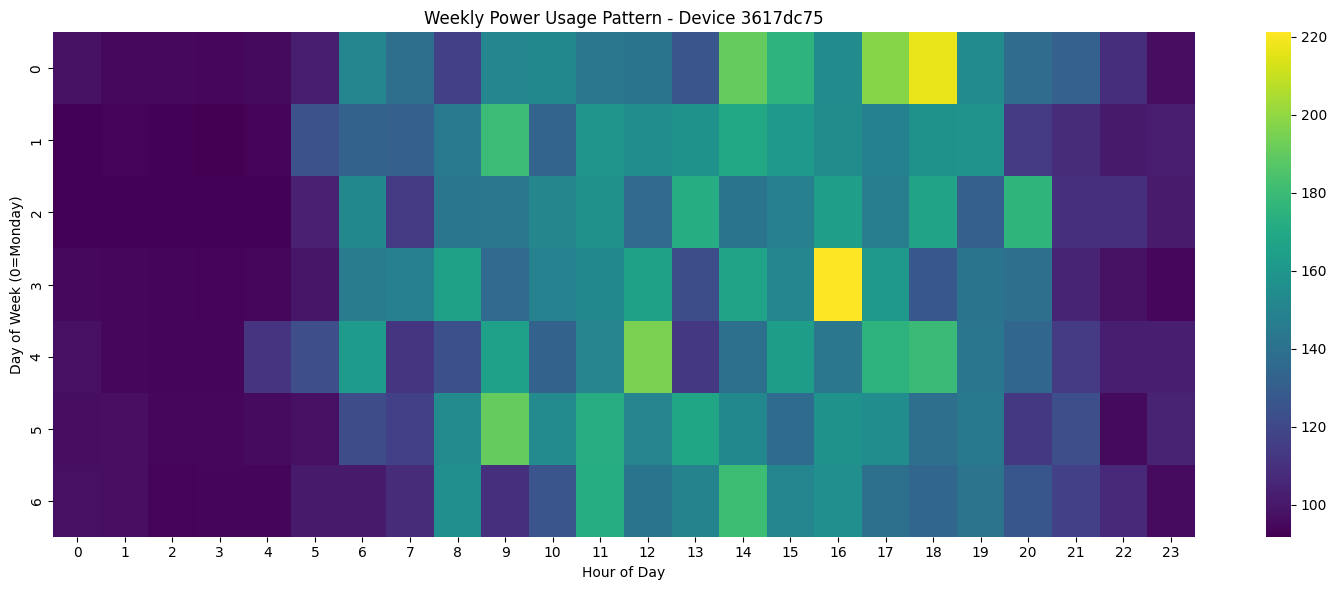

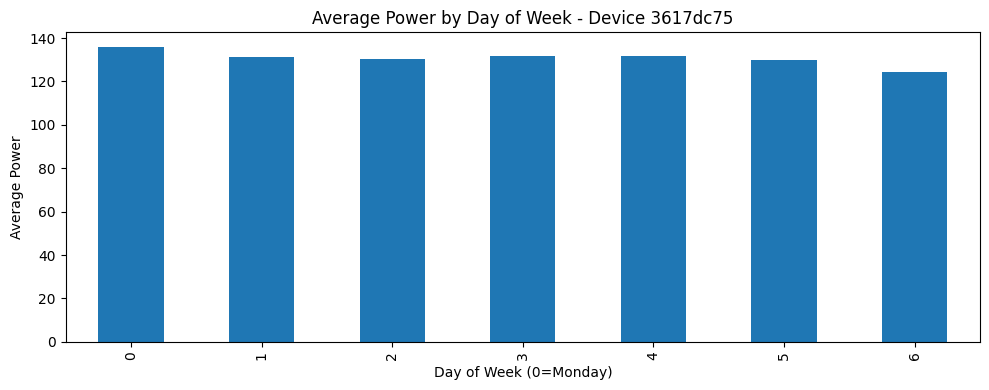

Device: a4b80cd7-543


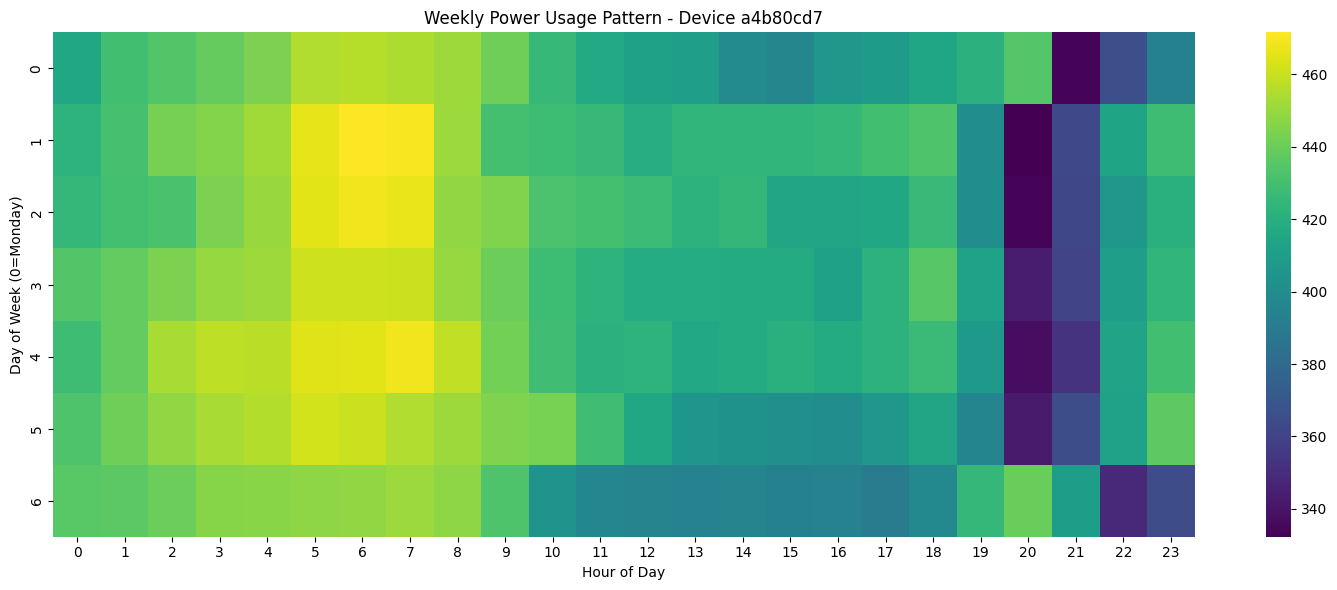

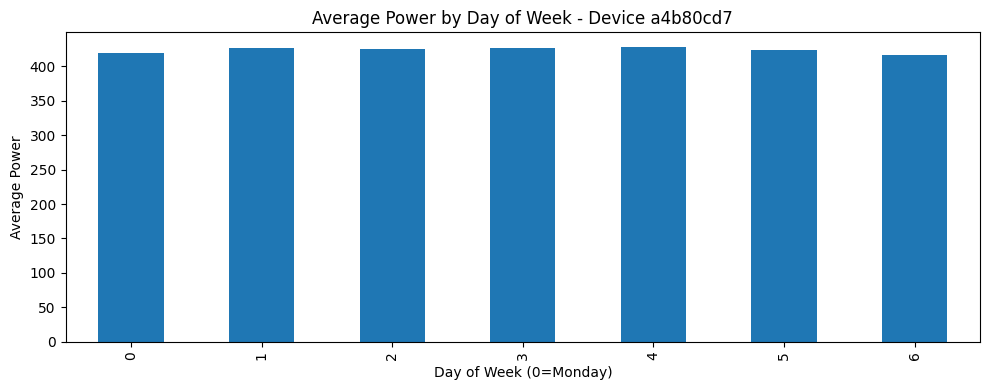

Device: 522e56a5-ff0


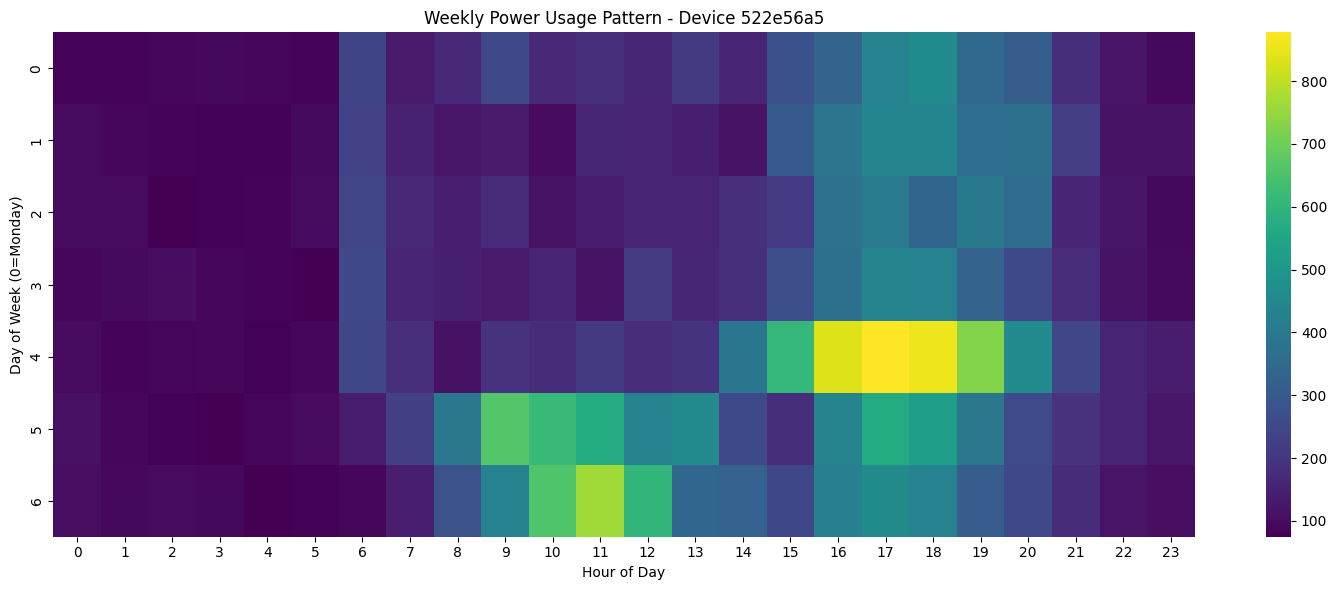

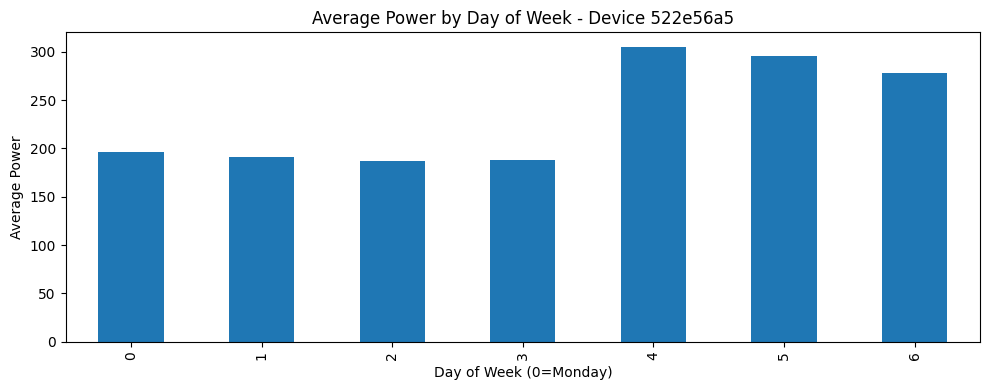

Device: 4a448440-d2d


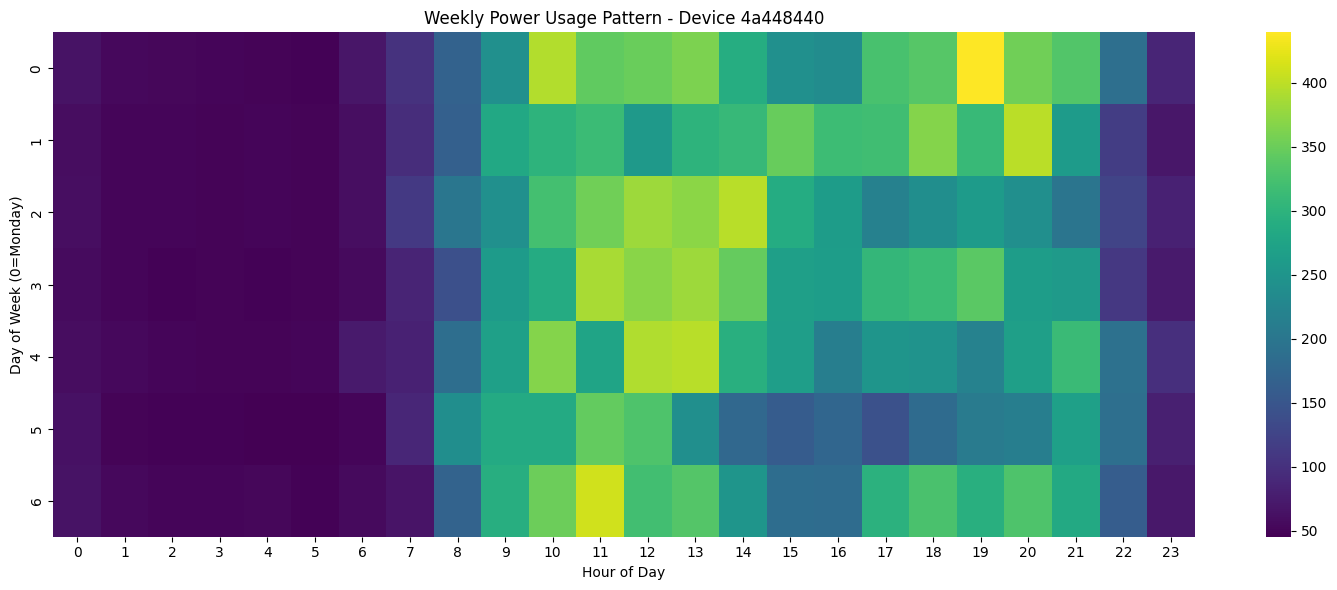

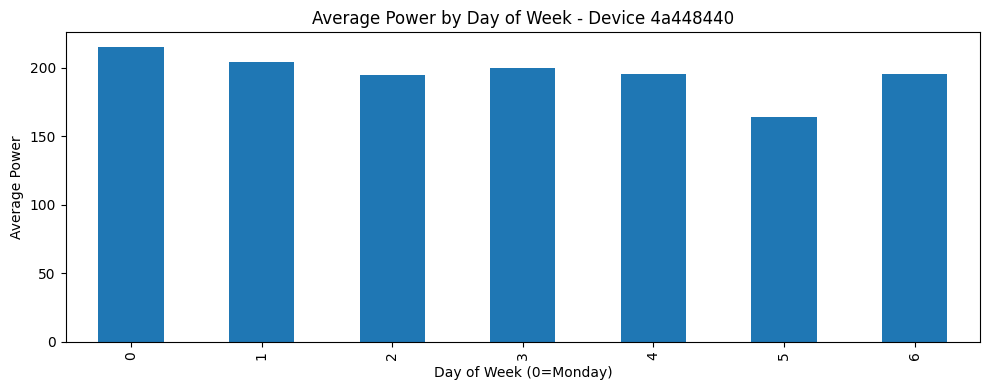

Device: fca96b30-ca2


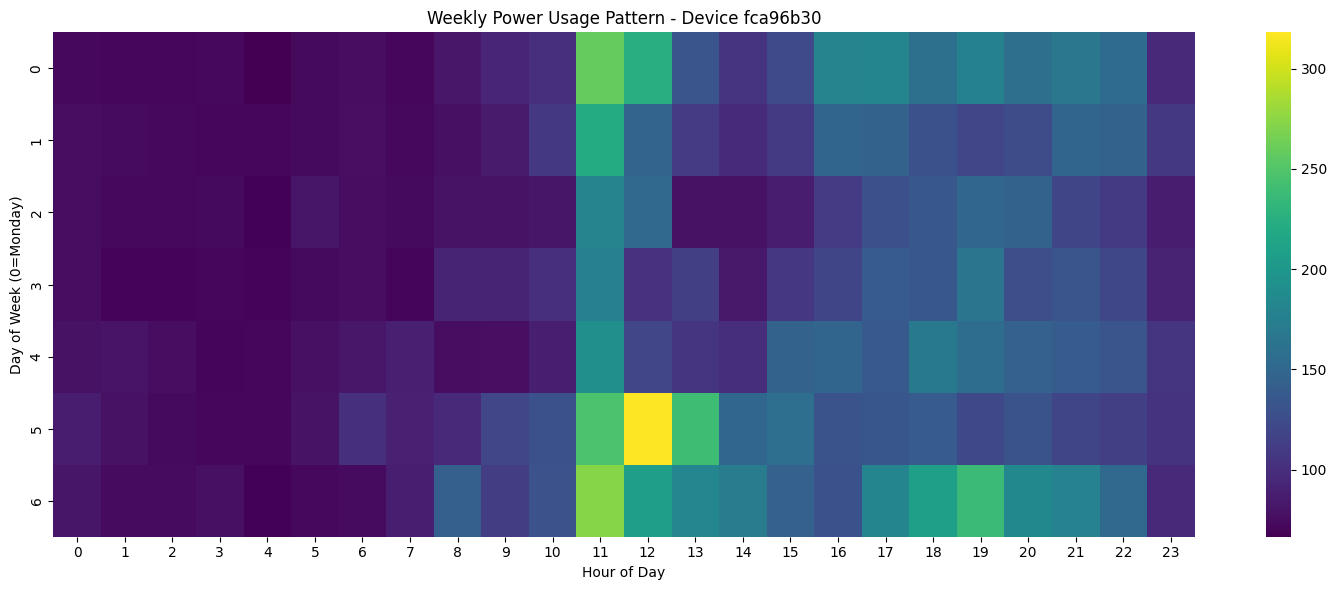

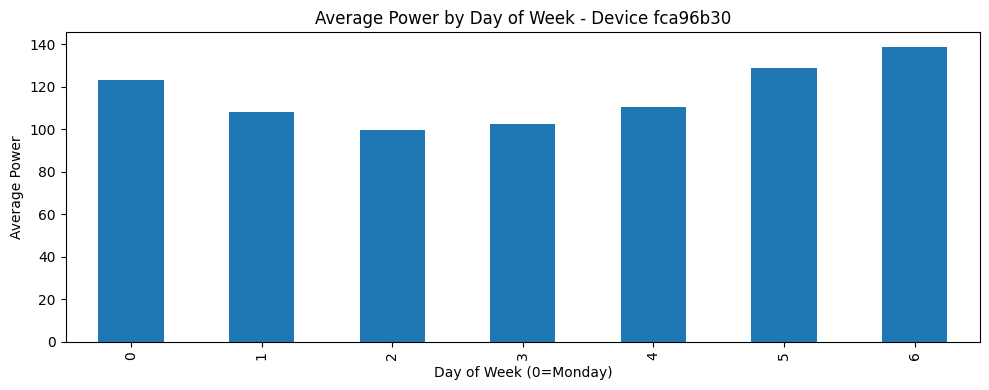

Device: 4ad3e3e6-5f1


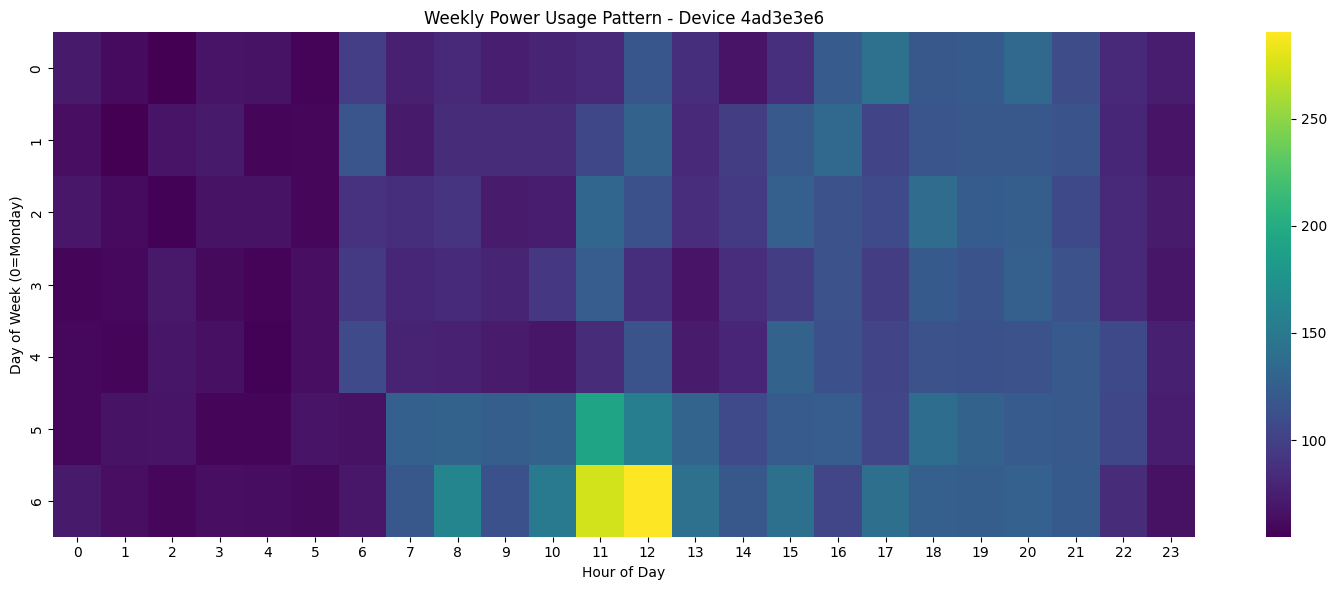

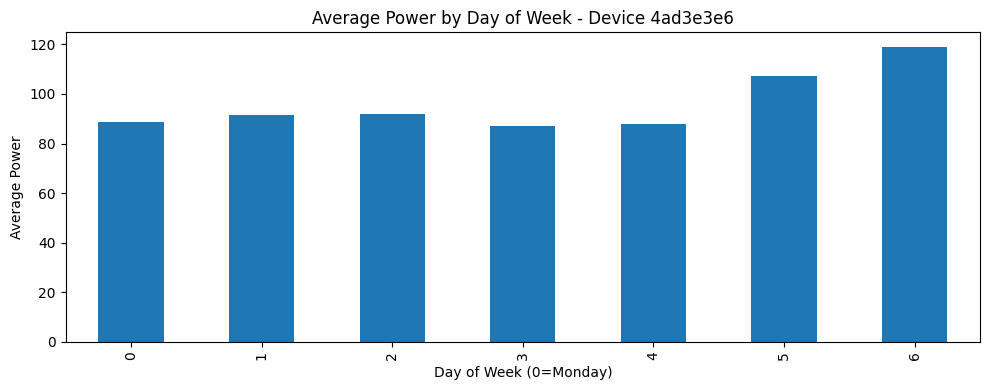

In [25]:
for device_id, hourly_data in hourly_data_dict.items():
    plt.figure(figsize=(15, 6))
    
    # Group by hour of day and day of week
    hourly_pattern = hourly_data.groupby([hourly_data.index.dayofweek, hourly_data.index.hour]).mean()
    hourly_pattern = hourly_pattern.unstack()
    
    
    print("="*100, f"\nDevice: {device_id[:12]}")

    # Create heatmap of weekly patterns
    sns.heatmap(hourly_pattern, cmap='viridis')
    plt.title(f"Weekly Power Usage Pattern - Device {device_id[:8]}")
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week (0=Monday)')
    plt.tight_layout()
    plt.show()
    
    # Also show daily averages
    plt.figure(figsize=(10, 4));
    hourly_data.groupby(hourly_data.index.dayofweek).mean().plot(kind='bar')
    plt.title(f"Average Power by Day of Week - Device {device_id[:8]}")
    plt.xlabel('Day of Week (0=Monday)')
    plt.ylabel('Average Power')
    plt.tight_layout()
    plt.show()

#### Autocorrelation Analysis

Device: f90e7387-981


<Figure size 1500x600 with 0 Axes>

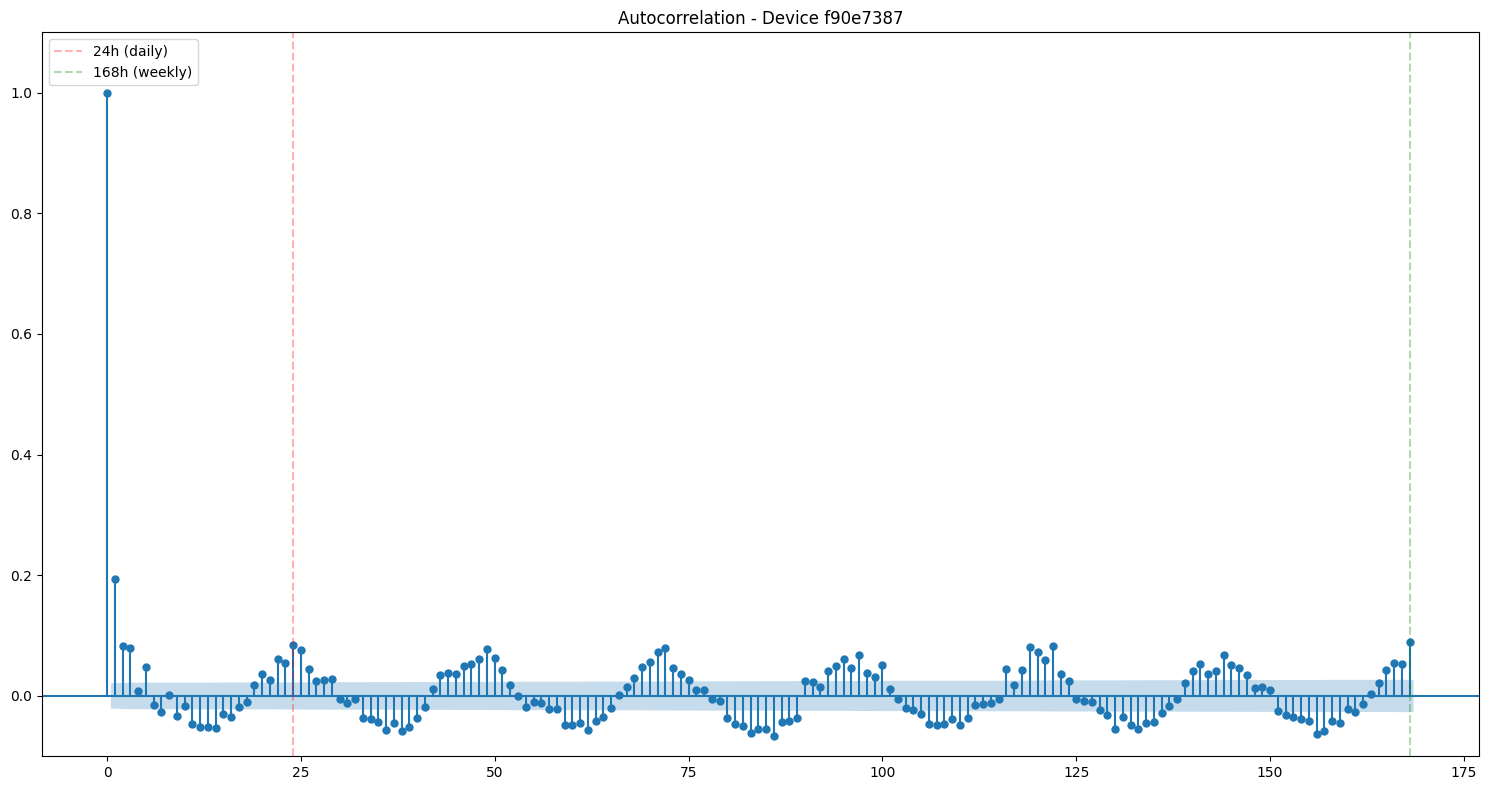

<Figure size 1500x600 with 0 Axes>

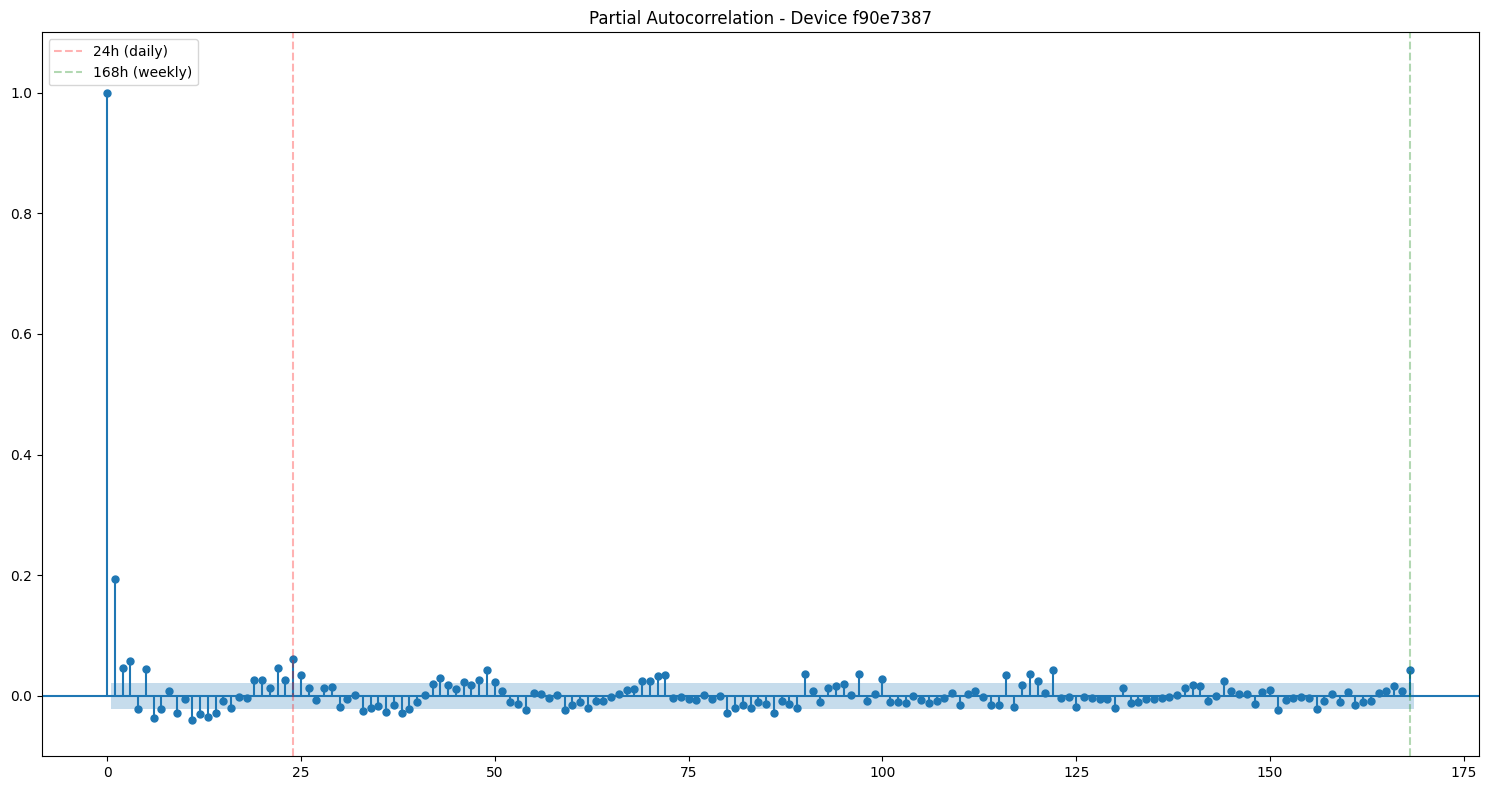

Device: dd40019b-5b3


<Figure size 1500x600 with 0 Axes>

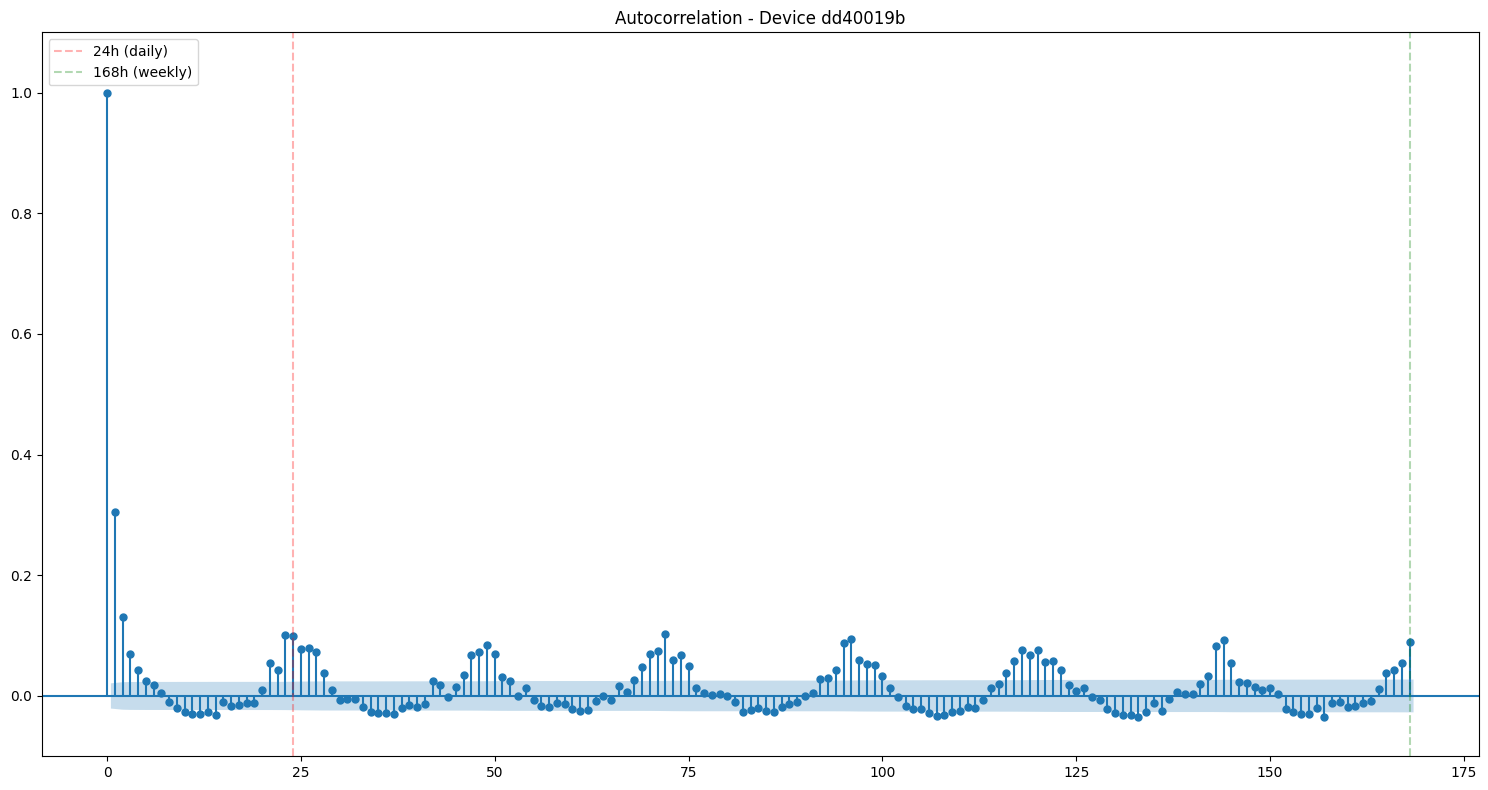

<Figure size 1500x600 with 0 Axes>

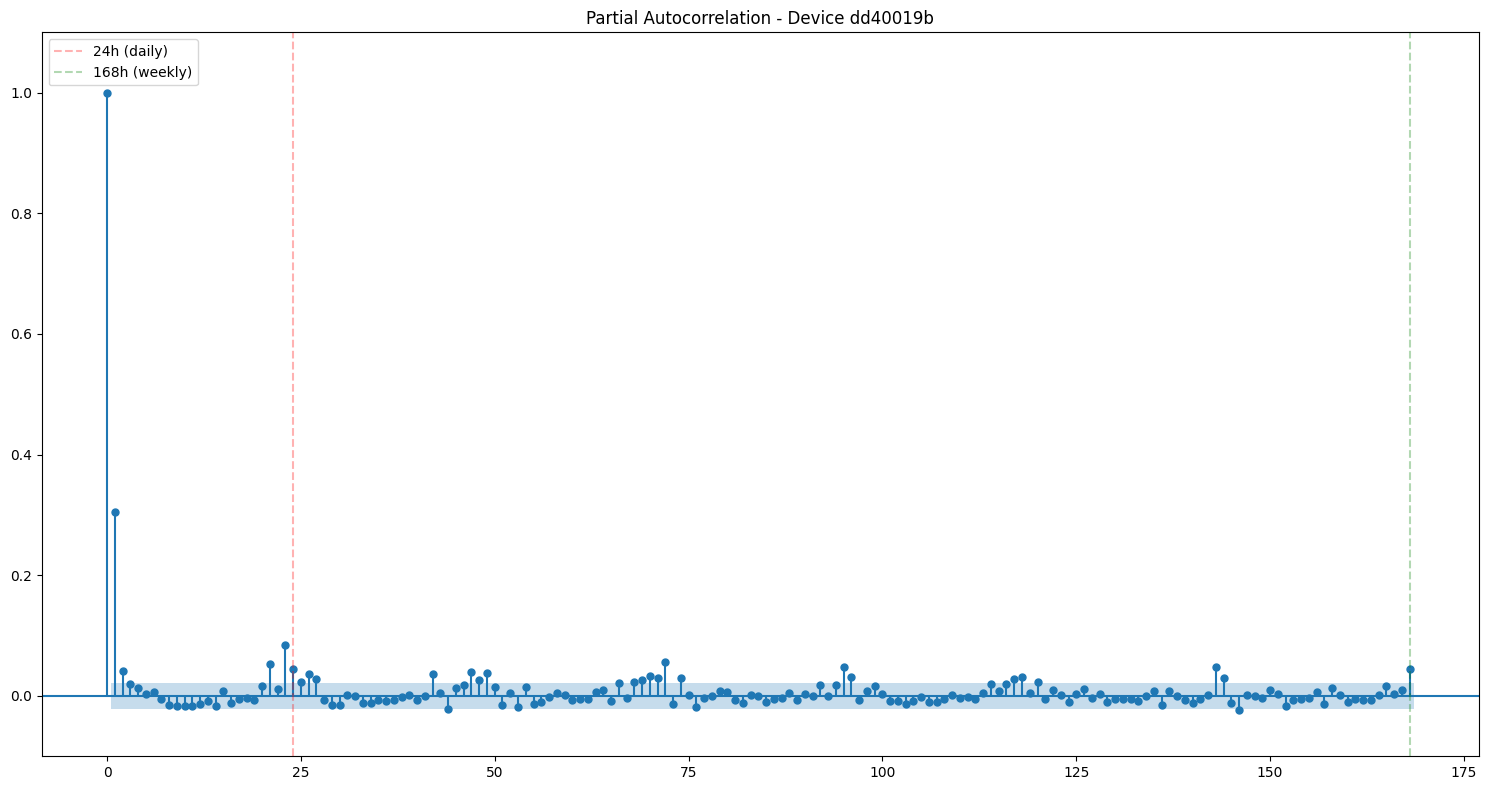

Device: 3617dc75-38d


<Figure size 1500x600 with 0 Axes>

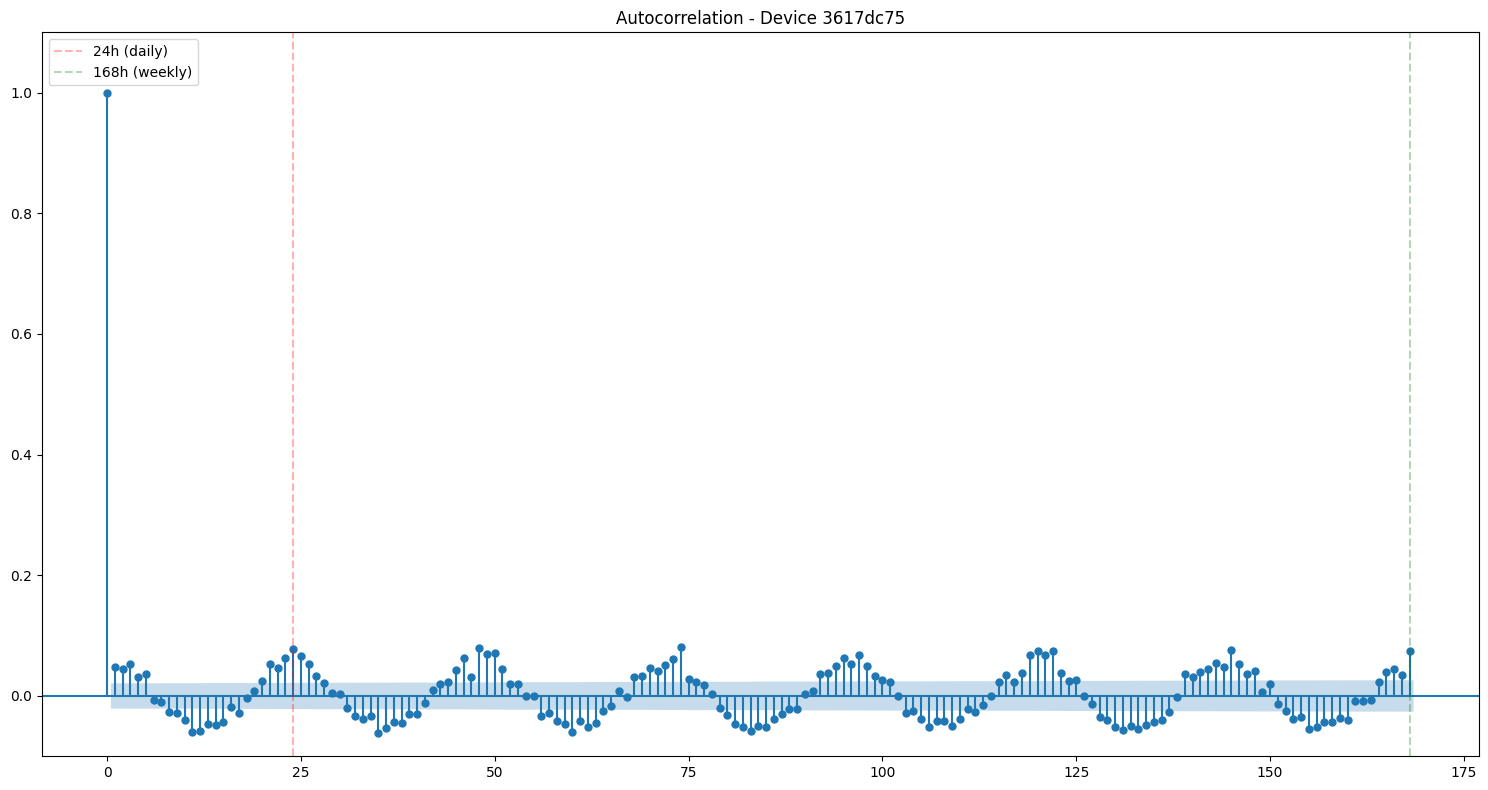

<Figure size 1500x600 with 0 Axes>

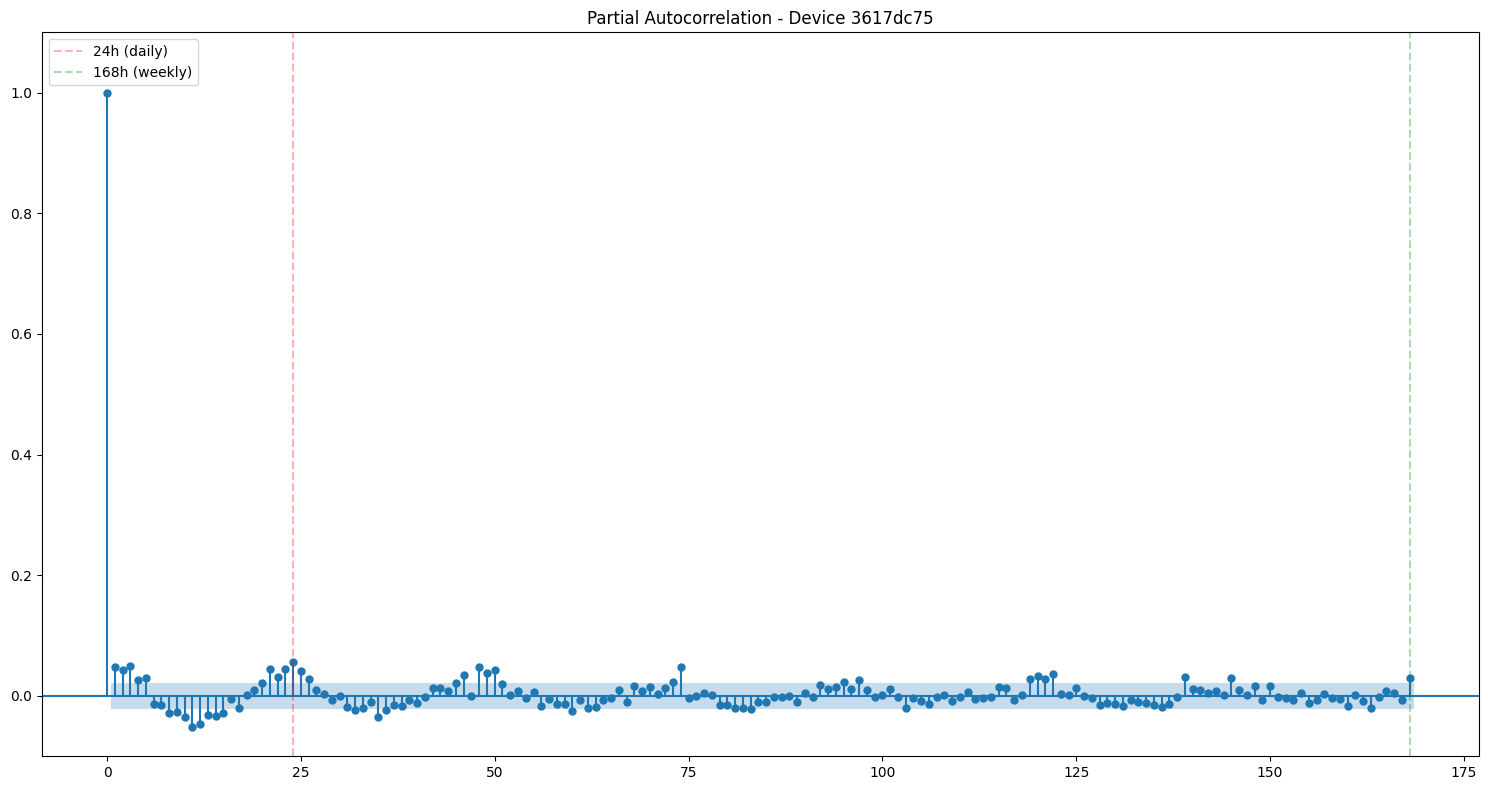

Device: a4b80cd7-543


<Figure size 1500x600 with 0 Axes>

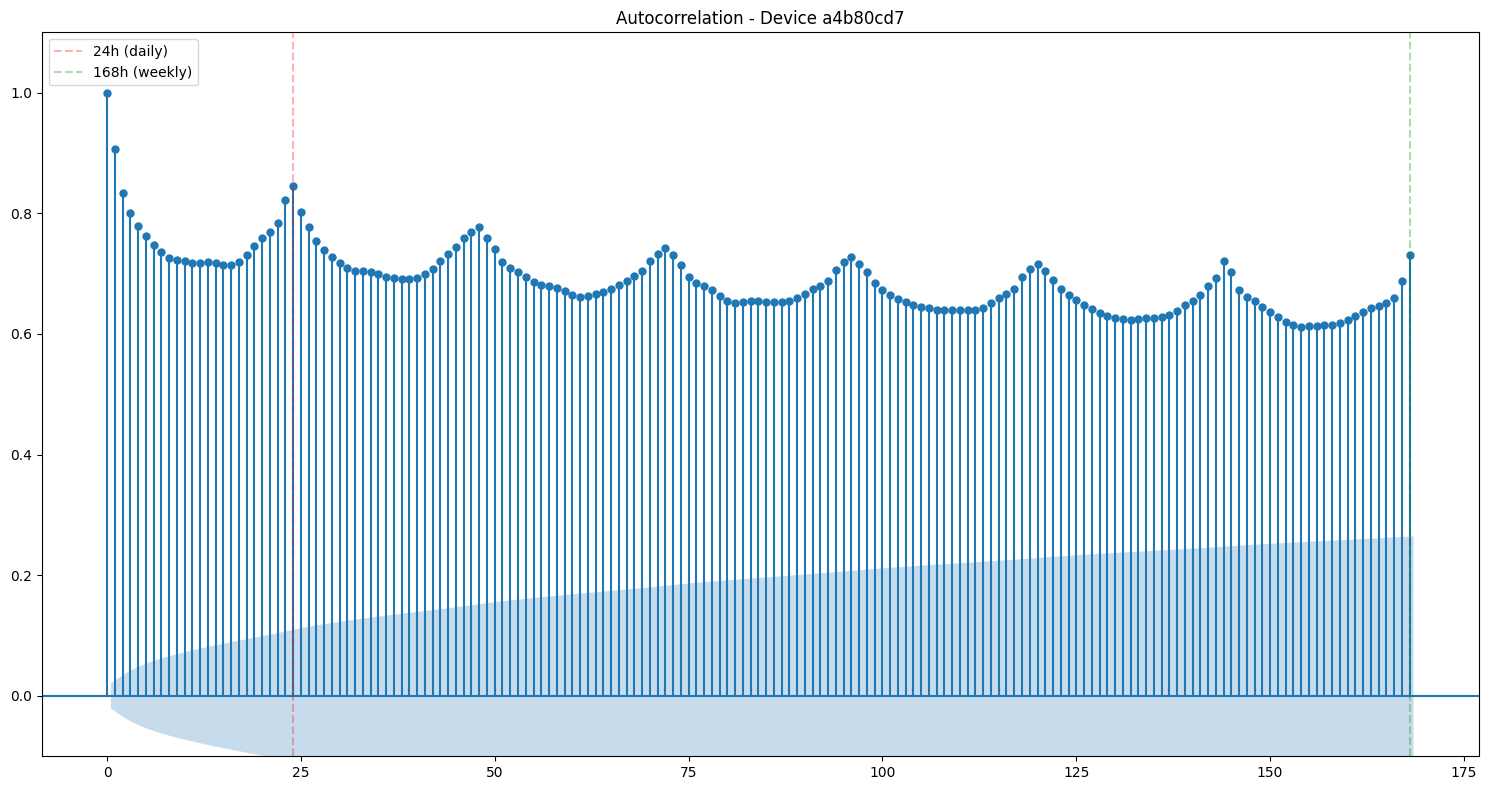

<Figure size 1500x600 with 0 Axes>

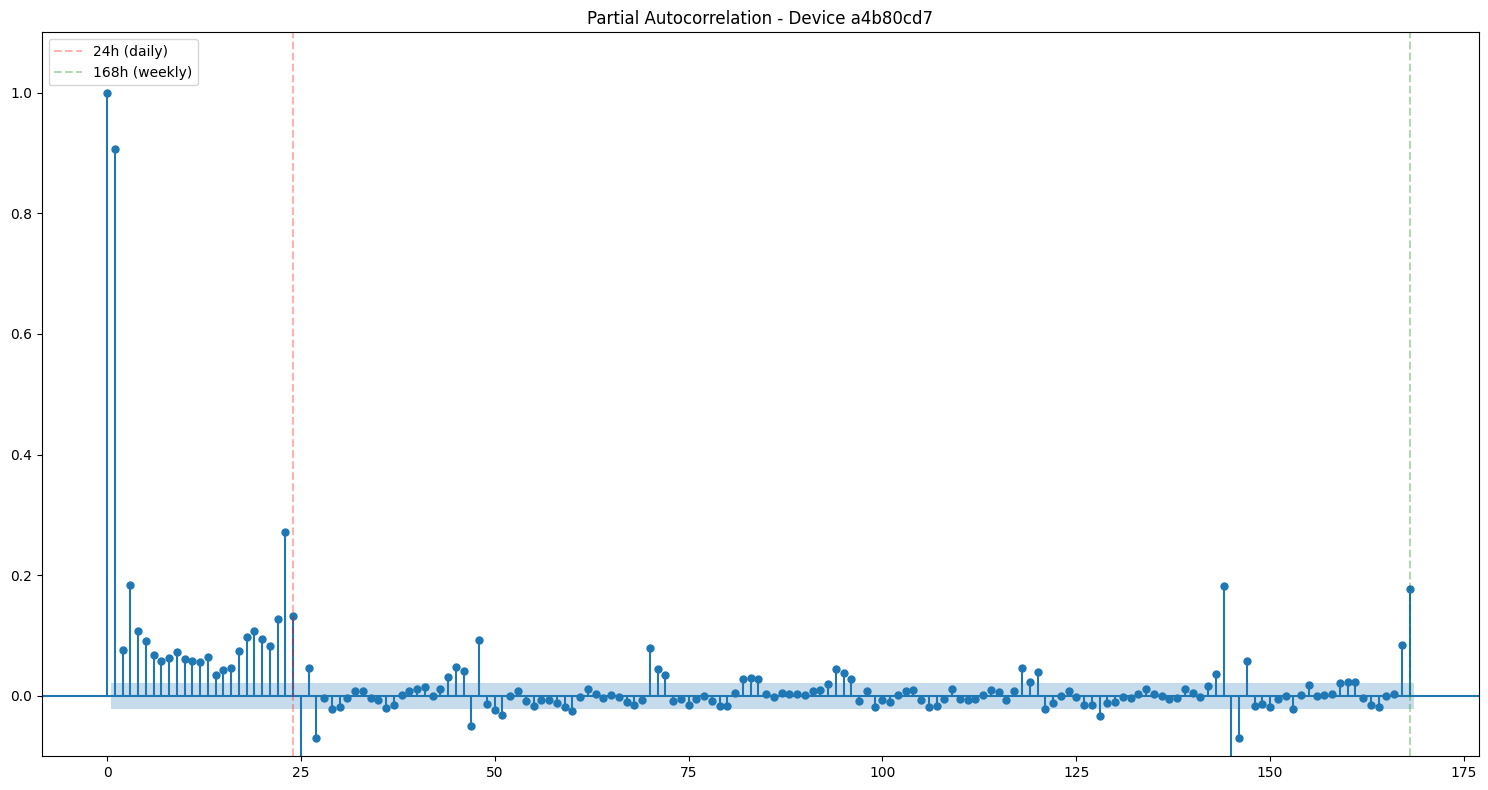

Device: 522e56a5-ff0


<Figure size 1500x600 with 0 Axes>

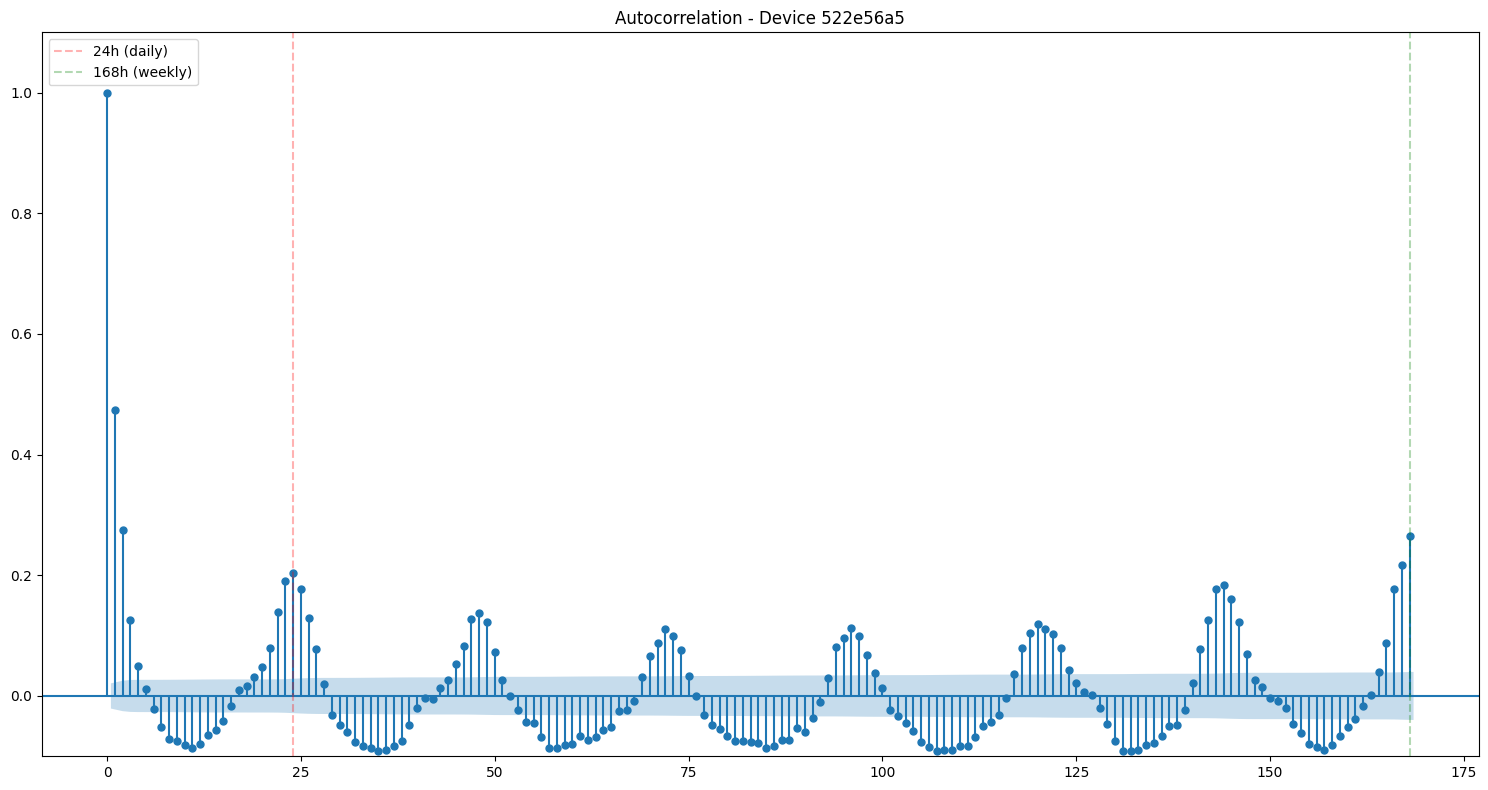

<Figure size 1500x600 with 0 Axes>

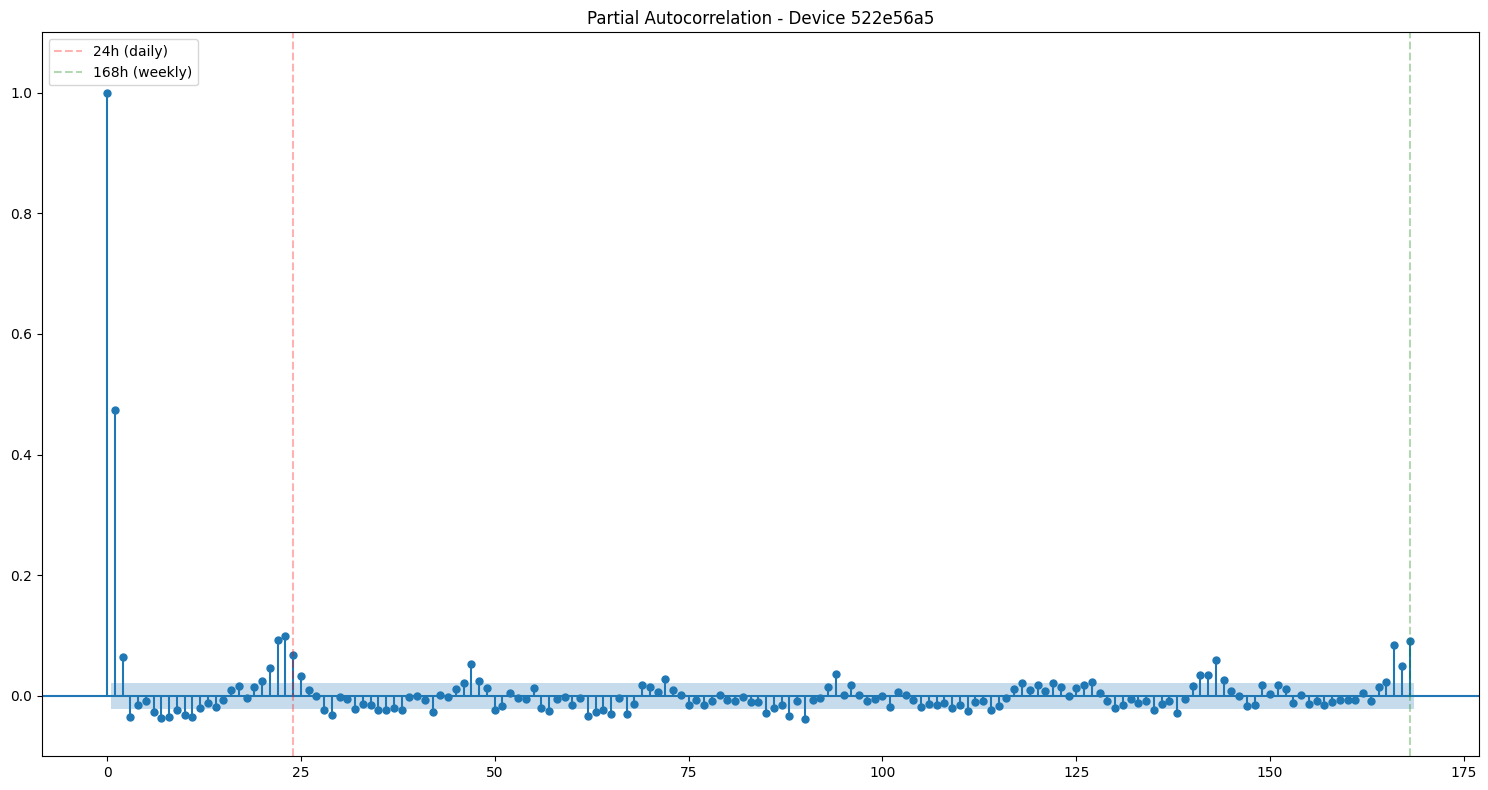

Device: 4a448440-d2d


<Figure size 1500x600 with 0 Axes>

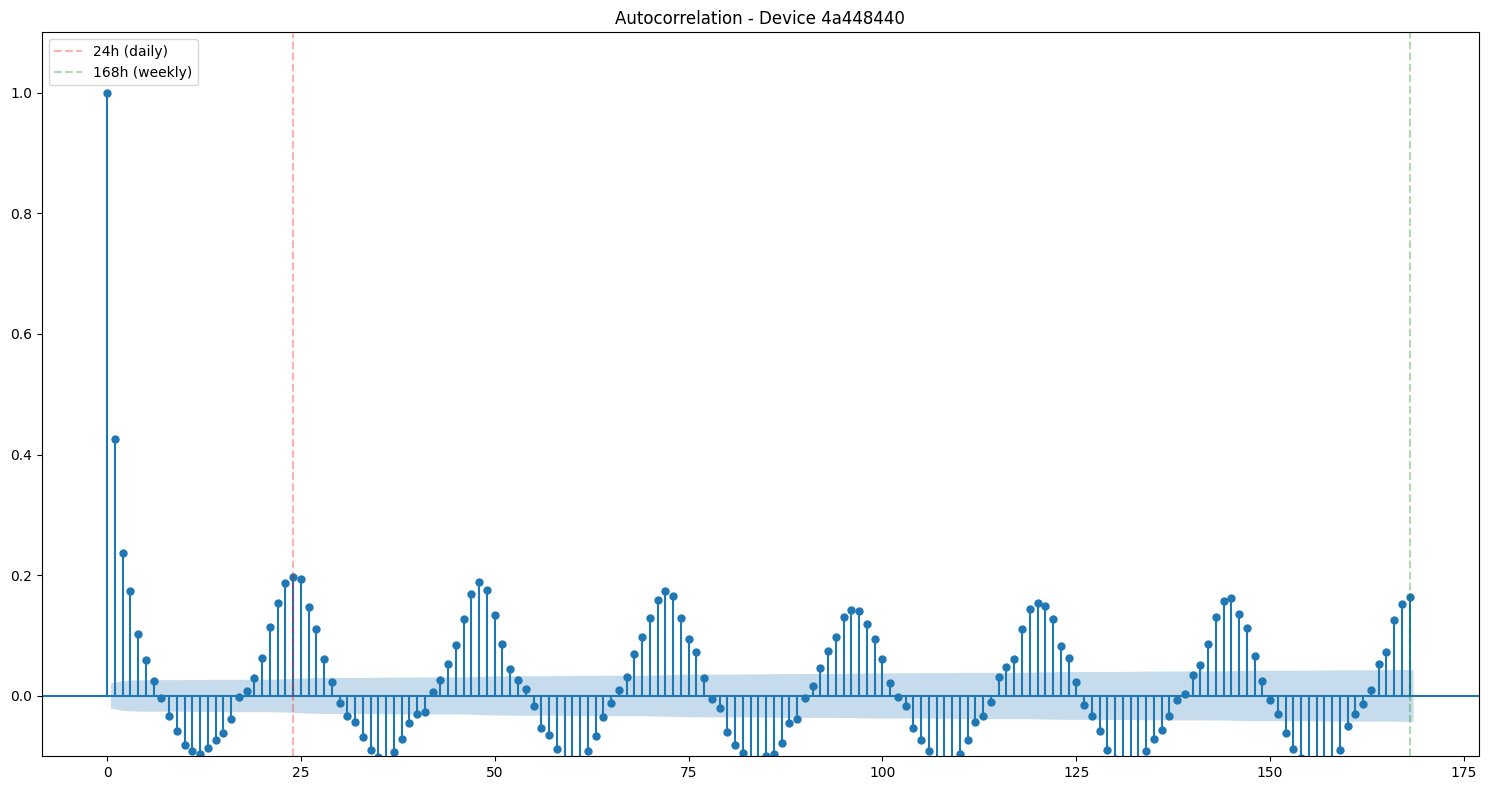

<Figure size 1500x600 with 0 Axes>

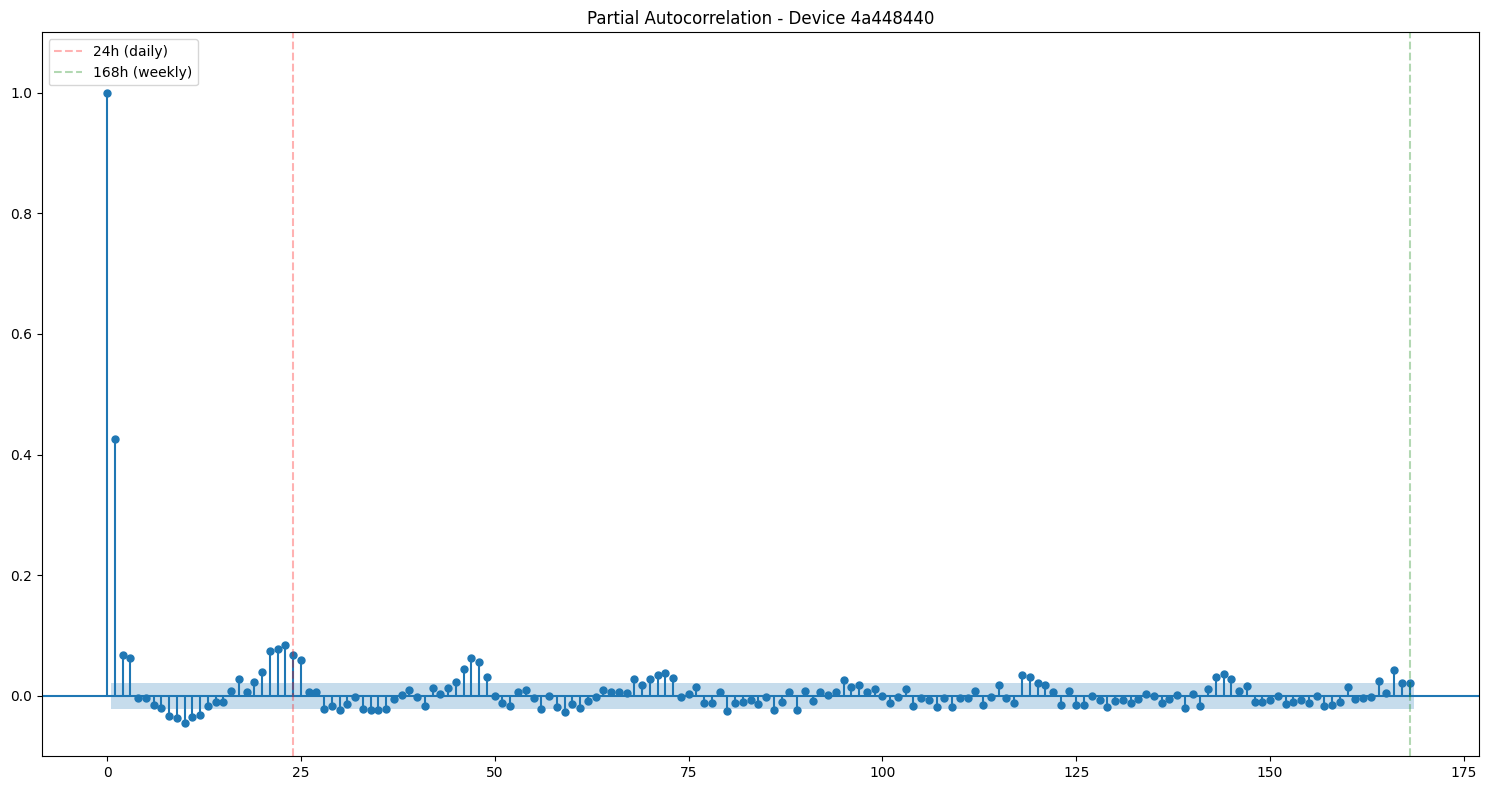

Device: fca96b30-ca2


<Figure size 1500x600 with 0 Axes>

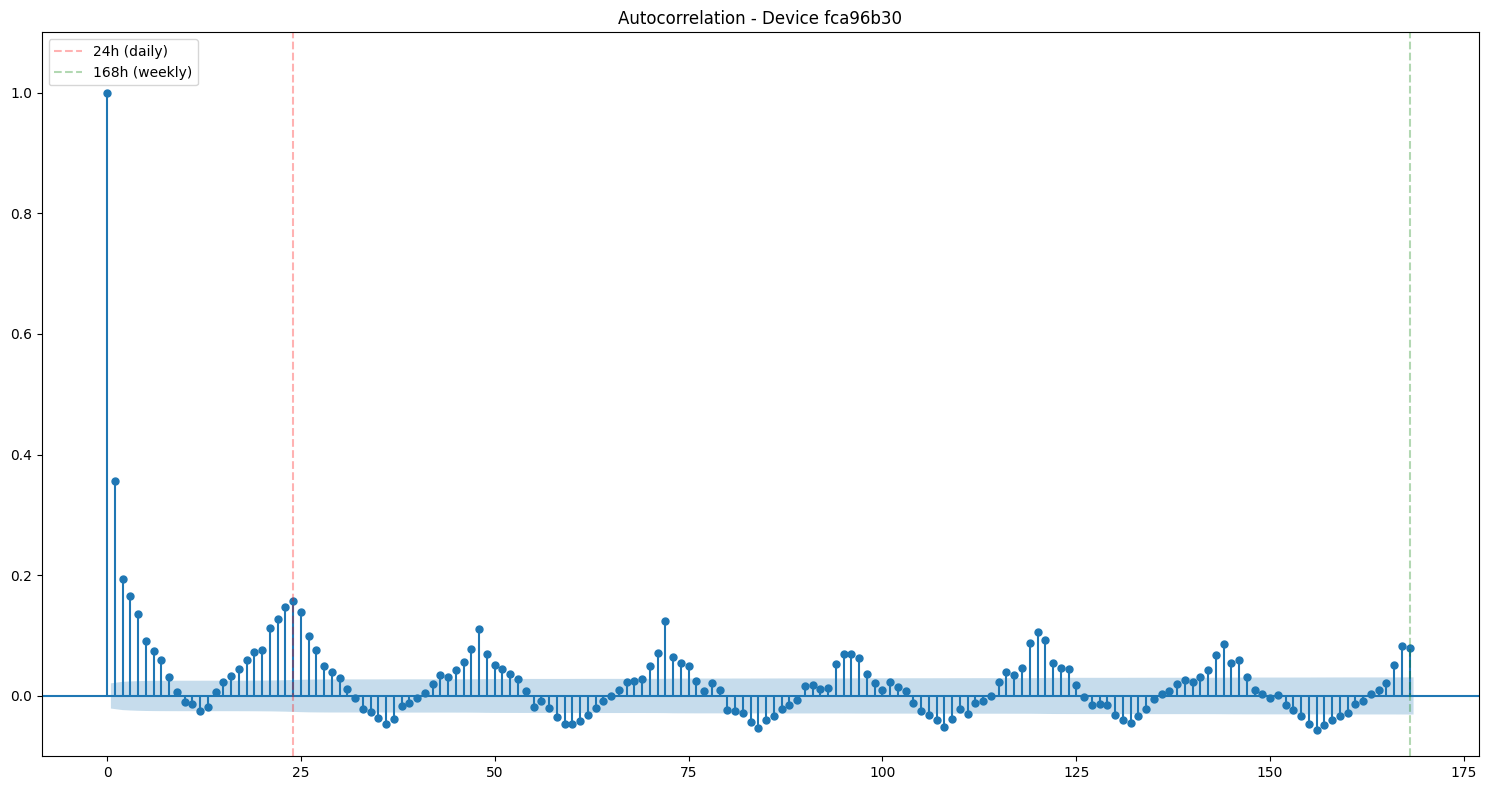

<Figure size 1500x600 with 0 Axes>

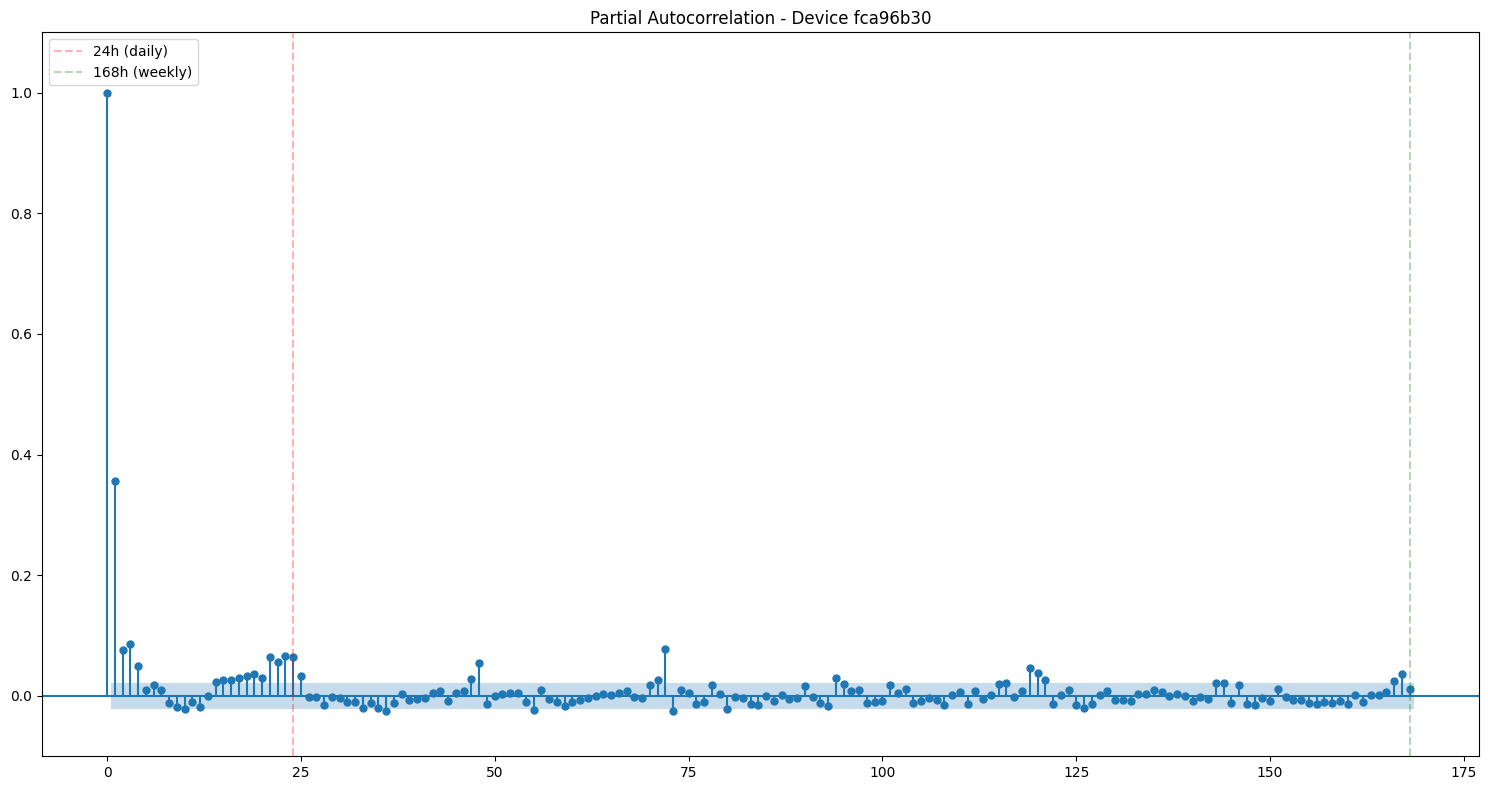

Device: 4ad3e3e6-5f1


<Figure size 1500x600 with 0 Axes>

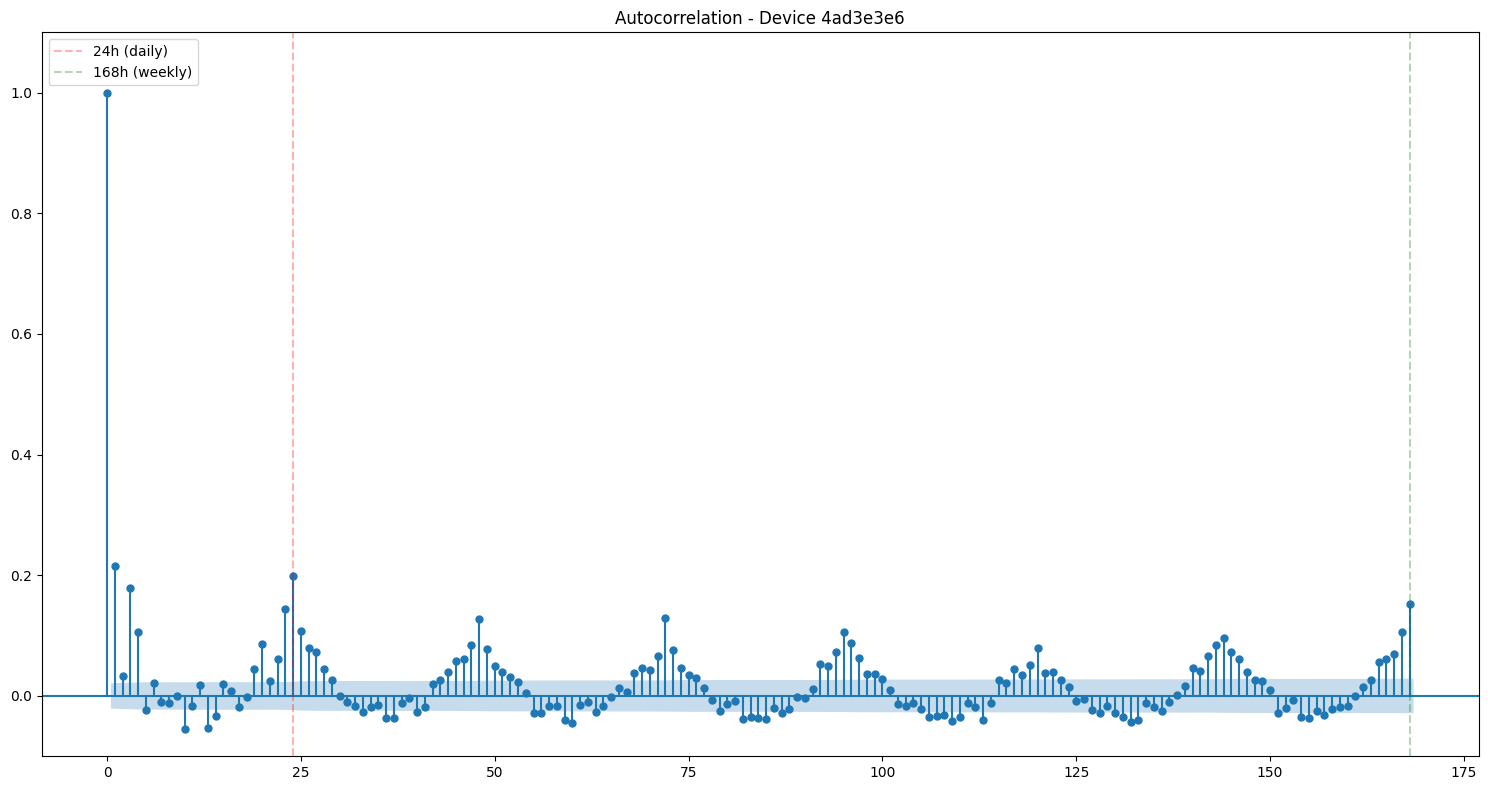

<Figure size 1500x600 with 0 Axes>

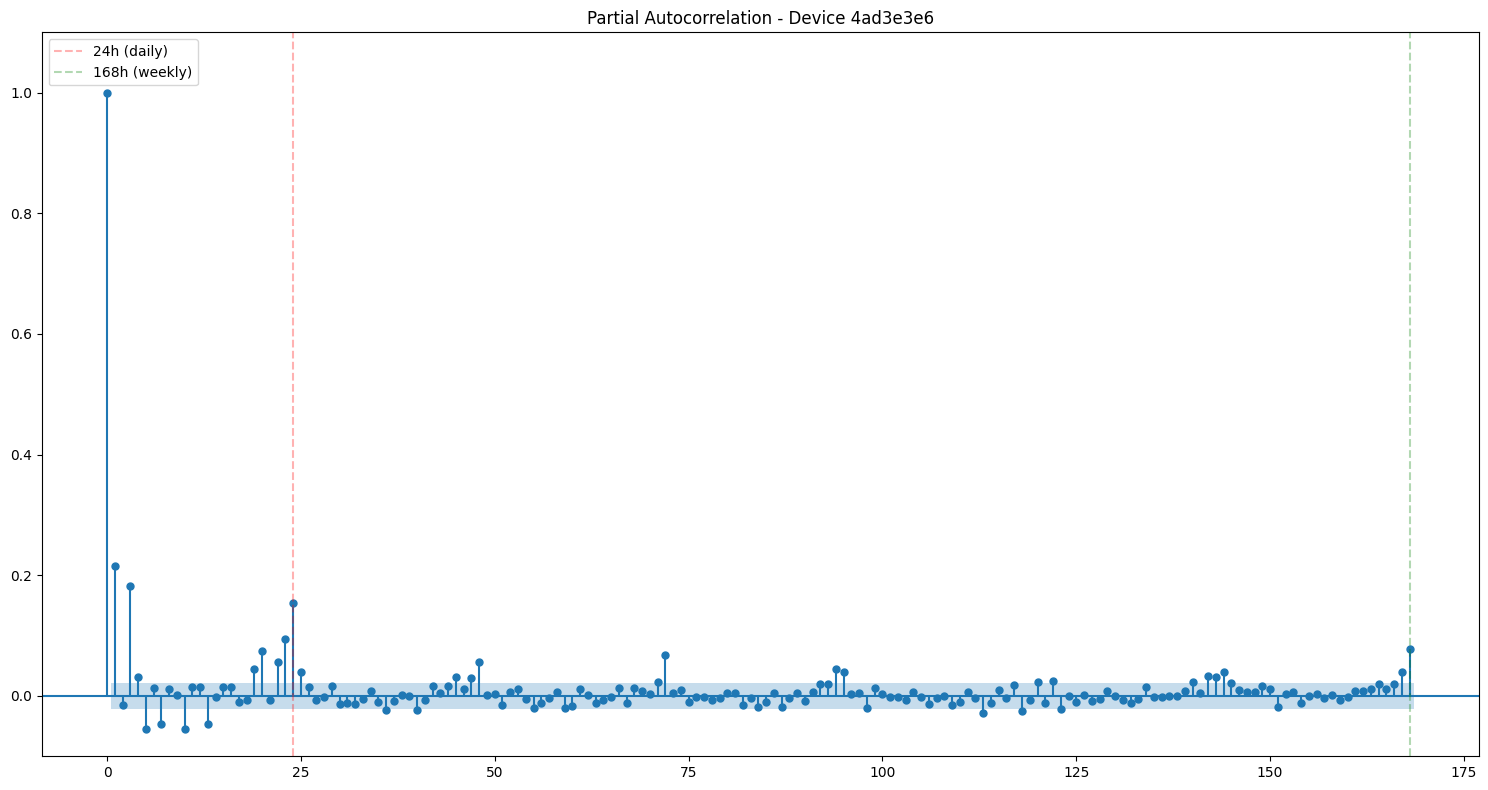

In [26]:
for device_id, hourly_data in hourly_data_dict.items():

    print("="*100,f"\nDevice: {device_id[:12]}")
    # Autocorrelation analysis for the device
    plt.figure(figsize=(15, 6))
    plot_acf(hourly_data.fillna(hourly_data.median()), lags=24*7, 
             title=f'Autocorrelation - Device {device_id[:8]}')
    plt.ylim(-0.1, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Partial autocorrelation analysis
    plt.figure(figsize=(15, 6))
    plot_pacf(hourly_data.fillna(hourly_data.median()), lags=24*7, 
              title=f'Partial Autocorrelation - Device {device_id[:8]}')
    plt.ylim(-0.1, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

### Frequency analysis (`total_power_active`)

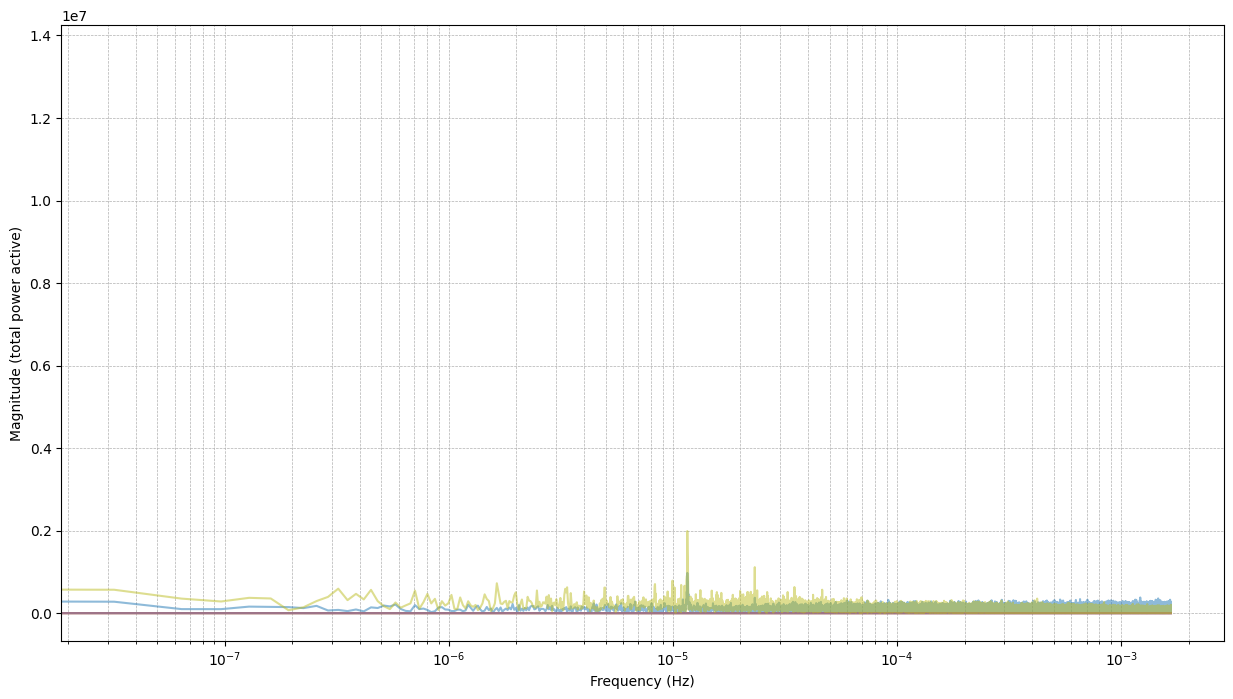

In [27]:
period = 5 * 60 # 5 mins
fs = 1/period

plt.figure()

# check 10 sensors
start_sensor_index = 5
end_sensor_offset = 10
for id in smart_meter_data.device_id[start_sensor_index:start_sensor_index+end_sensor_offset]:
  meter_data_N = smart_meter_data[smart_meter_data.device_id == id]
  meter_data_N = meter_data_N.drop(columns=['device_id', 'serial_number'])
  signal = meter_data_N.groupby(meter_data_N['time']).mean()["total_power_active"]

  fft_result = np.fft.fft(signal)
  n = len(signal)
  freq = np.fft.fftfreq(n, d=1/fs)

  fft_result_shifted = np.fft.fftshift(fft_result)
  freq_shifted = np.fft.fftshift(freq)

  N = 10
  half_len = int(len(freq_shifted)/2)
  plt.plot(freq_shifted[half_len:],np.abs(fft_result_shifted[half_len:]), label=f"Device {id}", alpha=0.5)

plt.xscale("log")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (total power active)")
plt.show()


### Analysis of `total_energy_active.diff(1)`

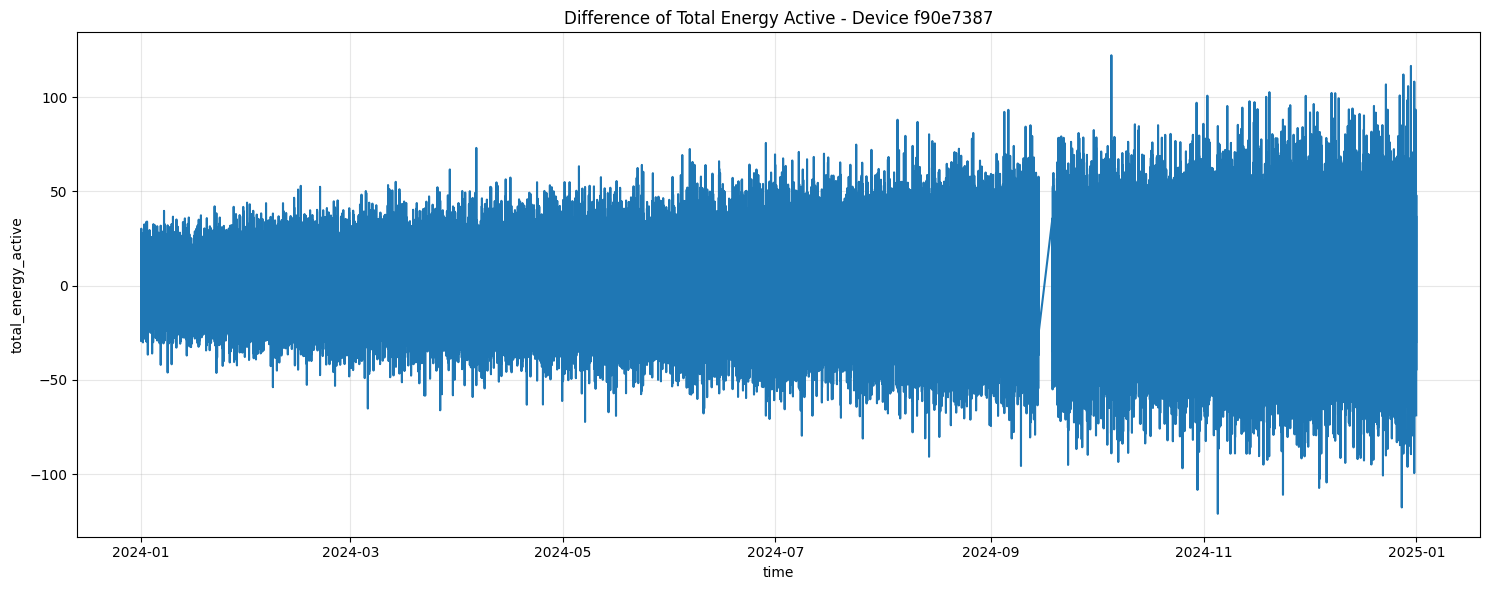

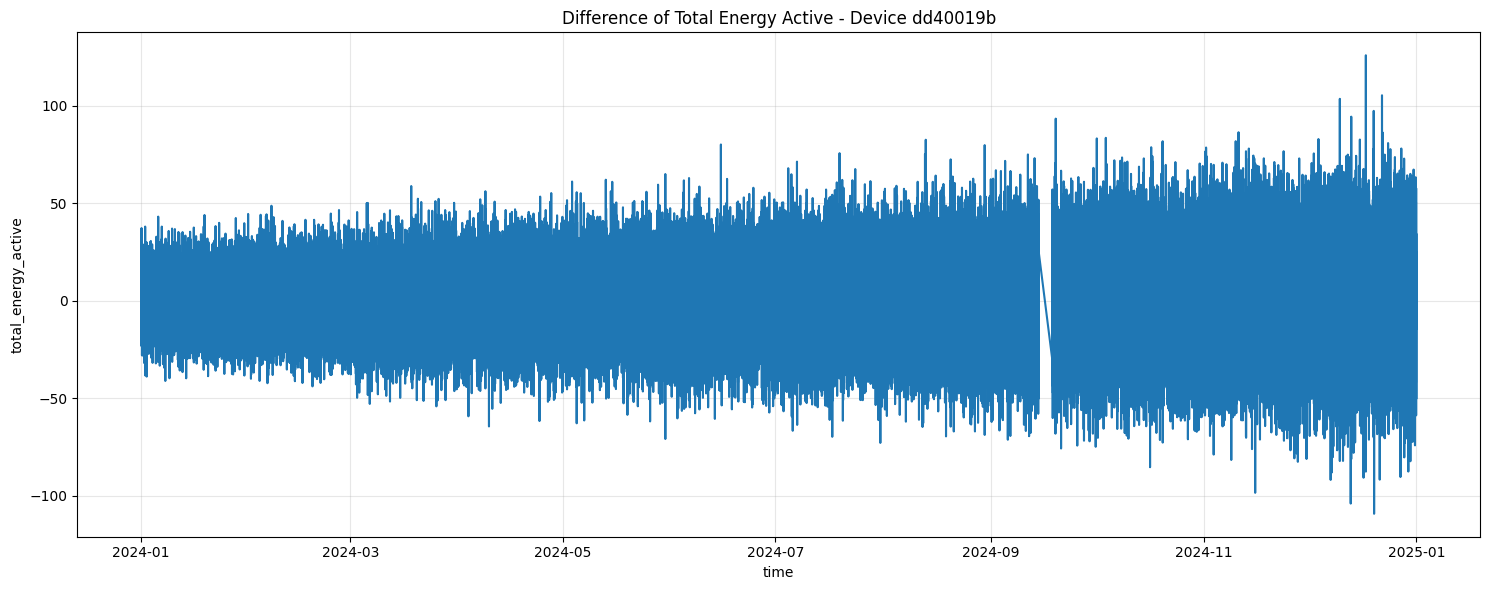

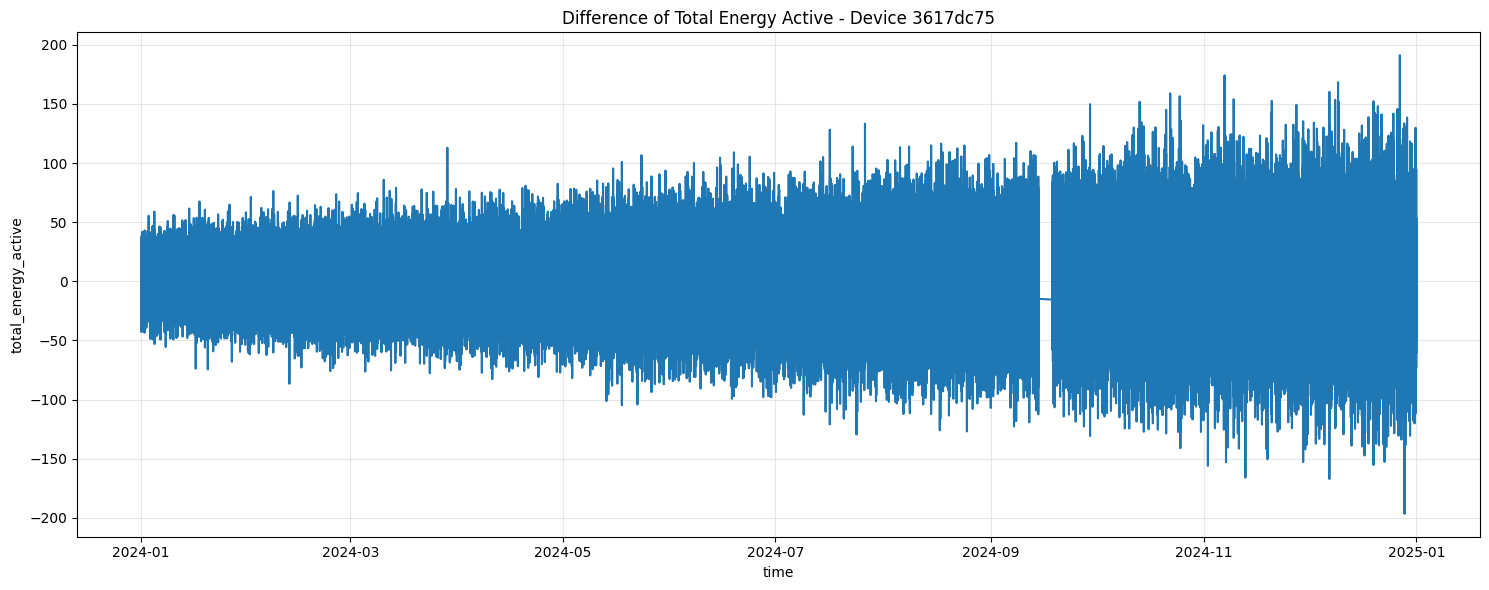

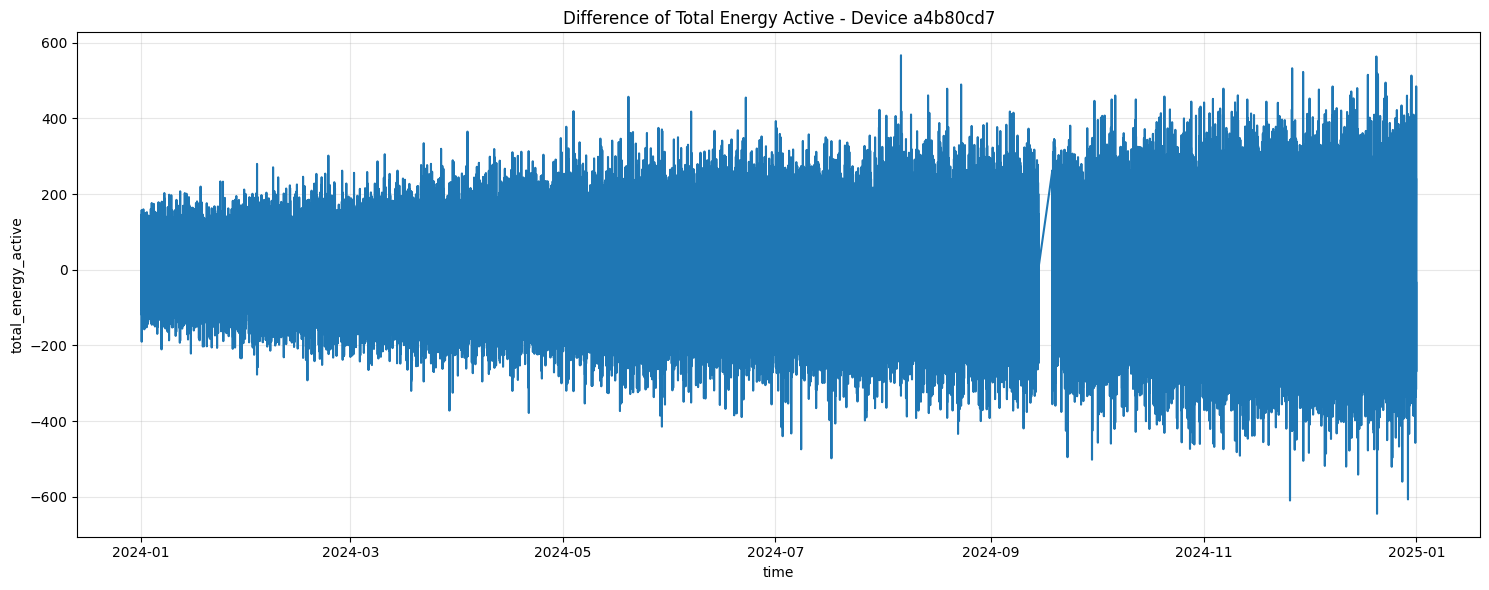

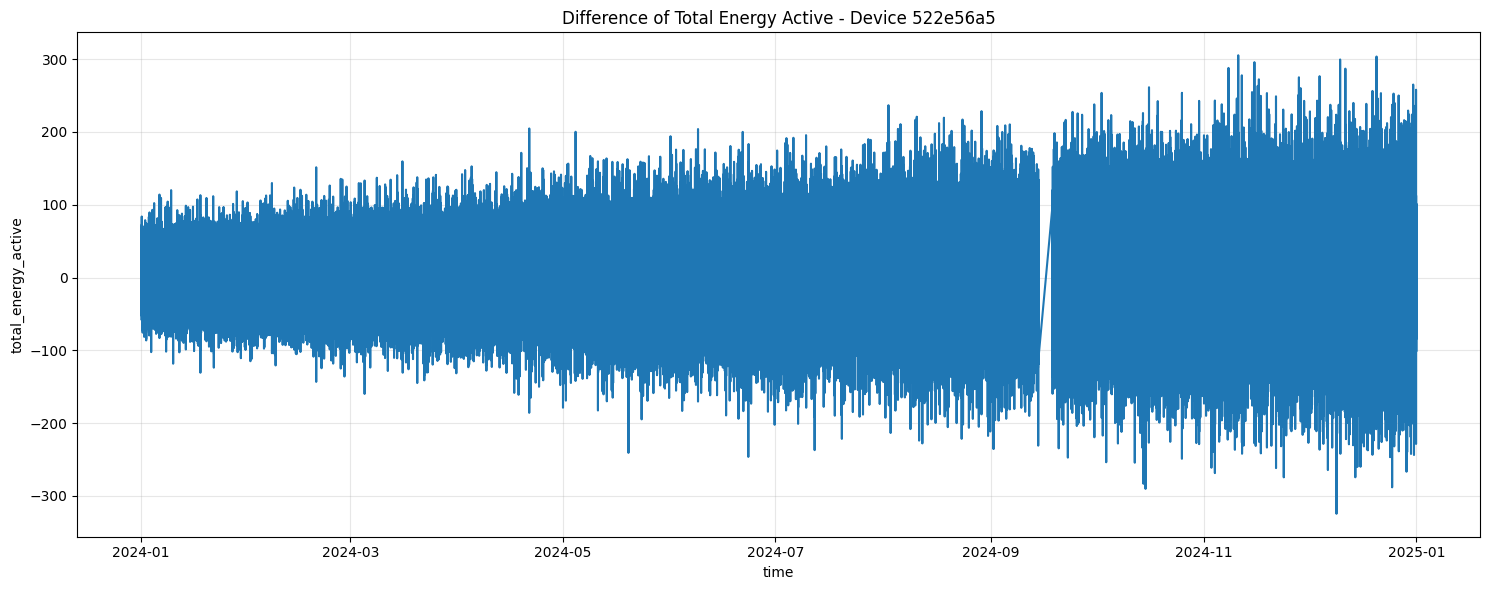

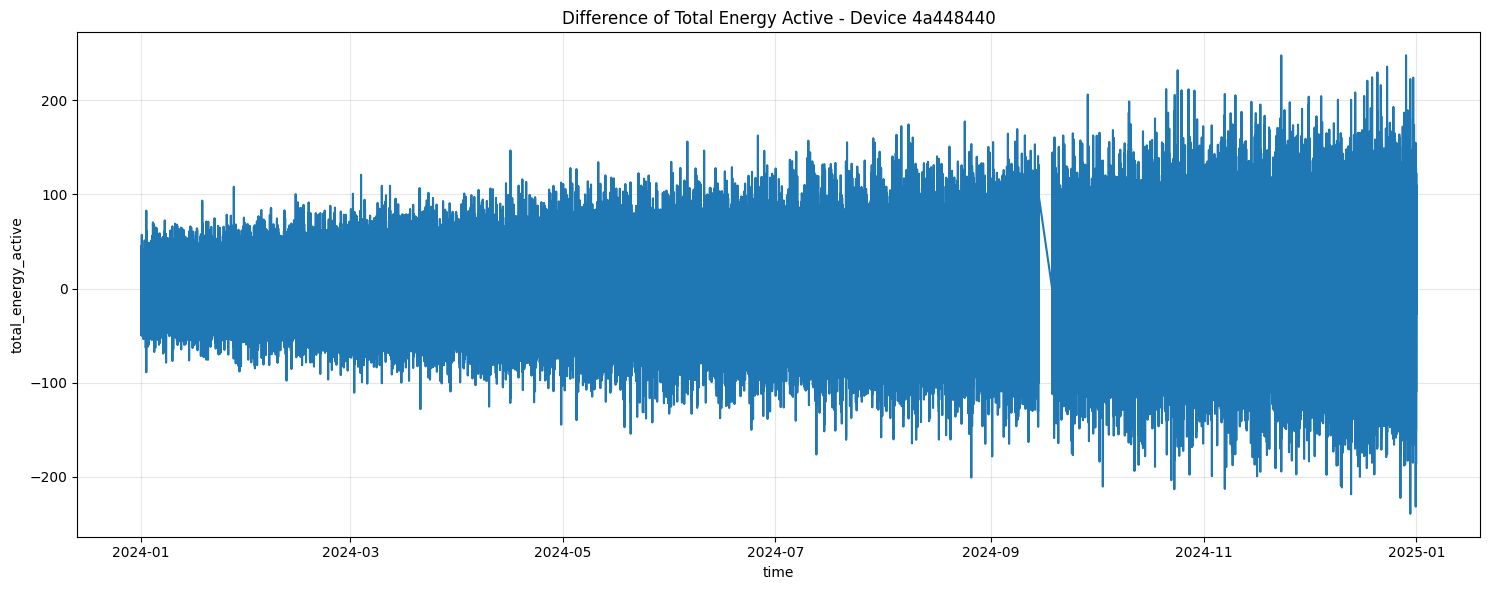

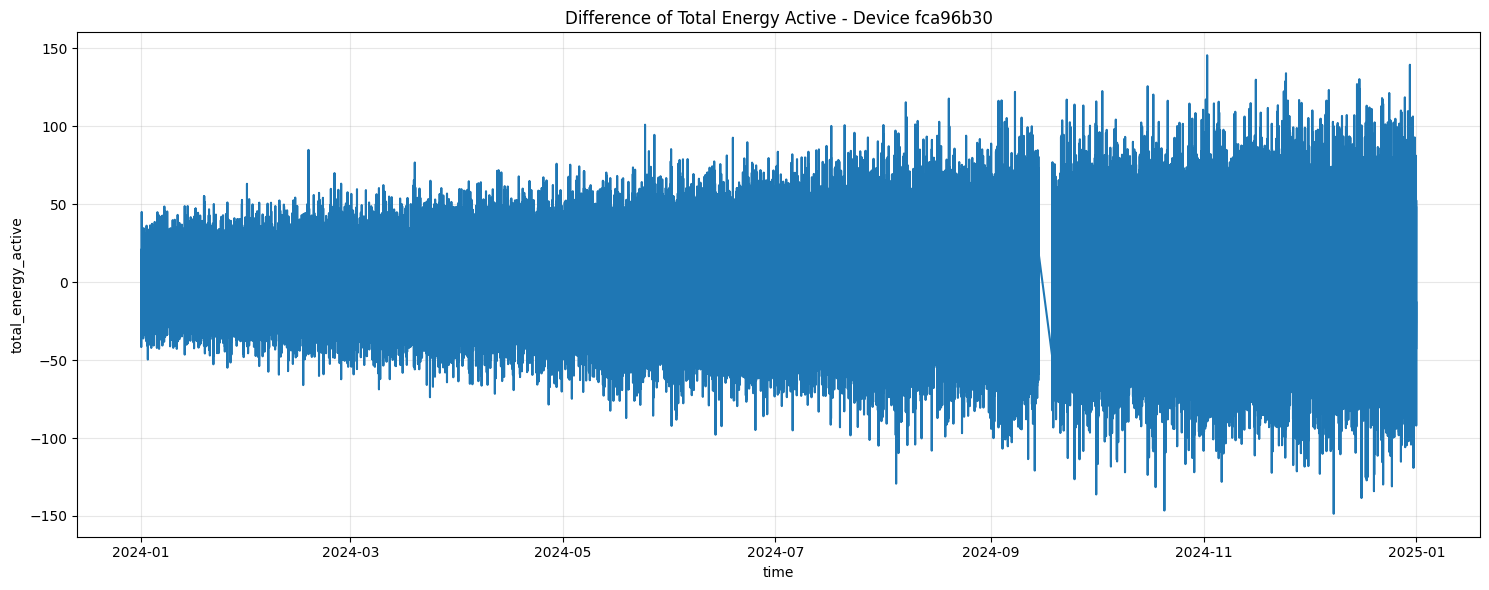

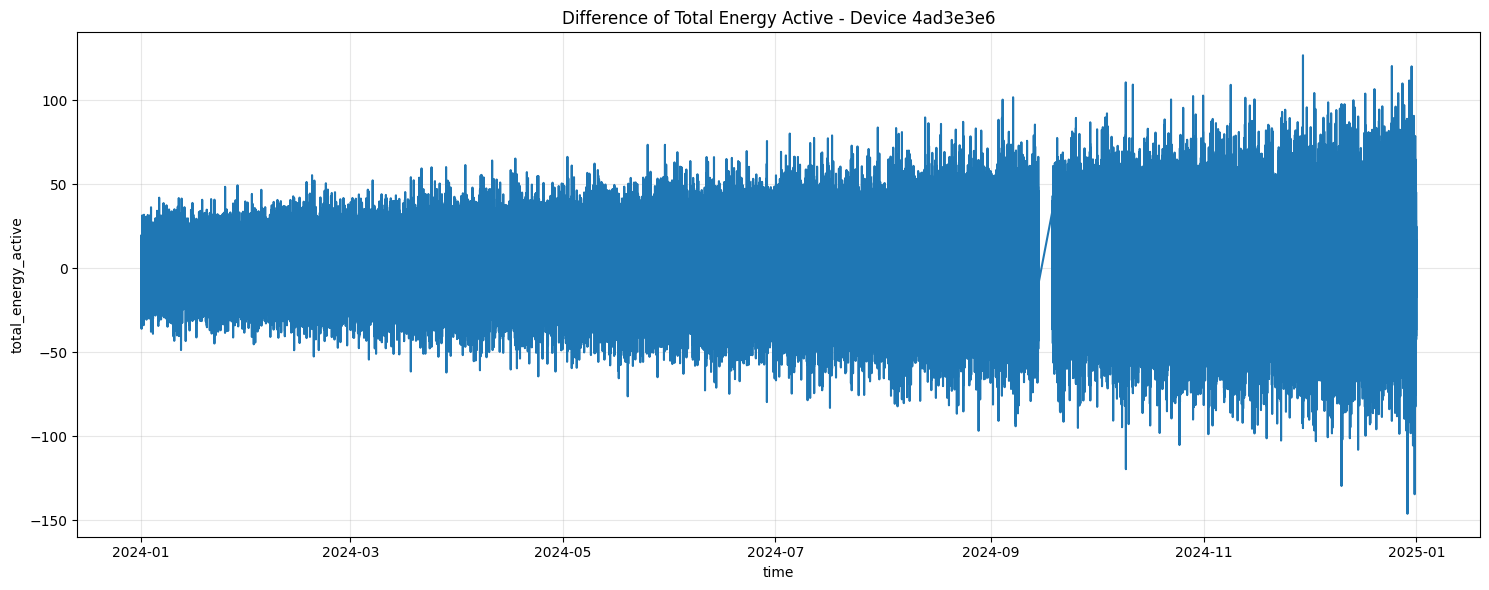

In [28]:
for device_id, meter_data in meter_data_dict.items():
    plt.figure(figsize=(15, 6))
    
    # Plotting the difference of the total energy active
    sns.lineplot(x=meter_data['time'], y=meter_data['total_energy_active'].diff(1))
    plt.title(f"Difference of Total Energy Active - Device {device_id[:8]}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

#### Hourly Visualization

In [33]:
# Create hourly aggregations for each meter
hourly_diff_data_dict = {}

for device_id, meter_data in meter_data_dict.items():
    # Group by hour
    hourly_meter_data = meter_data.diff(1).groupby(meter_data['time'].dt.floor('h'))
    
    # Create index for full time range
    full_range = pd.DataFrame(
        index=pd.date_range(
            pd.DatetimeIndex(hourly_meter_data.indices.keys()).min(),
            pd.DatetimeIndex(hourly_meter_data.indices.keys()).max(), 
            freq='h'
        )
    )
    
    # Join with hourly aggregated data
    tot_pow_hour_endog = full_range.join(hourly_meter_data['total_energy_active'].mean(), how='left').squeeze()
    hourly_diff_data_dict[device_id] = tot_pow_hour_endog

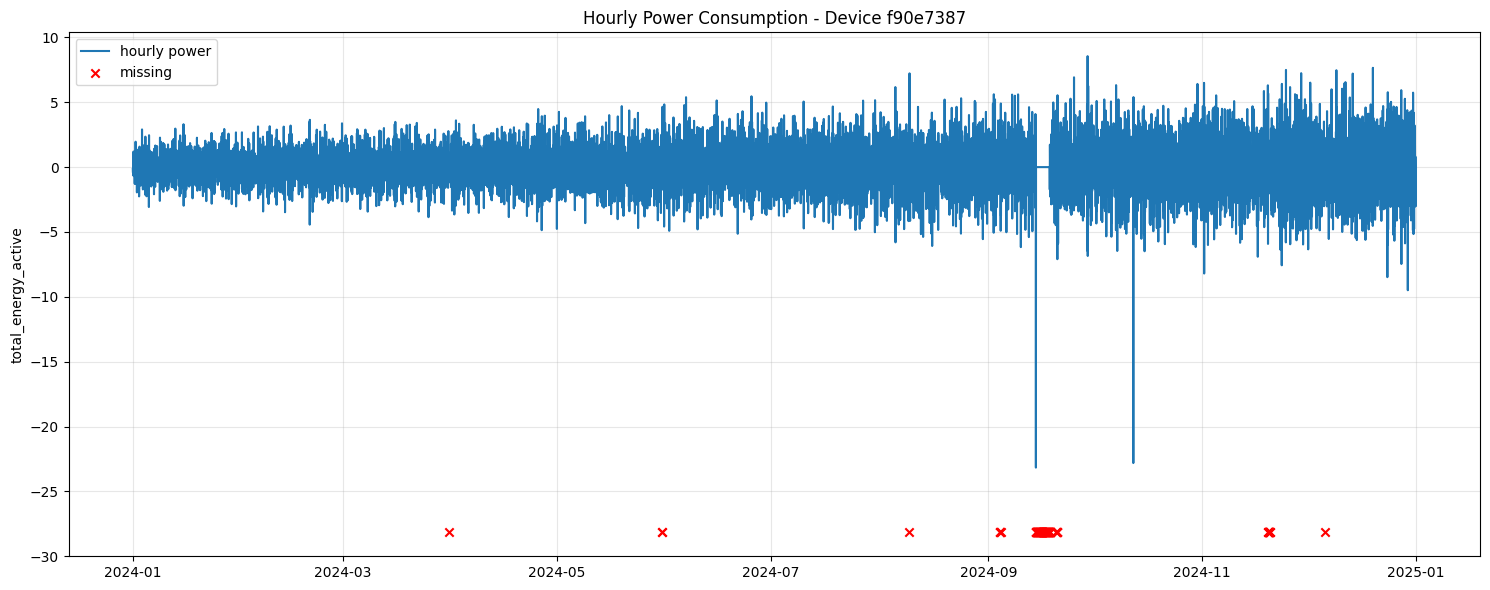

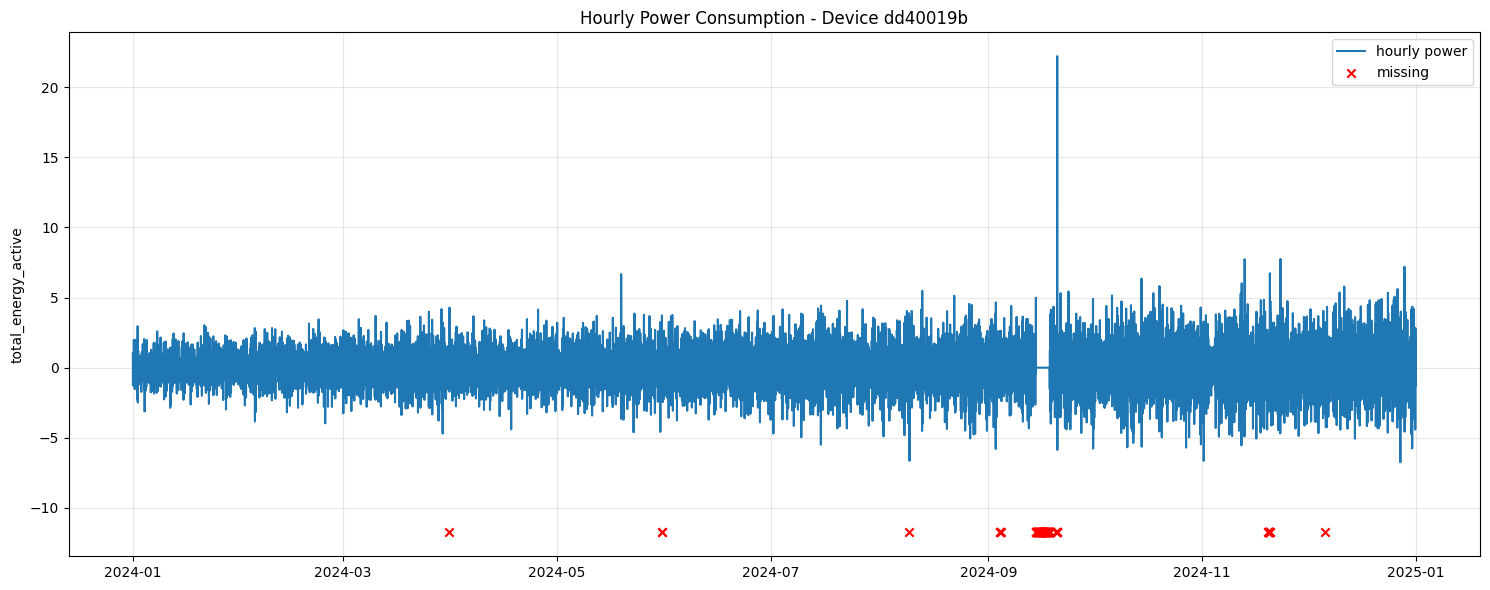

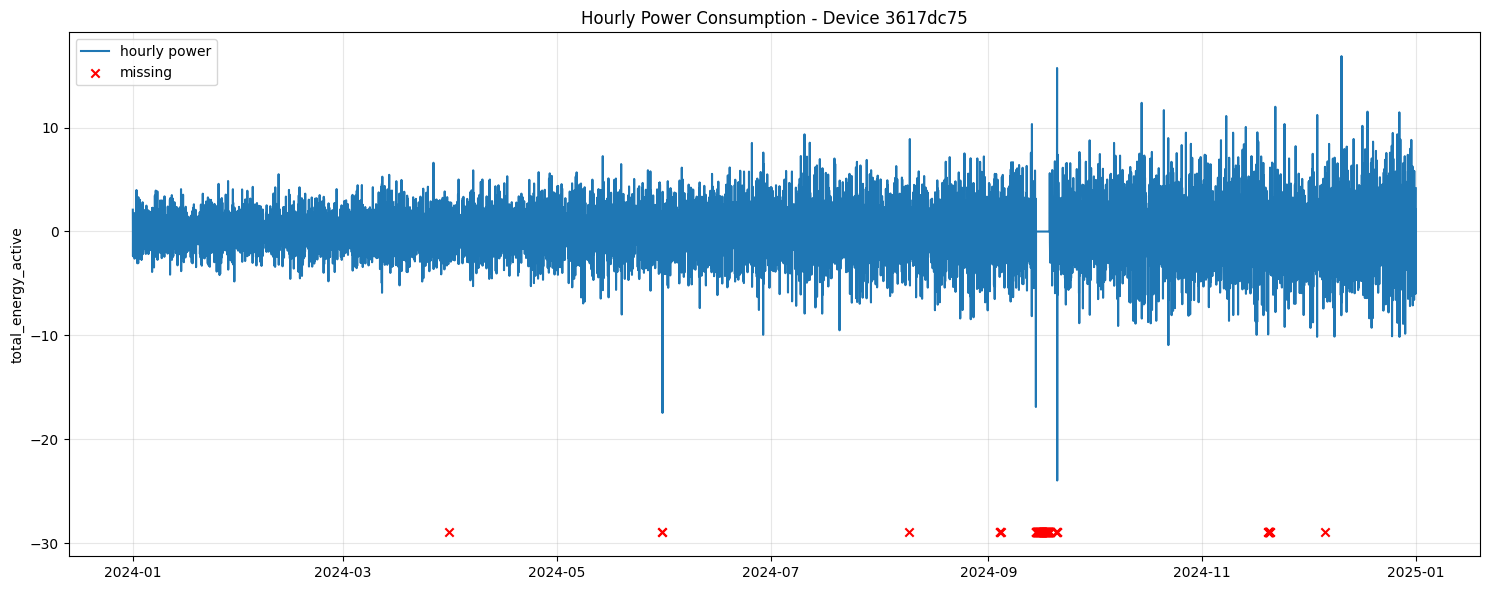

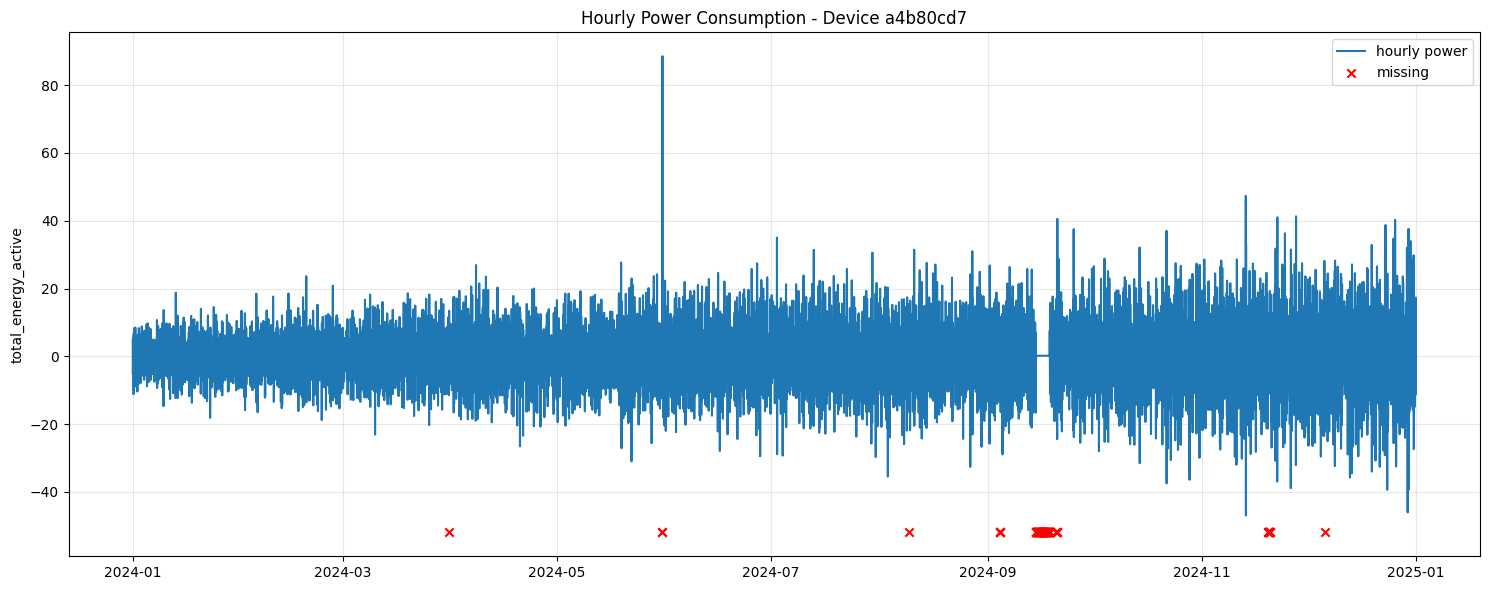

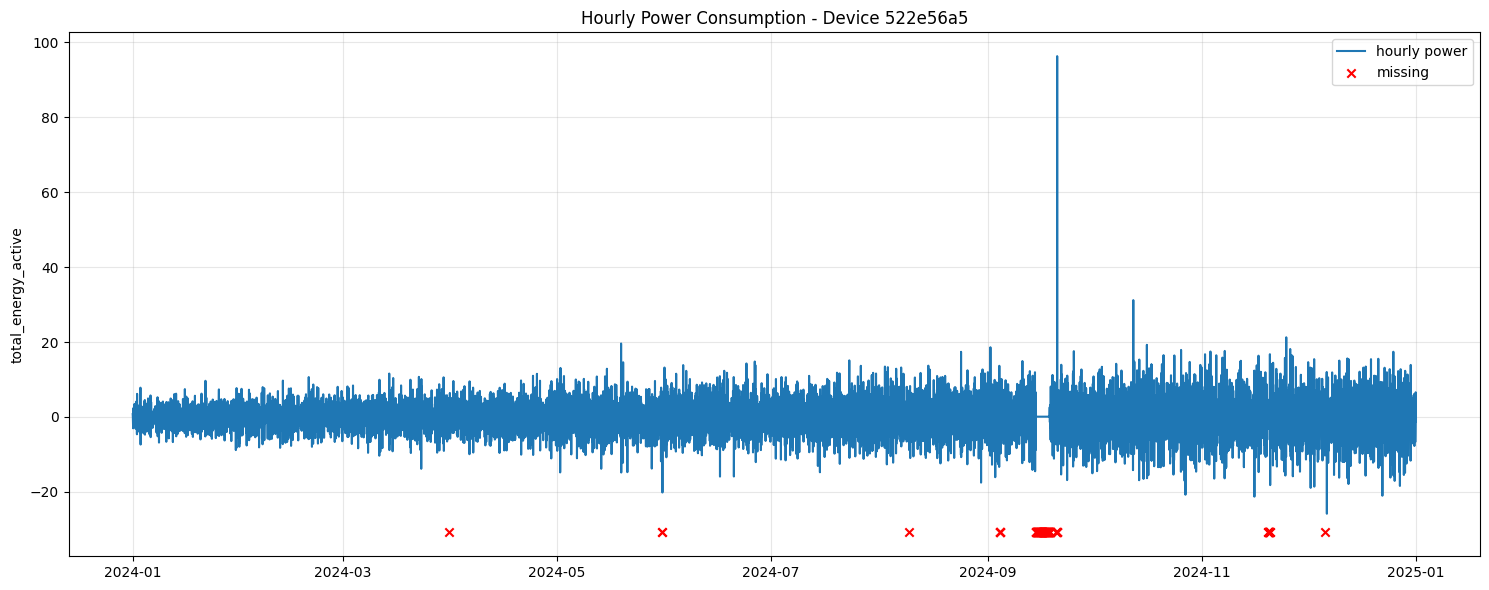

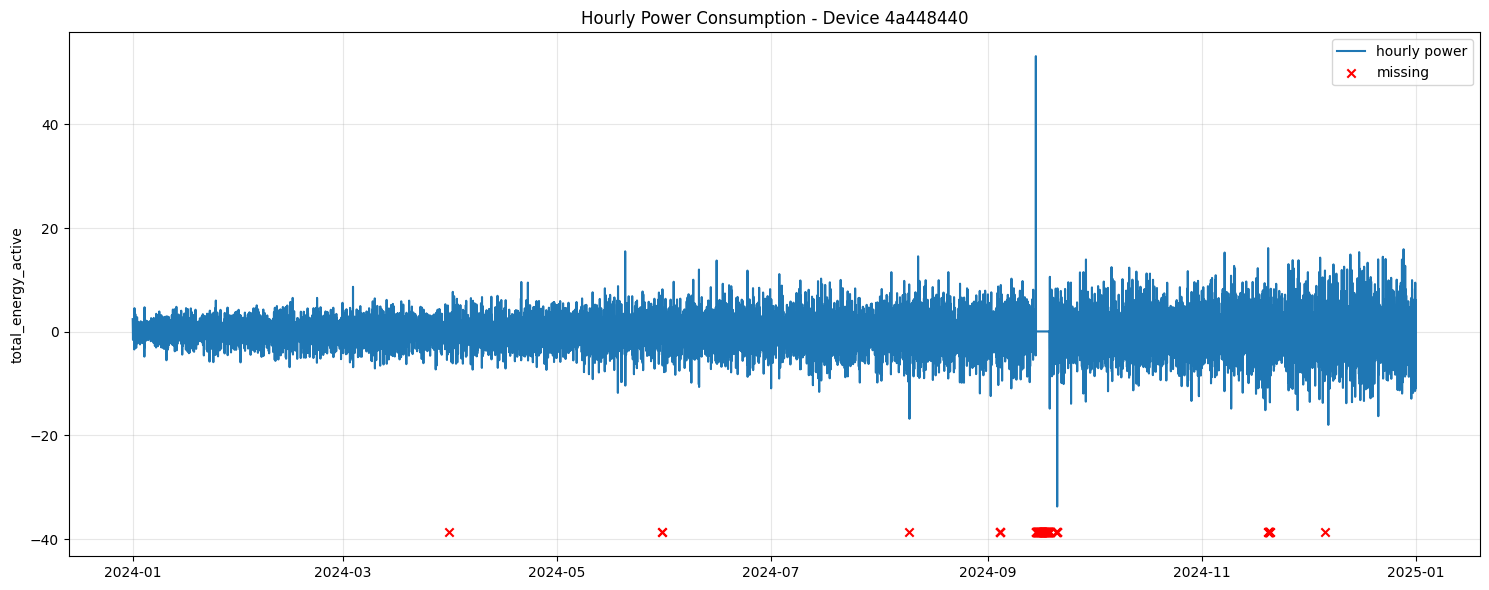

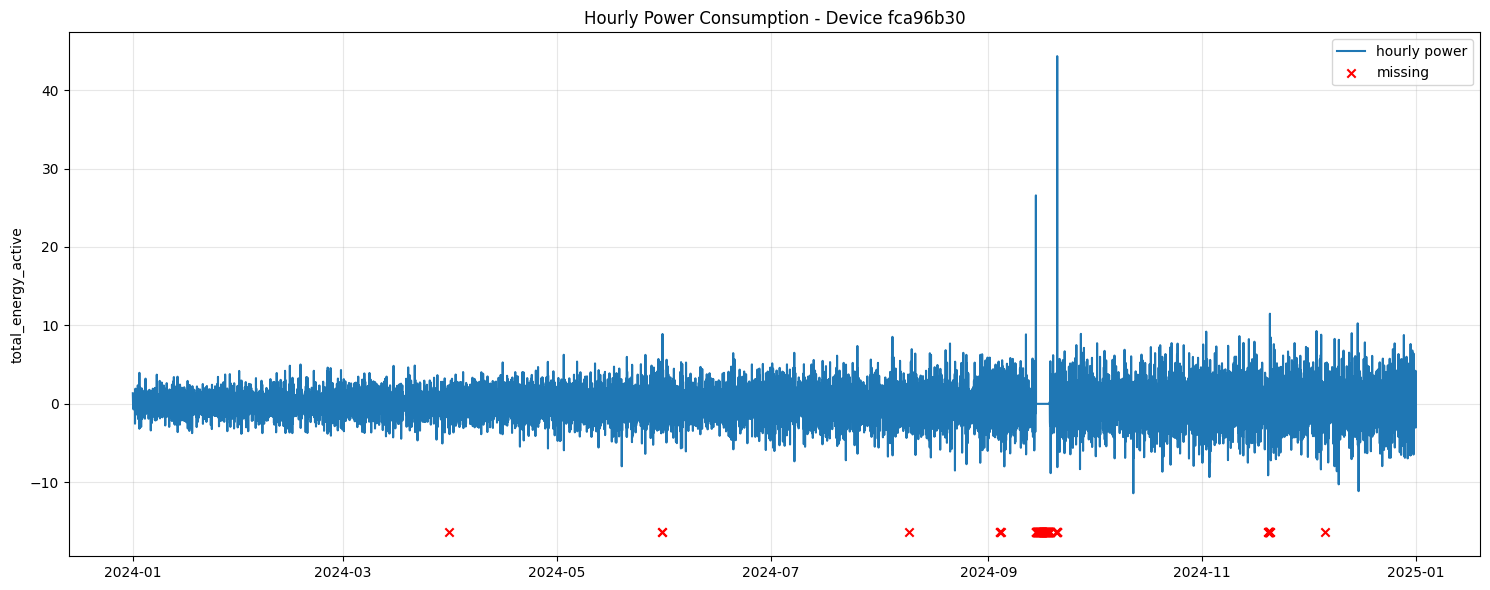

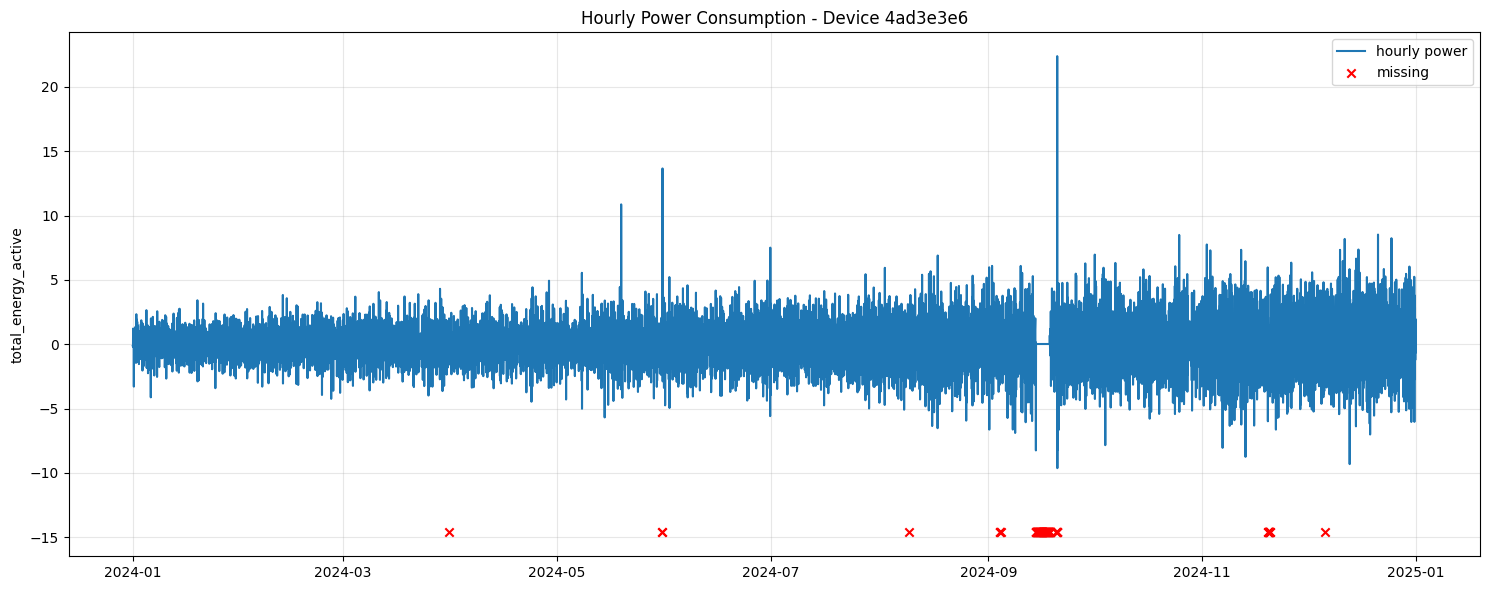

In [37]:
# Plot hourly data for each meter
for device_id, hourly_data in hourly_diff_data_dict.items():
    plt.figure(figsize=(15, 6))
    
    # Choose a sensible default value for missing data (median or a low negative value for visibility)
    fill_value = hourly_data.median() if not pd.isna(hourly_data.median()) else -100
    
    sns.lineplot(hourly_data.fillna(fill_value), label='hourly power')
    
    # Mark missing values
    plt.scatter(
        x=hourly_data[hourly_data.isna()].index,
        y=[hourly_data.min()-5]*hourly_data[hourly_data.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"Hourly Power Consumption - Device {device_id[:8]}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

#### Weekly Patterns

Device: f90e7387-981


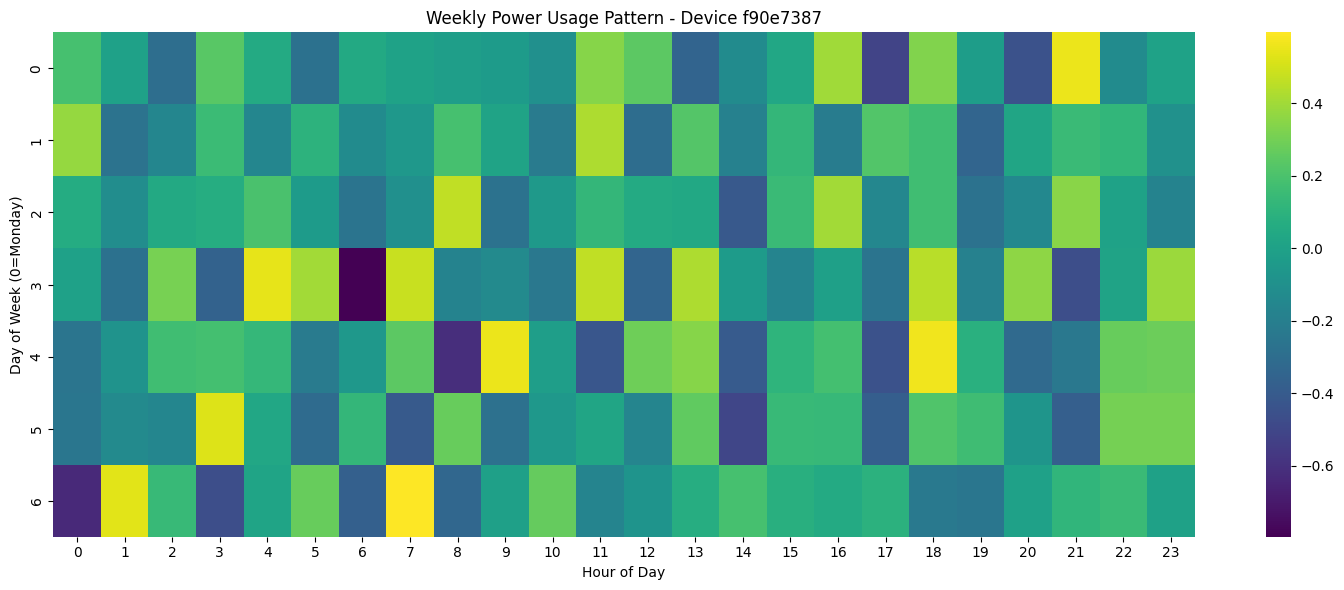

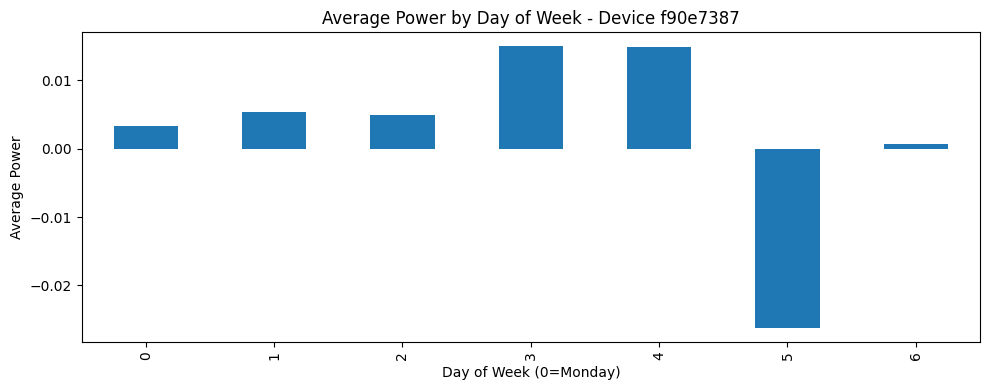

Device: dd40019b-5b3


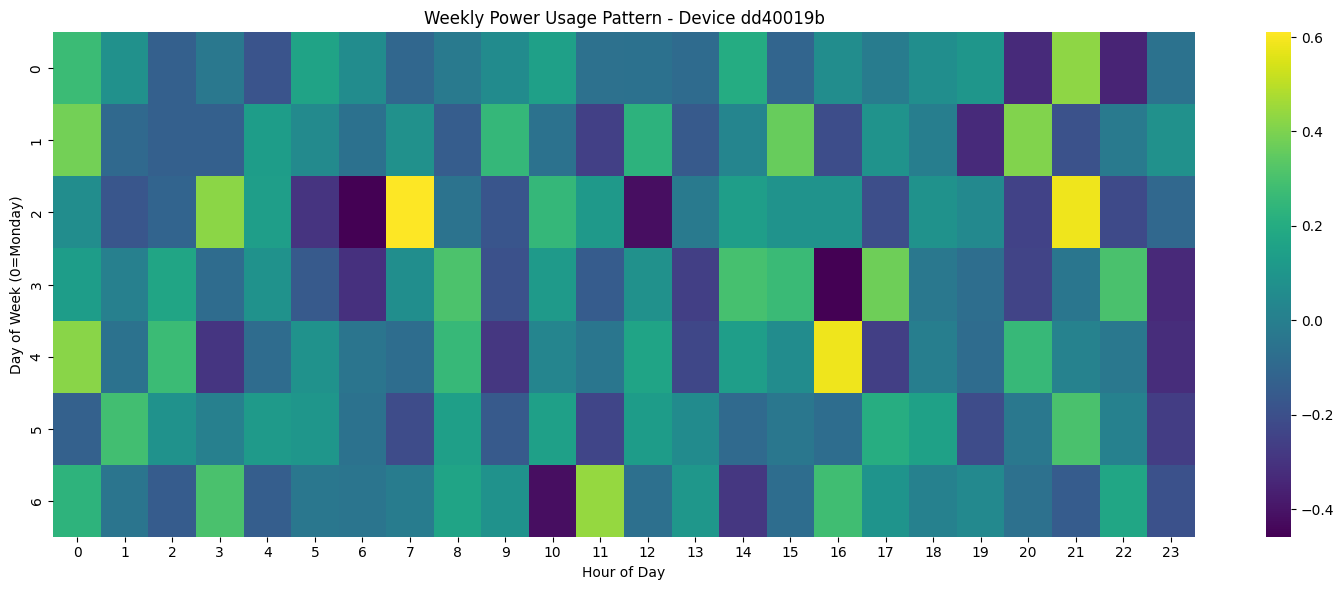

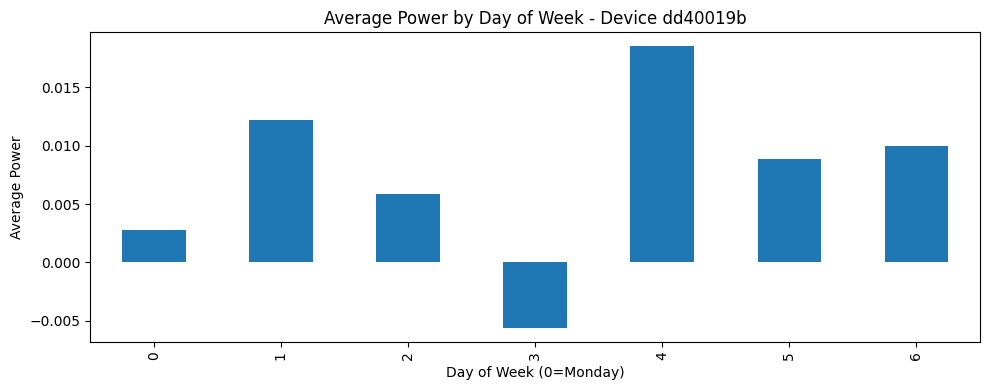

Device: 3617dc75-38d


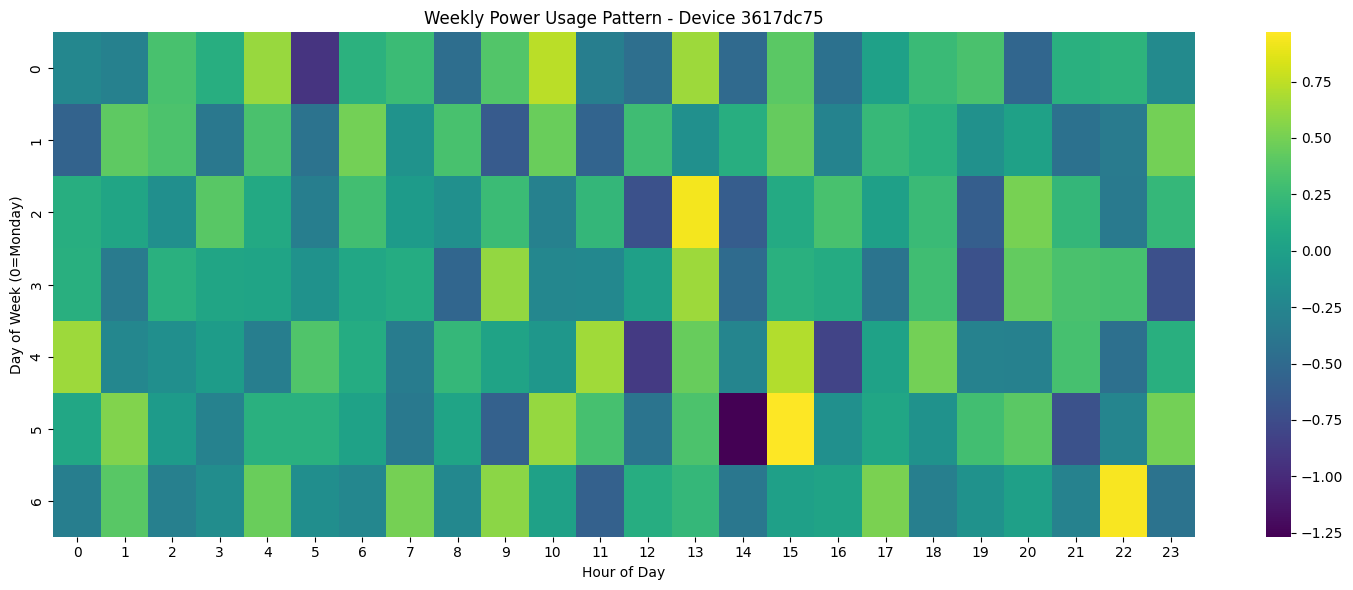

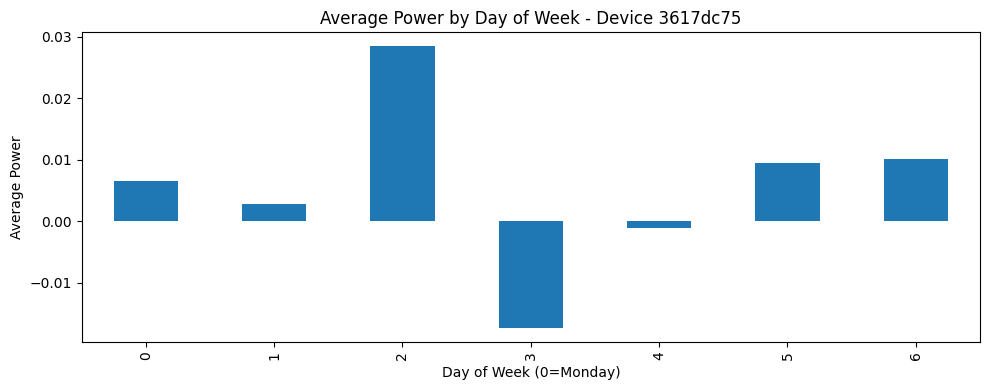

Device: a4b80cd7-543


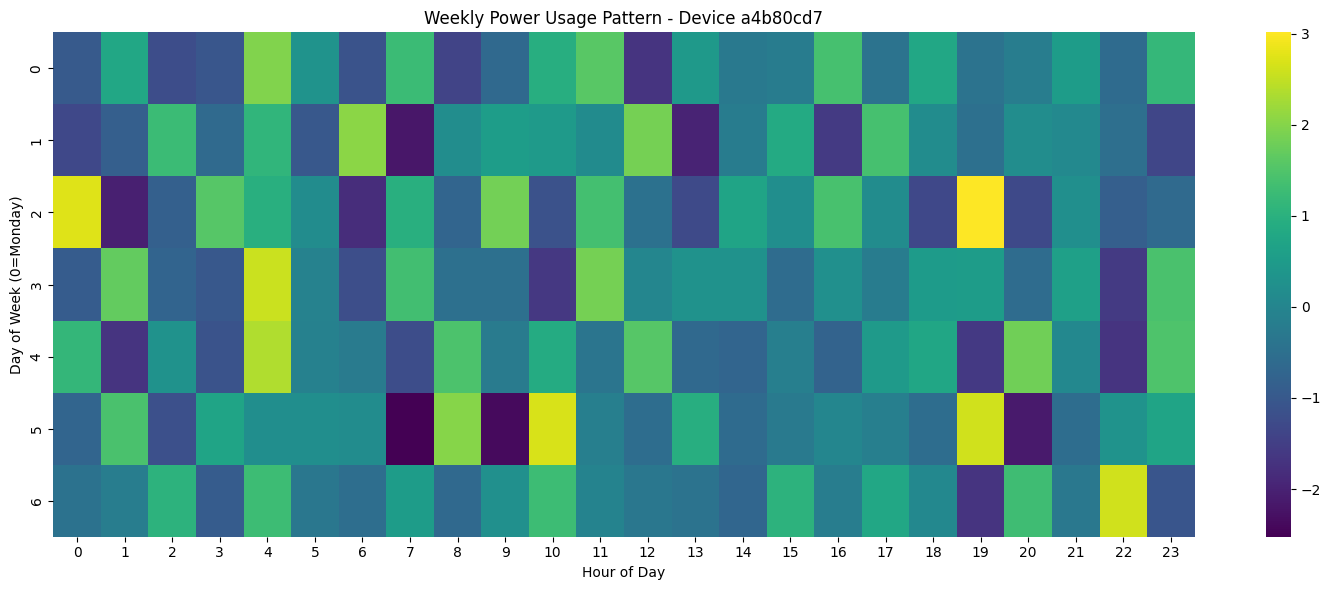

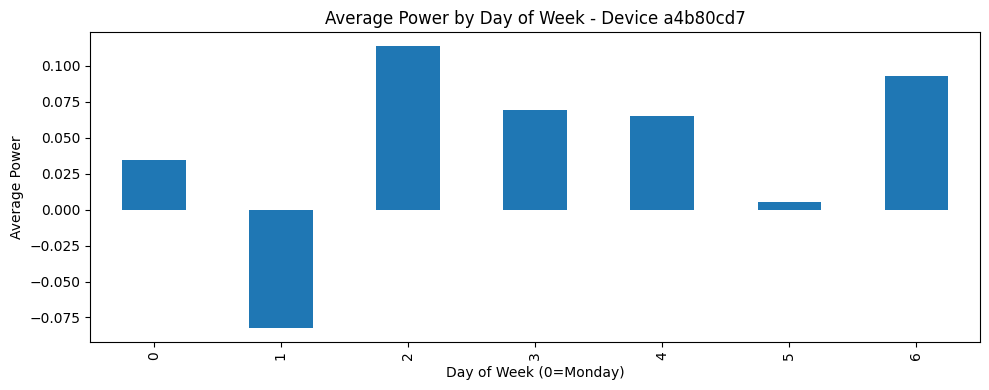

Device: 522e56a5-ff0


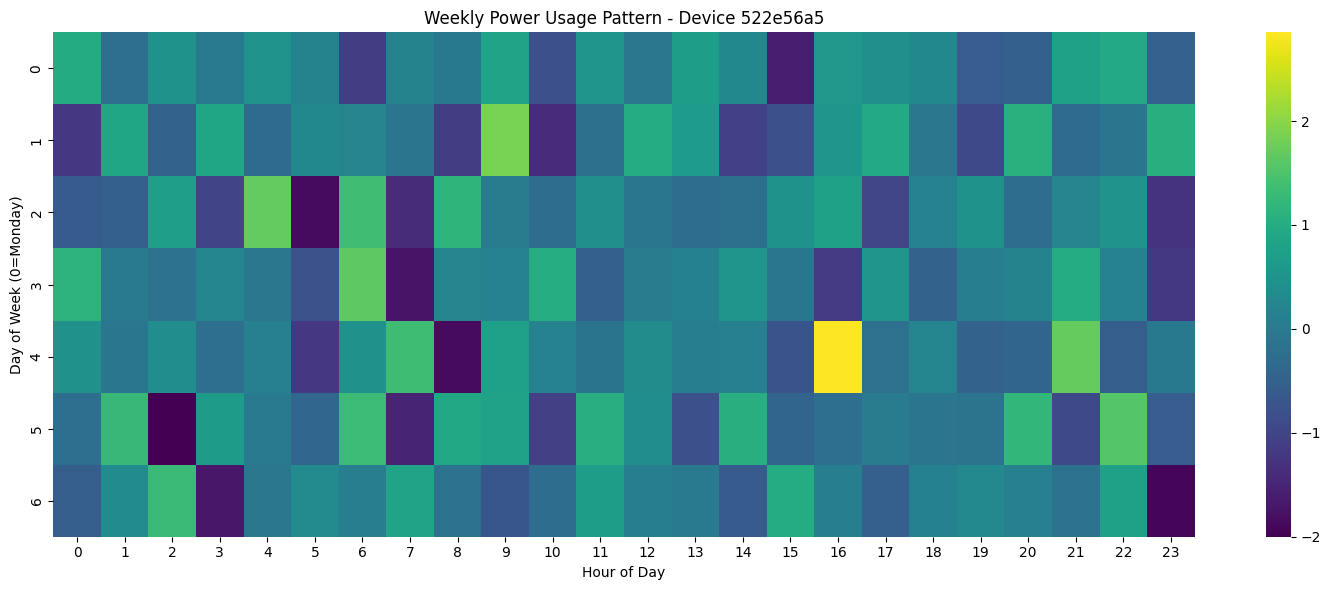

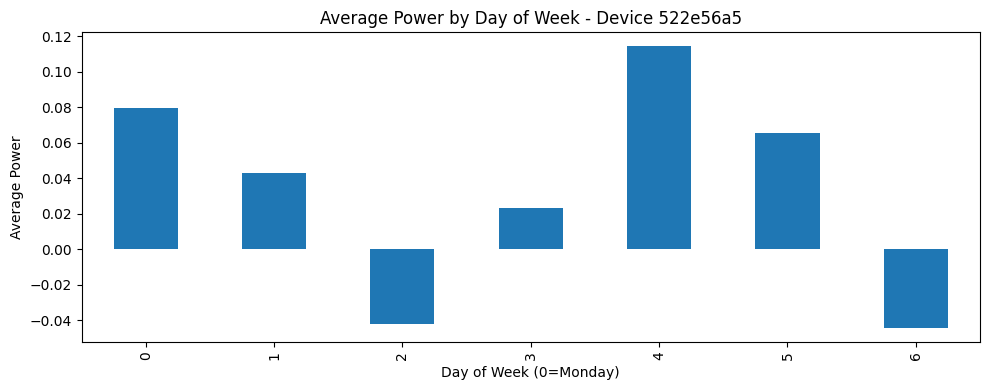

Device: 4a448440-d2d


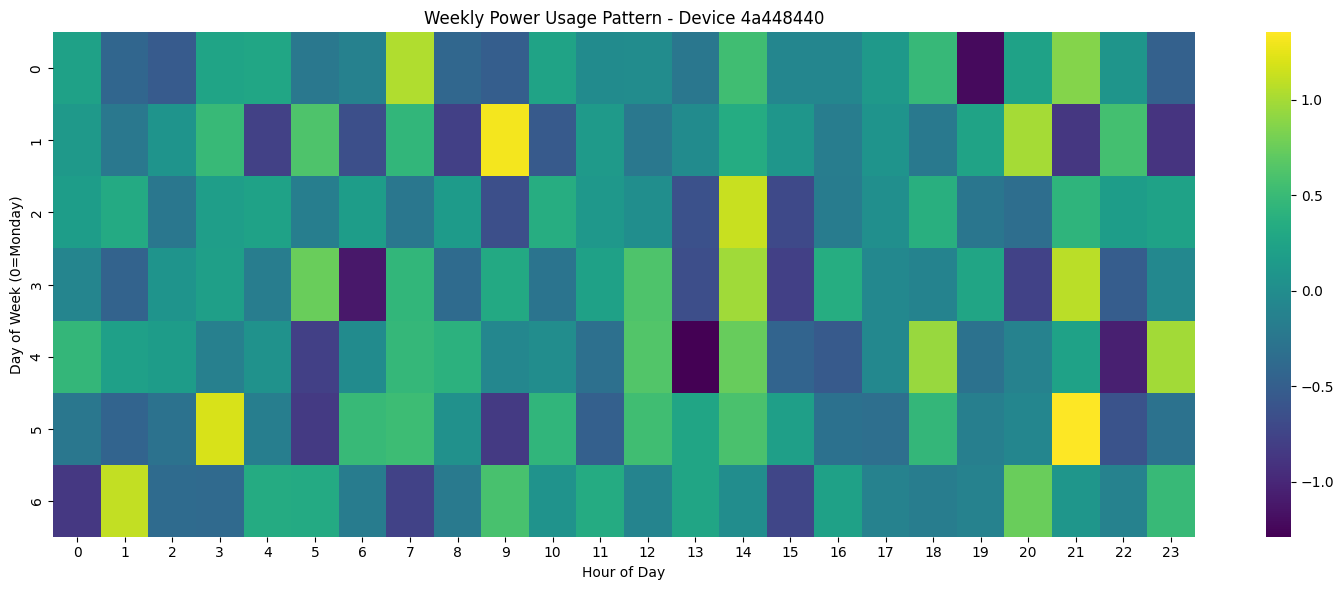

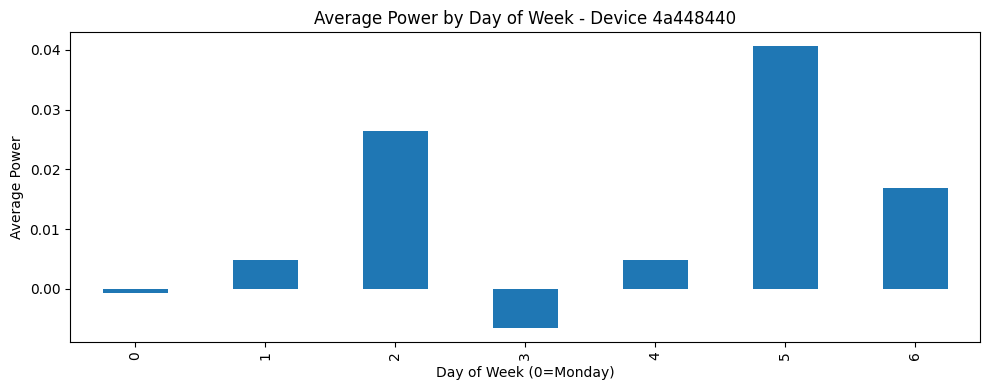

Device: fca96b30-ca2


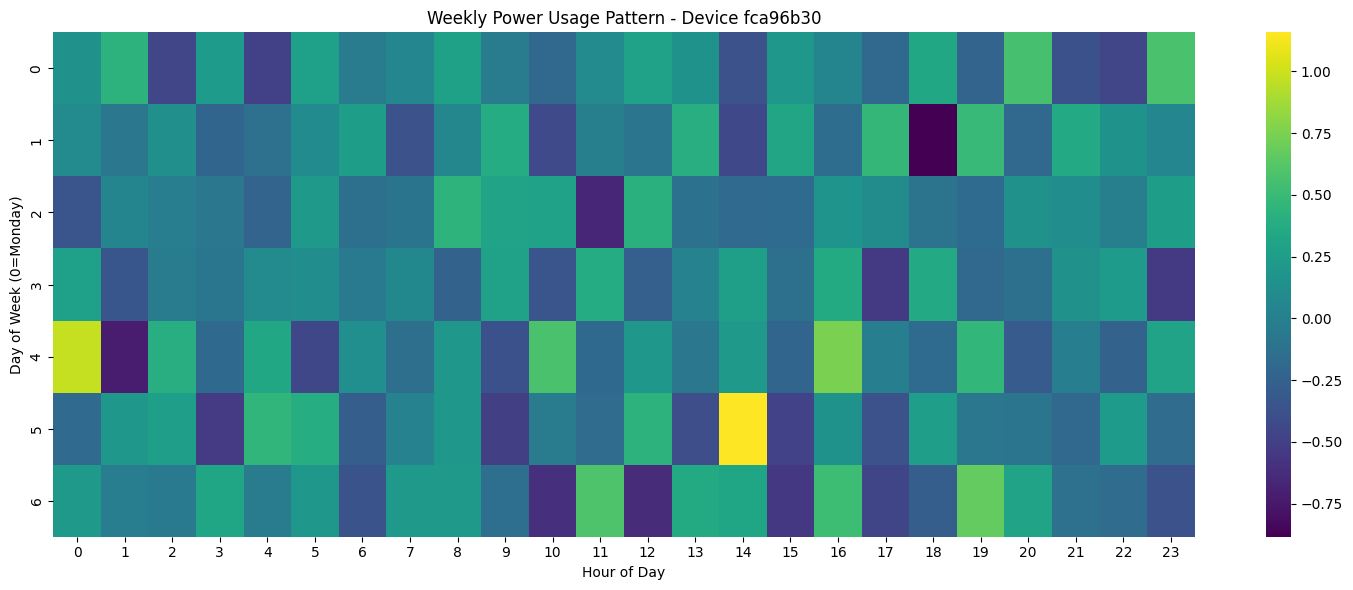

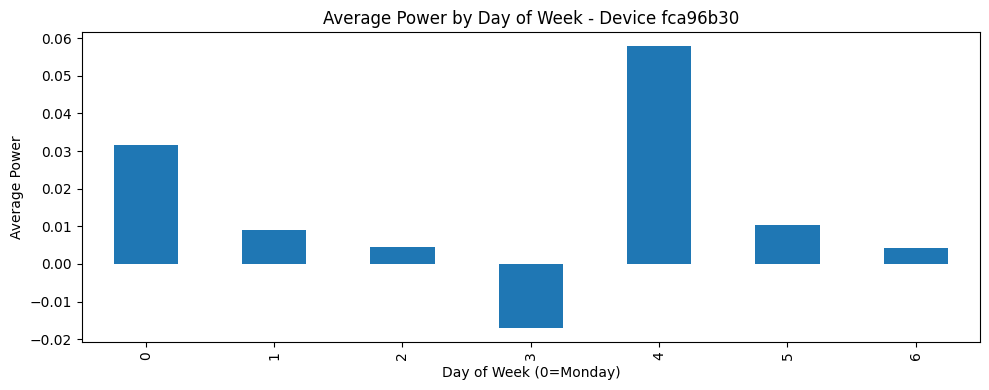

Device: 4ad3e3e6-5f1


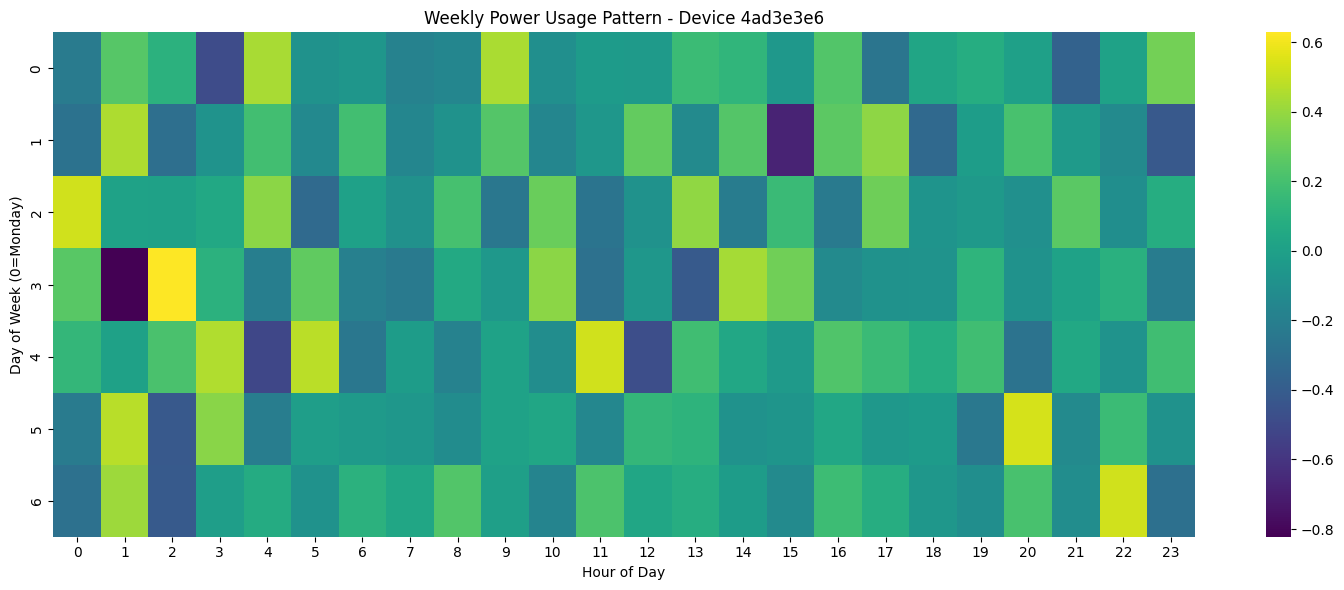

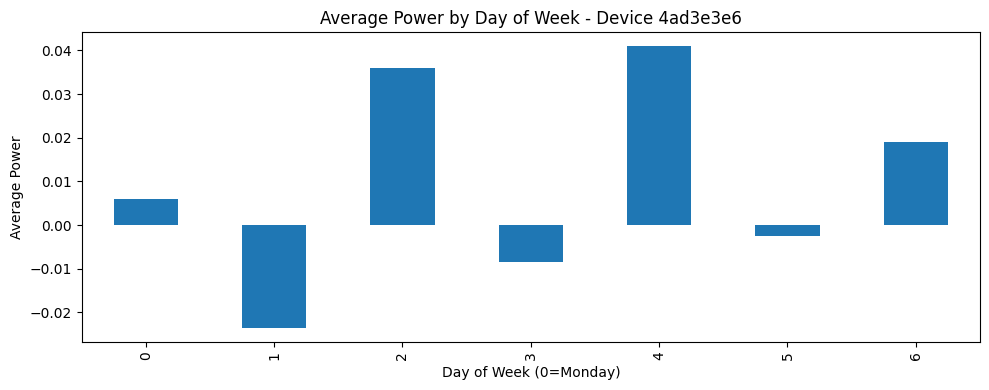

In [38]:
for device_id, hourly_data in hourly_diff_data_dict.items():
    plt.figure(figsize=(15, 6))
    
    # Group by hour of day and day of week
    hourly_pattern = hourly_data.groupby([hourly_data.index.dayofweek, hourly_data.index.hour]).mean()
    hourly_pattern = hourly_pattern.unstack()
    
    
    print("="*100, f"\nDevice: {device_id[:12]}")

    # Create heatmap of weekly patterns
    sns.heatmap(hourly_pattern, cmap='viridis')
    plt.title(f"Weekly Power Usage Pattern - Device {device_id[:8]}")
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week (0=Monday)')
    plt.tight_layout()
    plt.show()
    
    # Also show daily averages
    plt.figure(figsize=(10, 4));
    hourly_data.groupby(hourly_data.index.dayofweek).mean().plot(kind='bar')
    plt.title(f"Average Power by Day of Week - Device {device_id[:8]}")
    plt.xlabel('Day of Week (0=Monday)')
    plt.ylabel('Average Power')
    plt.tight_layout()
    plt.show()

#### Autocorrelation Analysis

Device: f90e7387-981


<Figure size 1500x600 with 0 Axes>

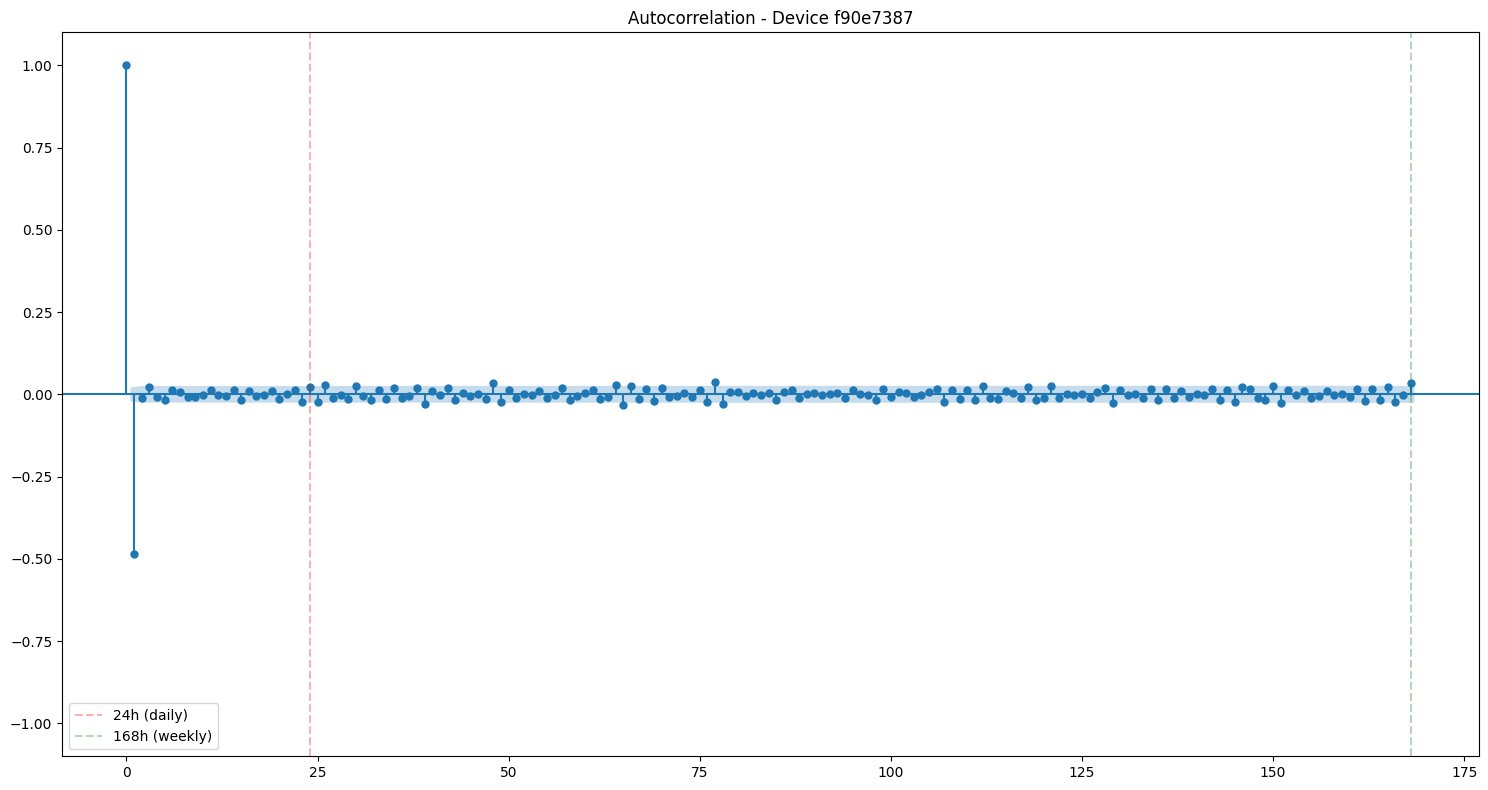

<Figure size 1500x600 with 0 Axes>

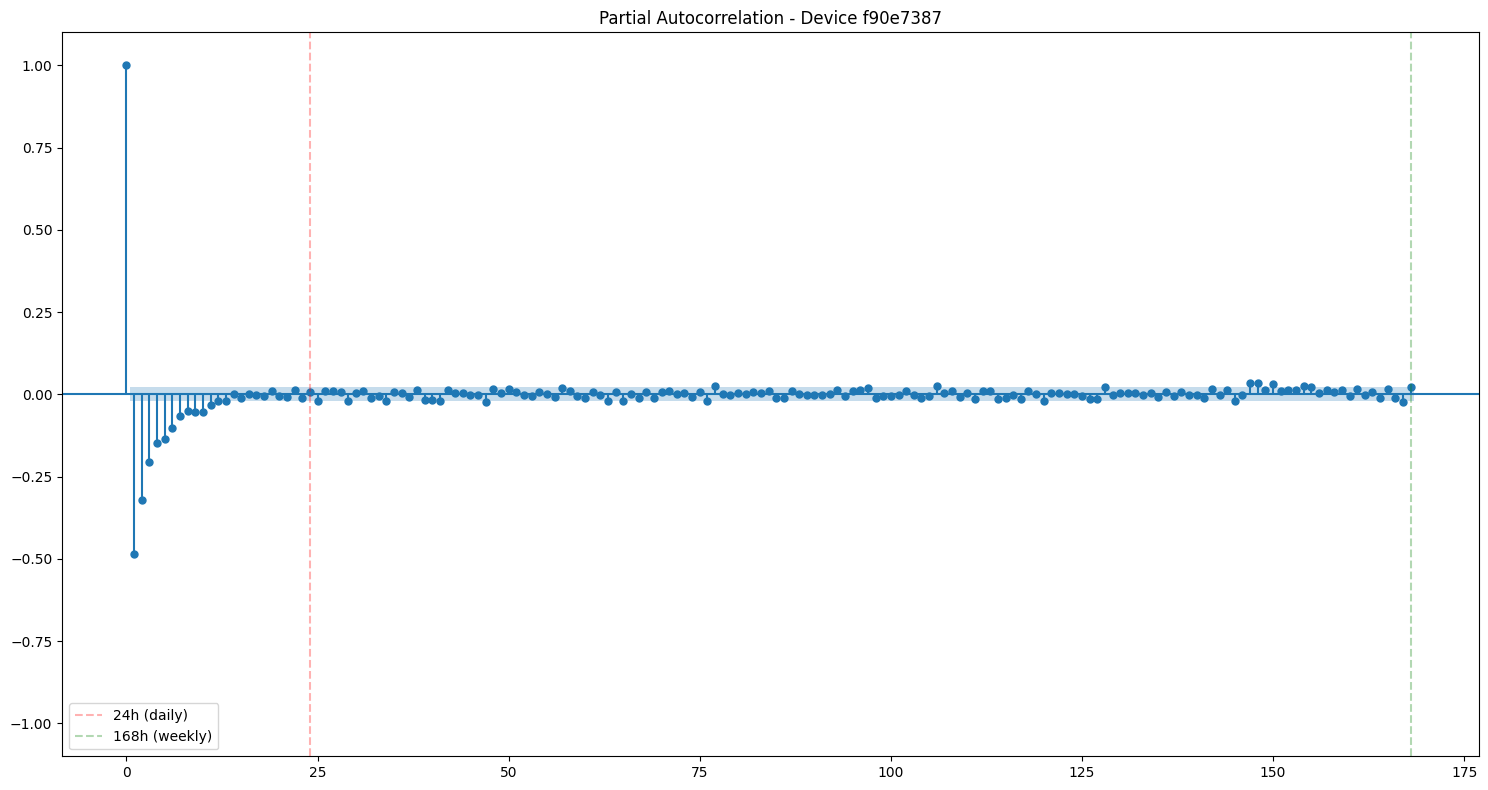

Device: dd40019b-5b3


<Figure size 1500x600 with 0 Axes>

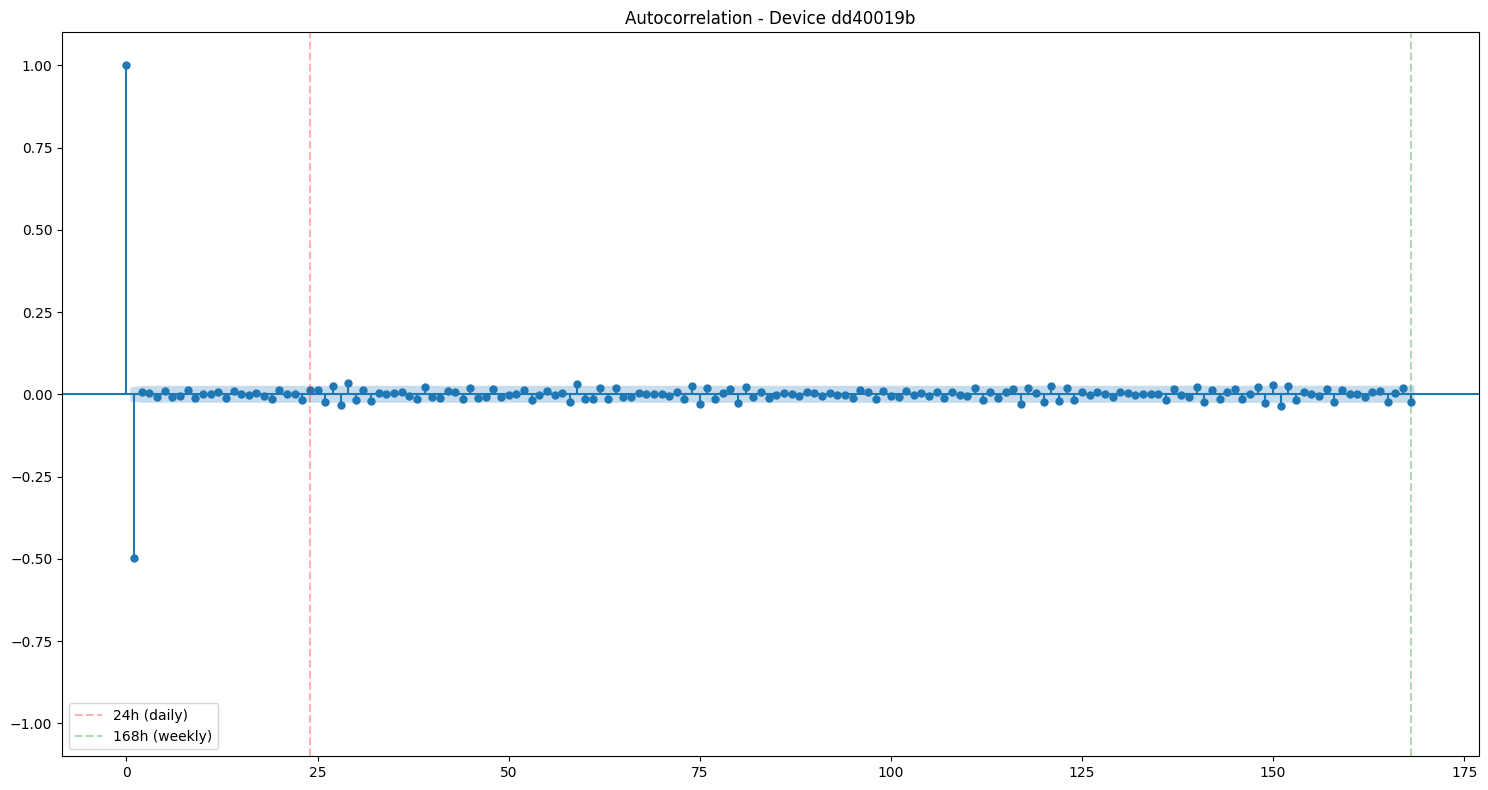

<Figure size 1500x600 with 0 Axes>

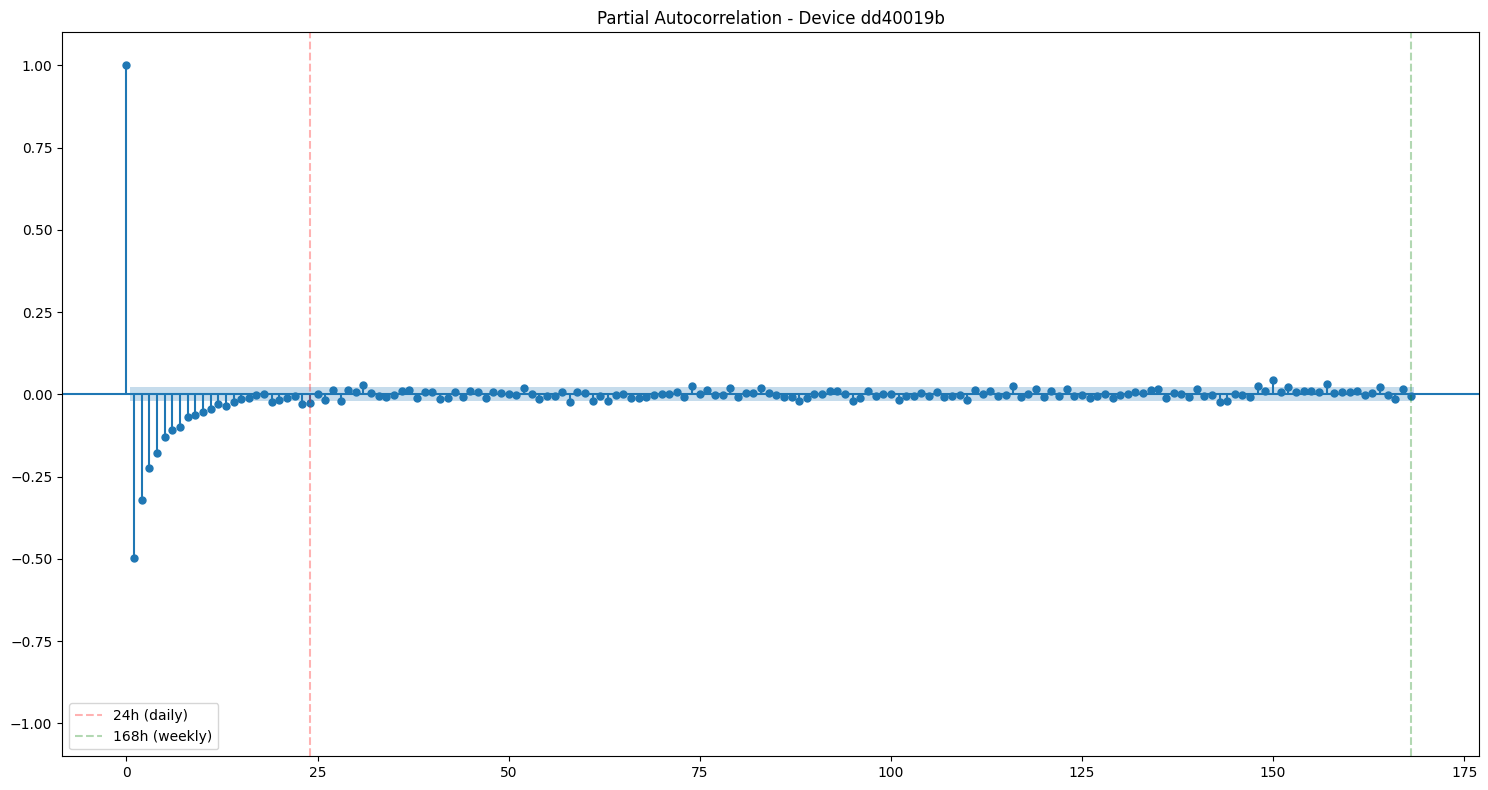

Device: 3617dc75-38d


<Figure size 1500x600 with 0 Axes>

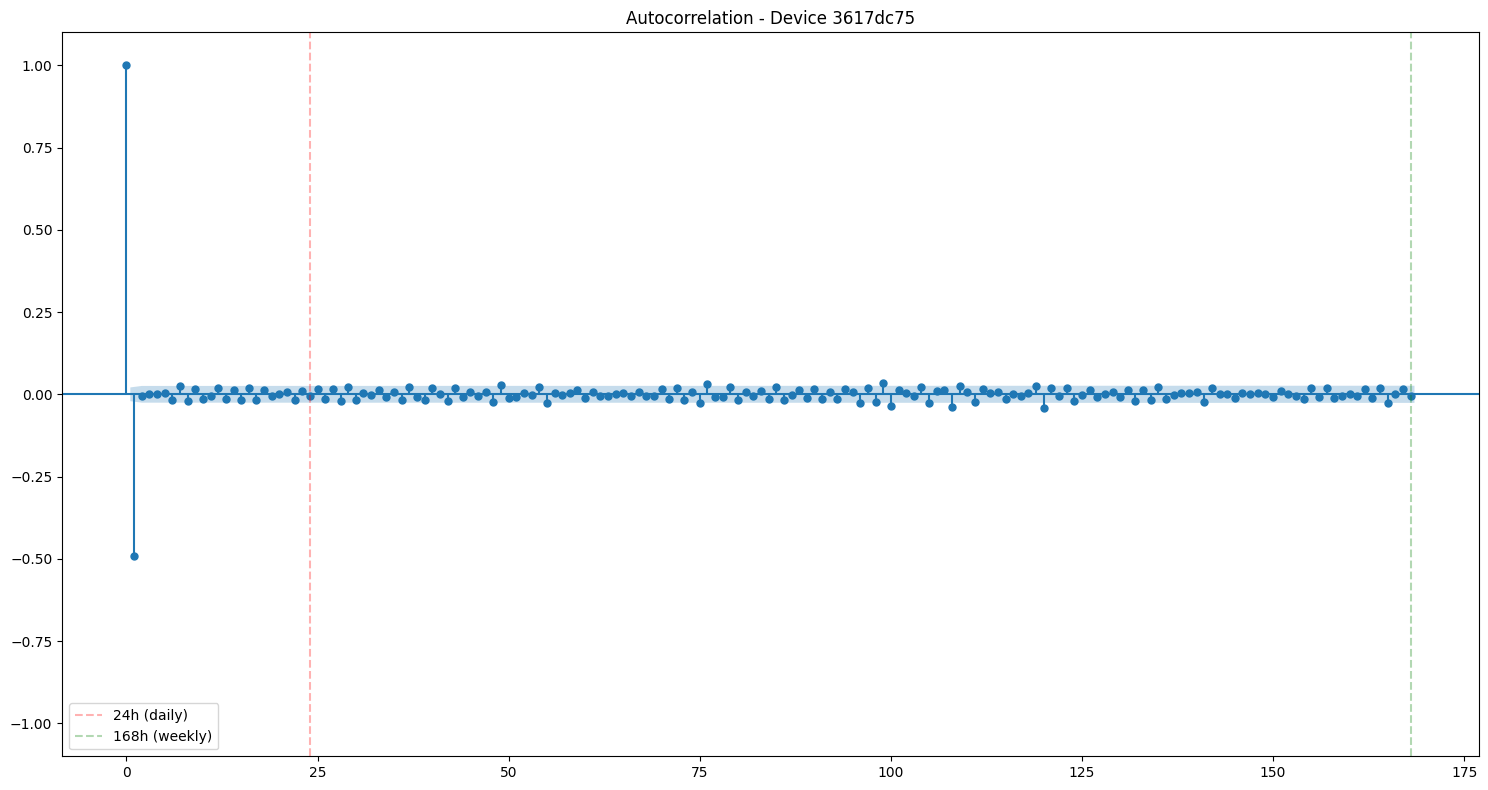

<Figure size 1500x600 with 0 Axes>

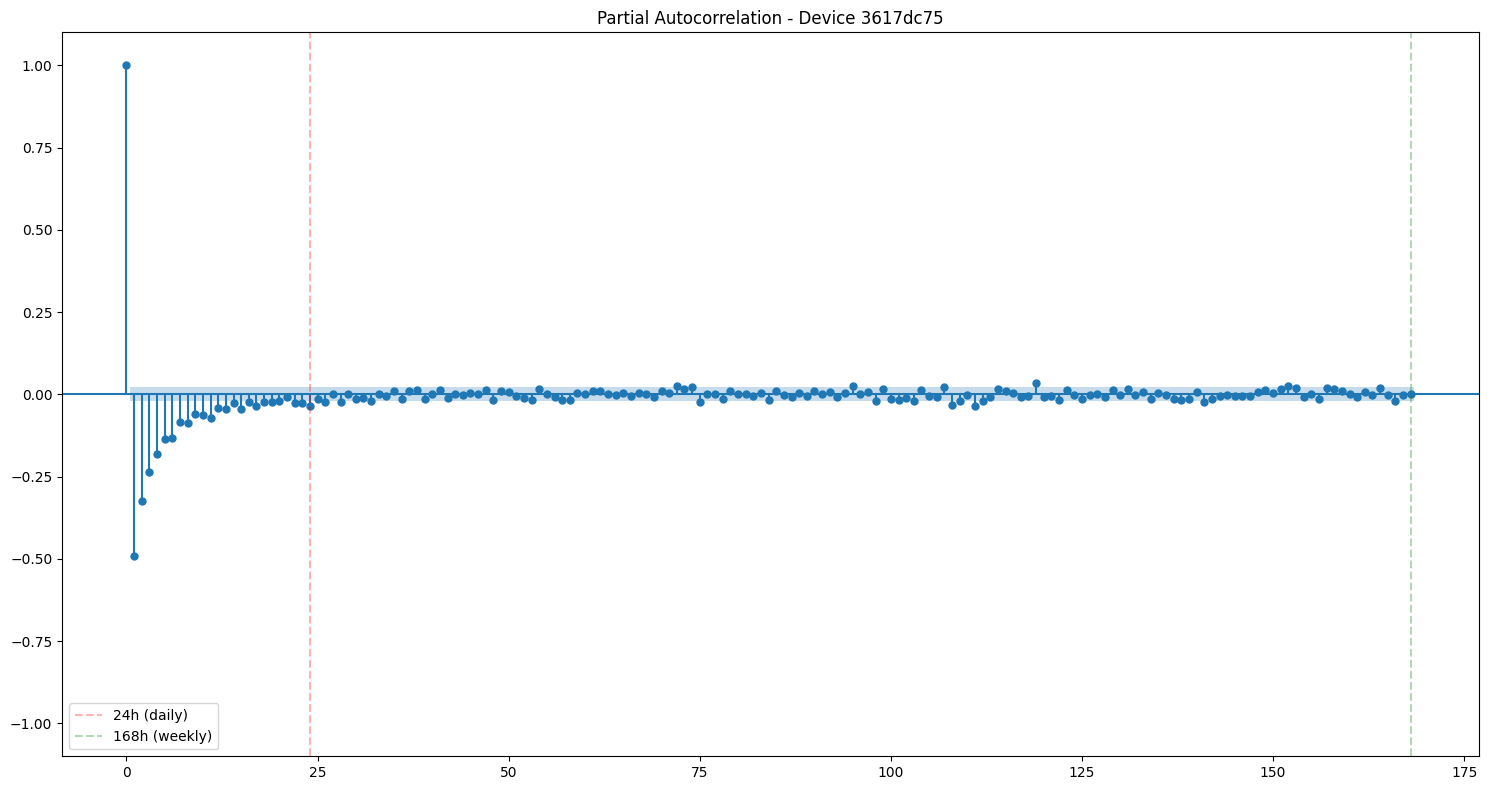

Device: a4b80cd7-543


<Figure size 1500x600 with 0 Axes>

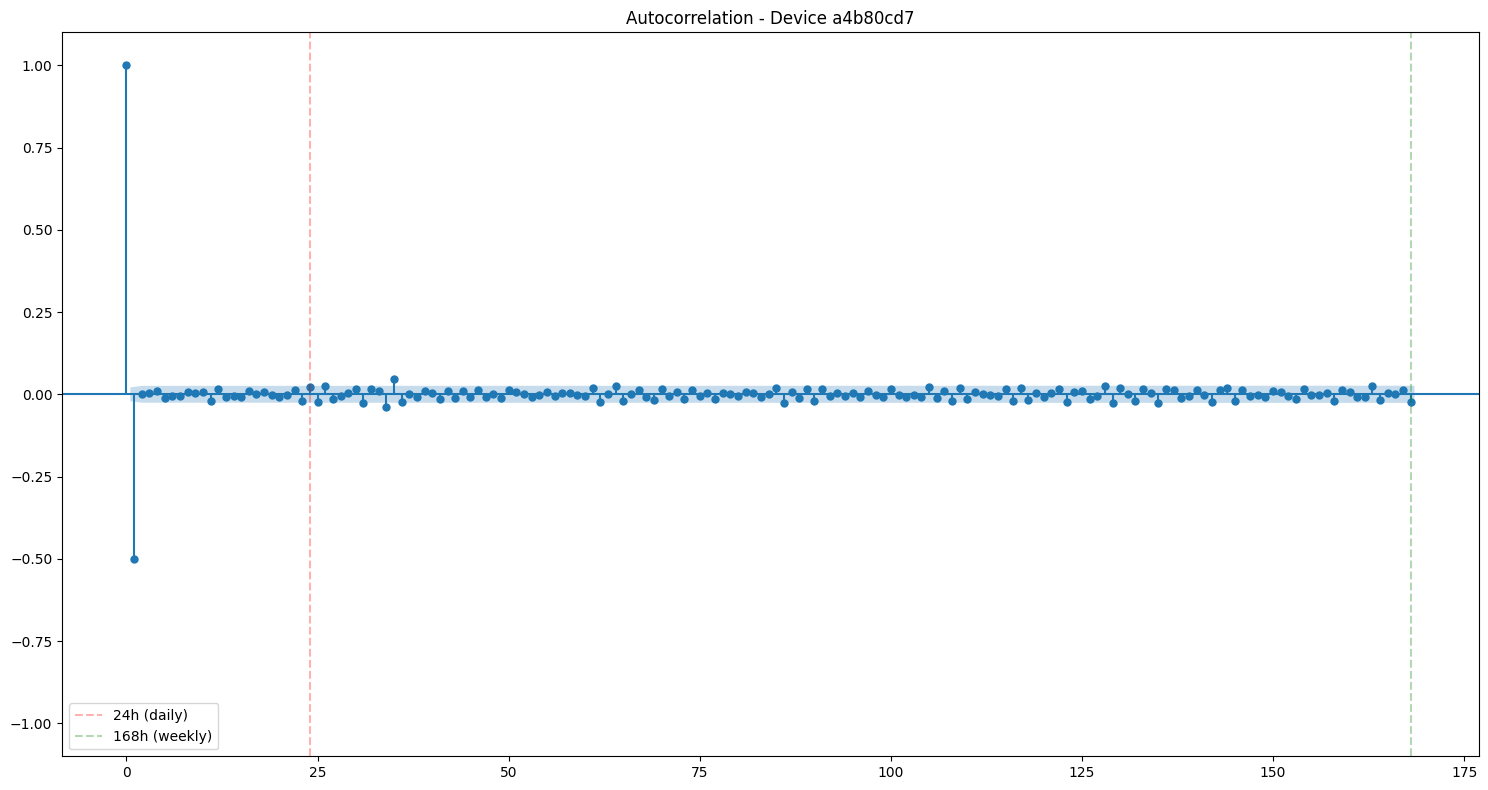

<Figure size 1500x600 with 0 Axes>

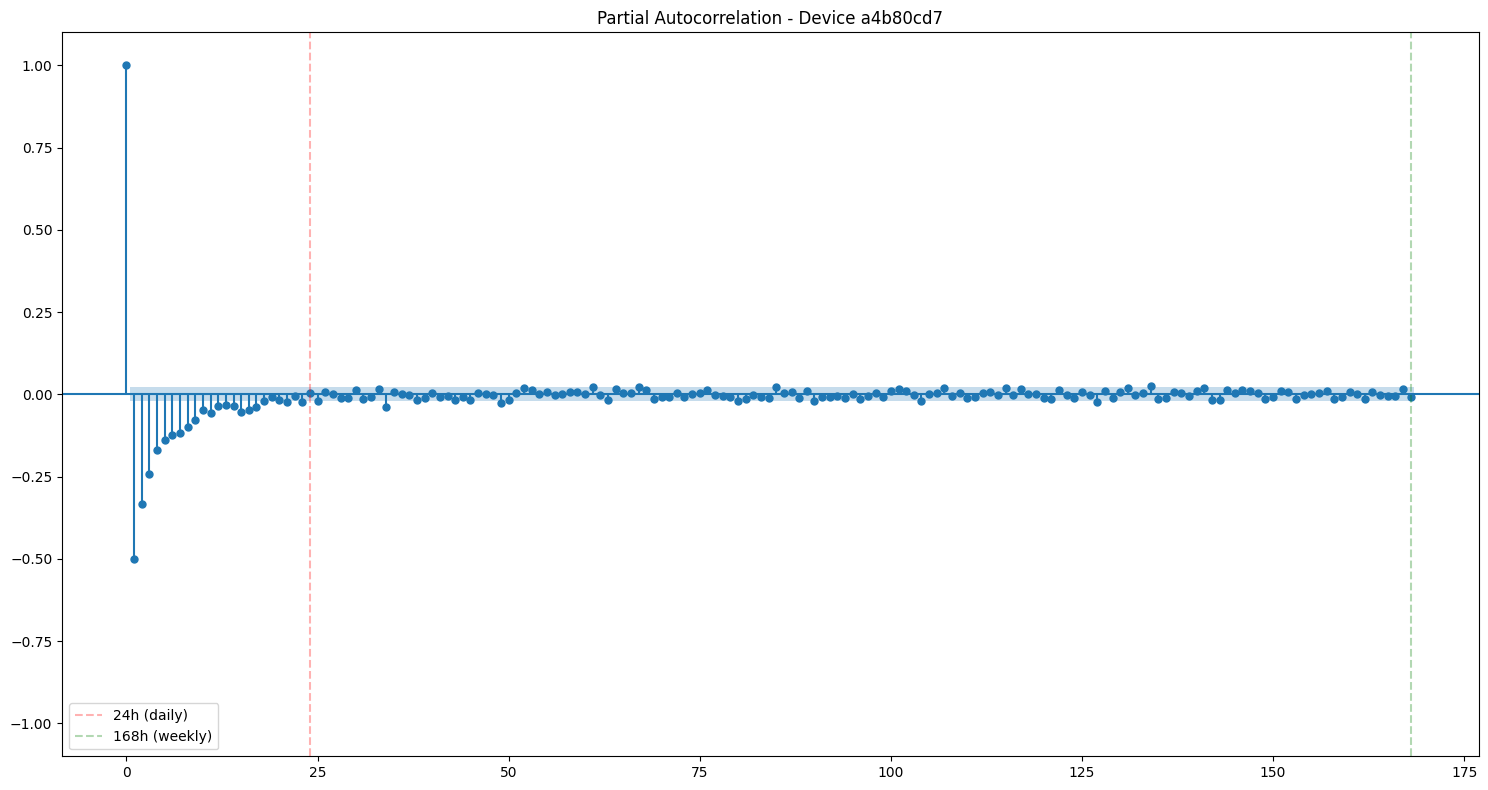

Device: 522e56a5-ff0


<Figure size 1500x600 with 0 Axes>

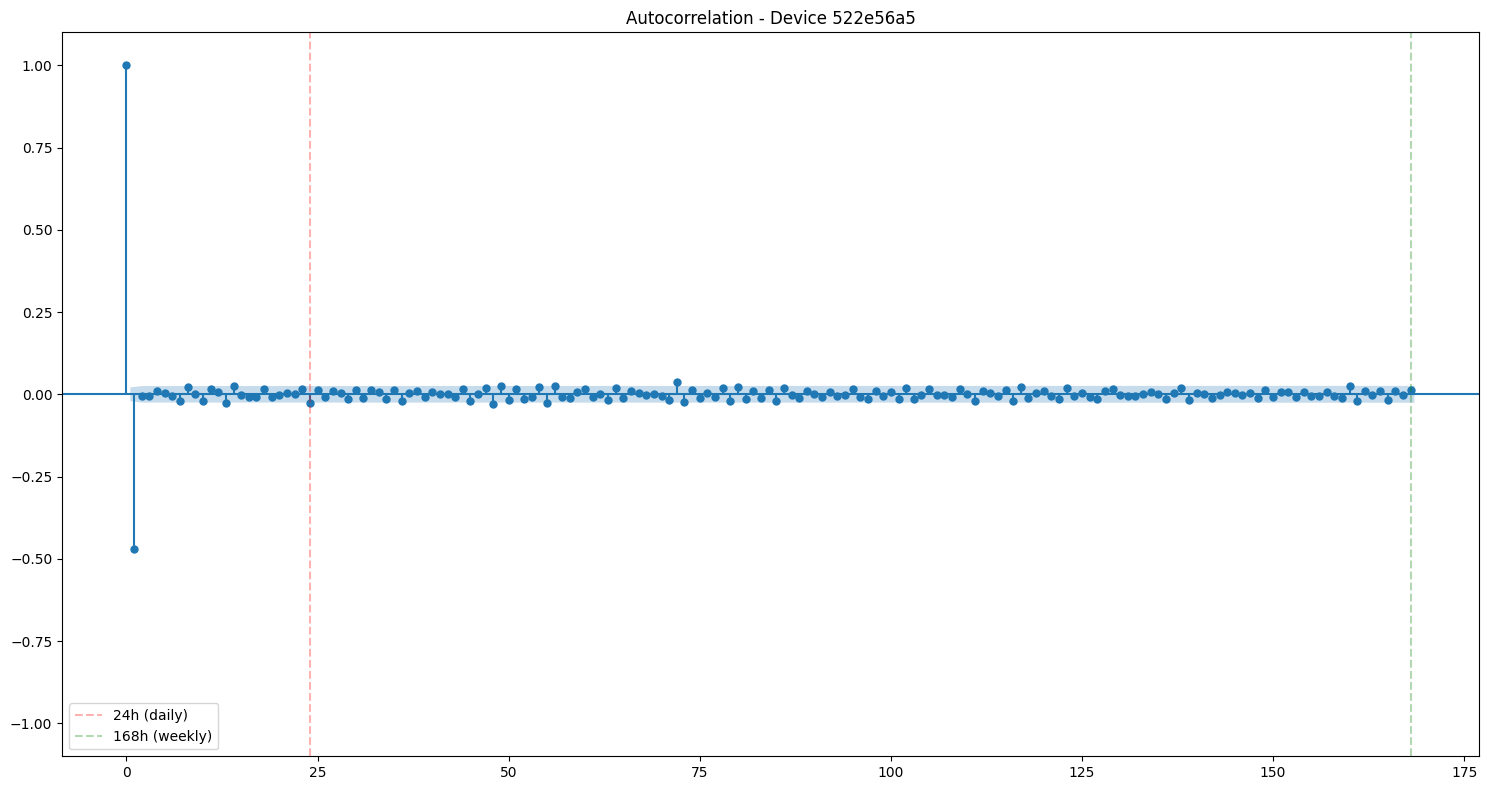

<Figure size 1500x600 with 0 Axes>

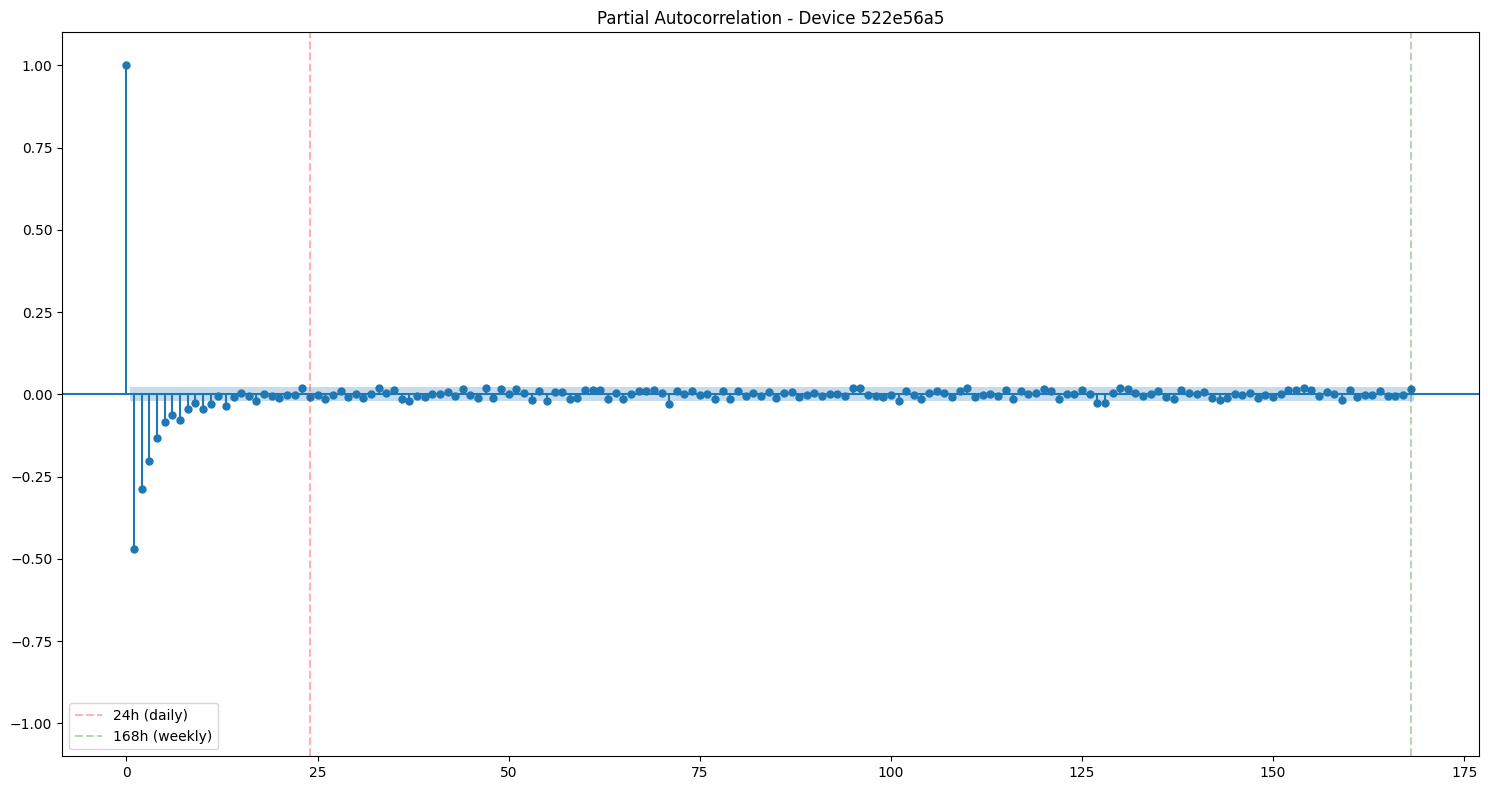

Device: 4a448440-d2d


<Figure size 1500x600 with 0 Axes>

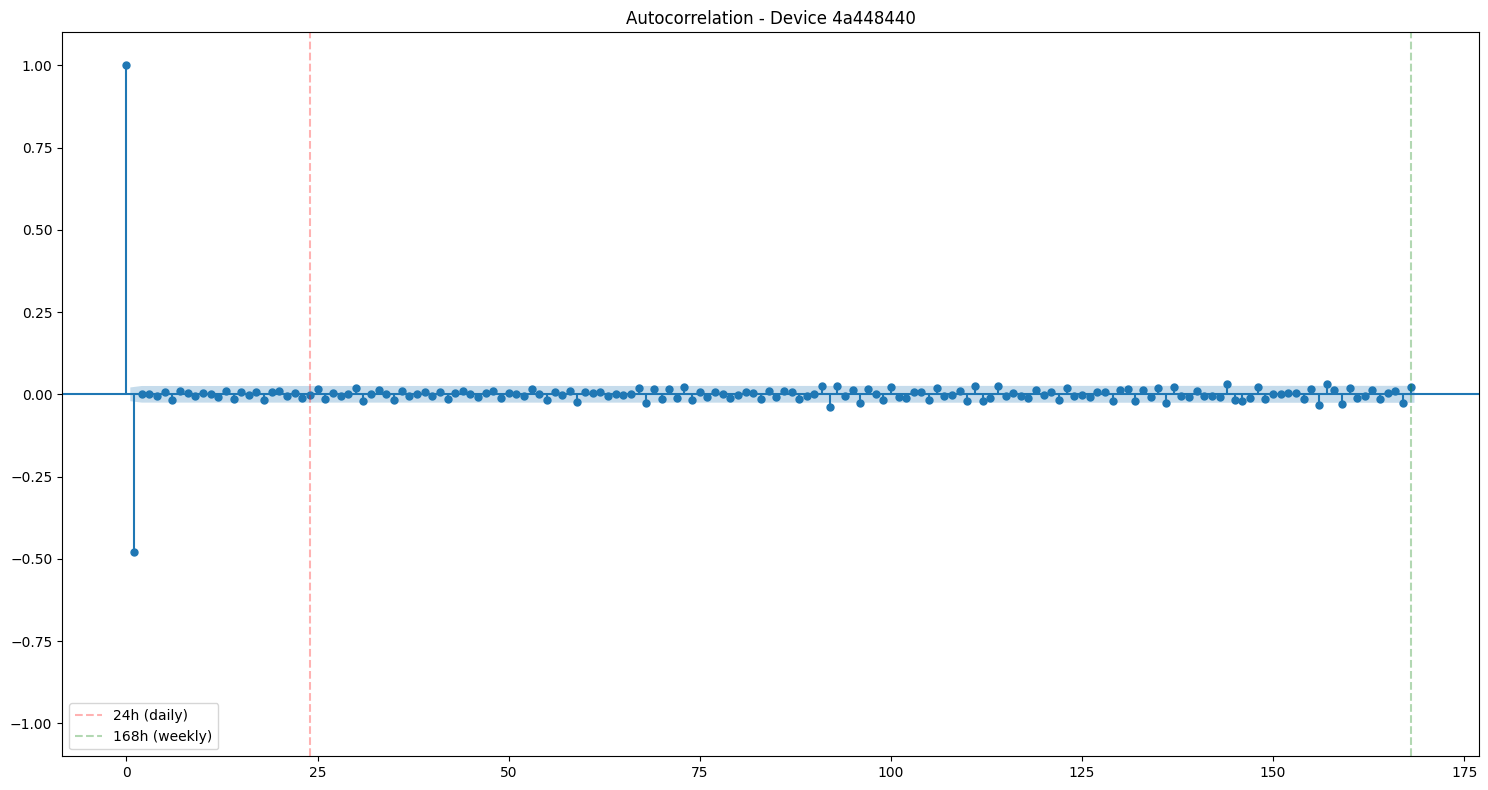

<Figure size 1500x600 with 0 Axes>

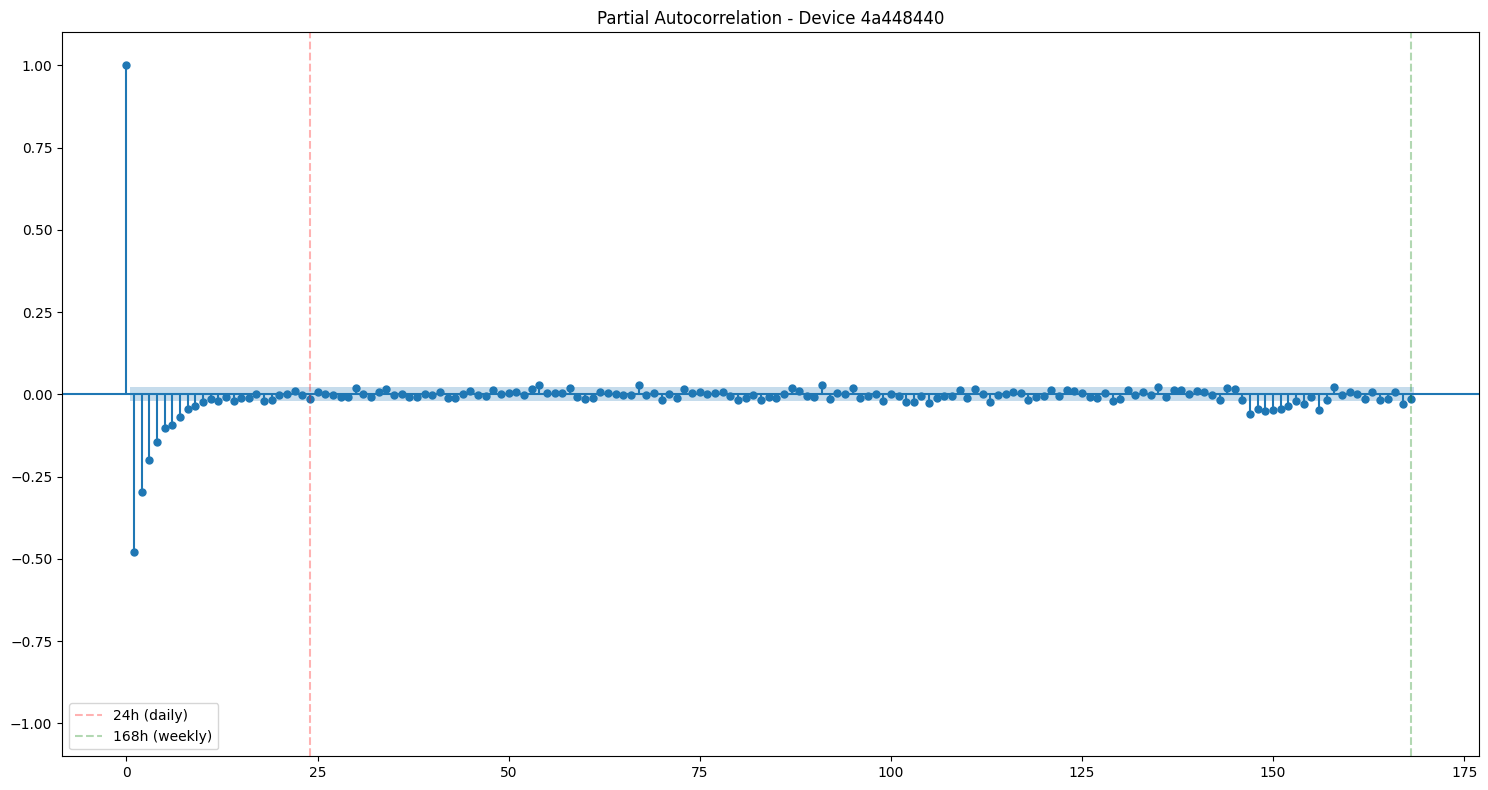

Device: fca96b30-ca2


<Figure size 1500x600 with 0 Axes>

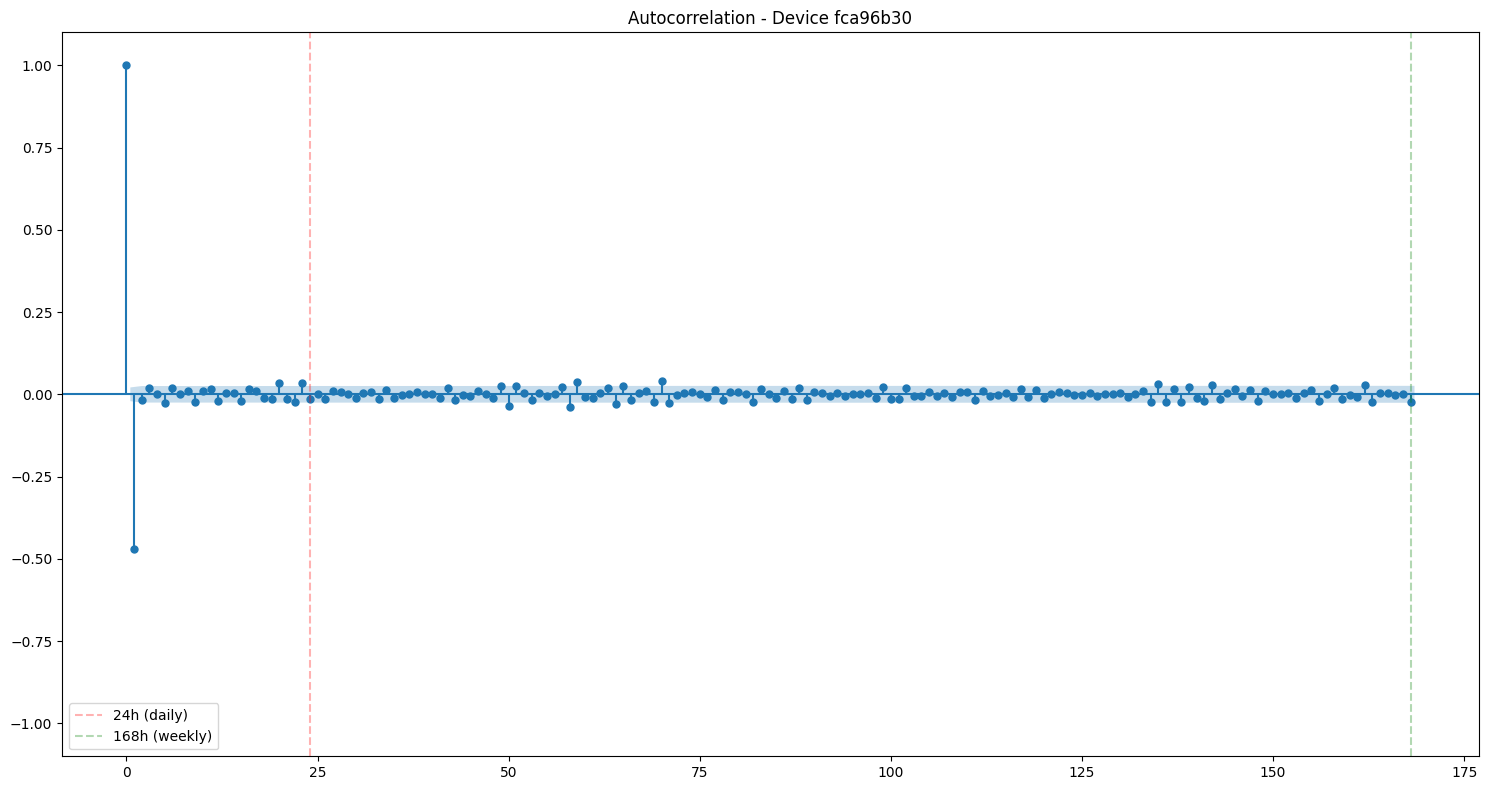

<Figure size 1500x600 with 0 Axes>

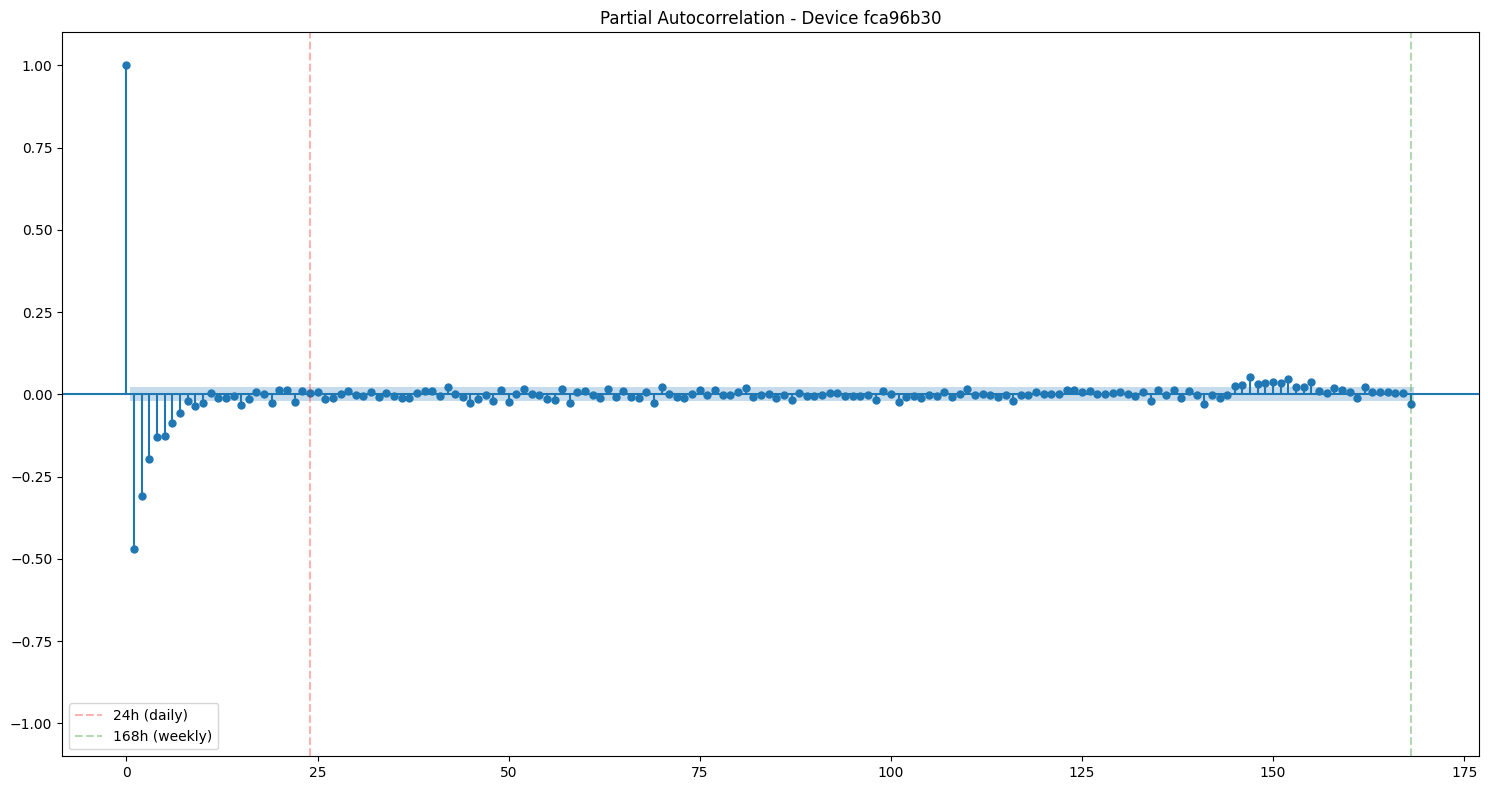

Device: 4ad3e3e6-5f1


<Figure size 1500x600 with 0 Axes>

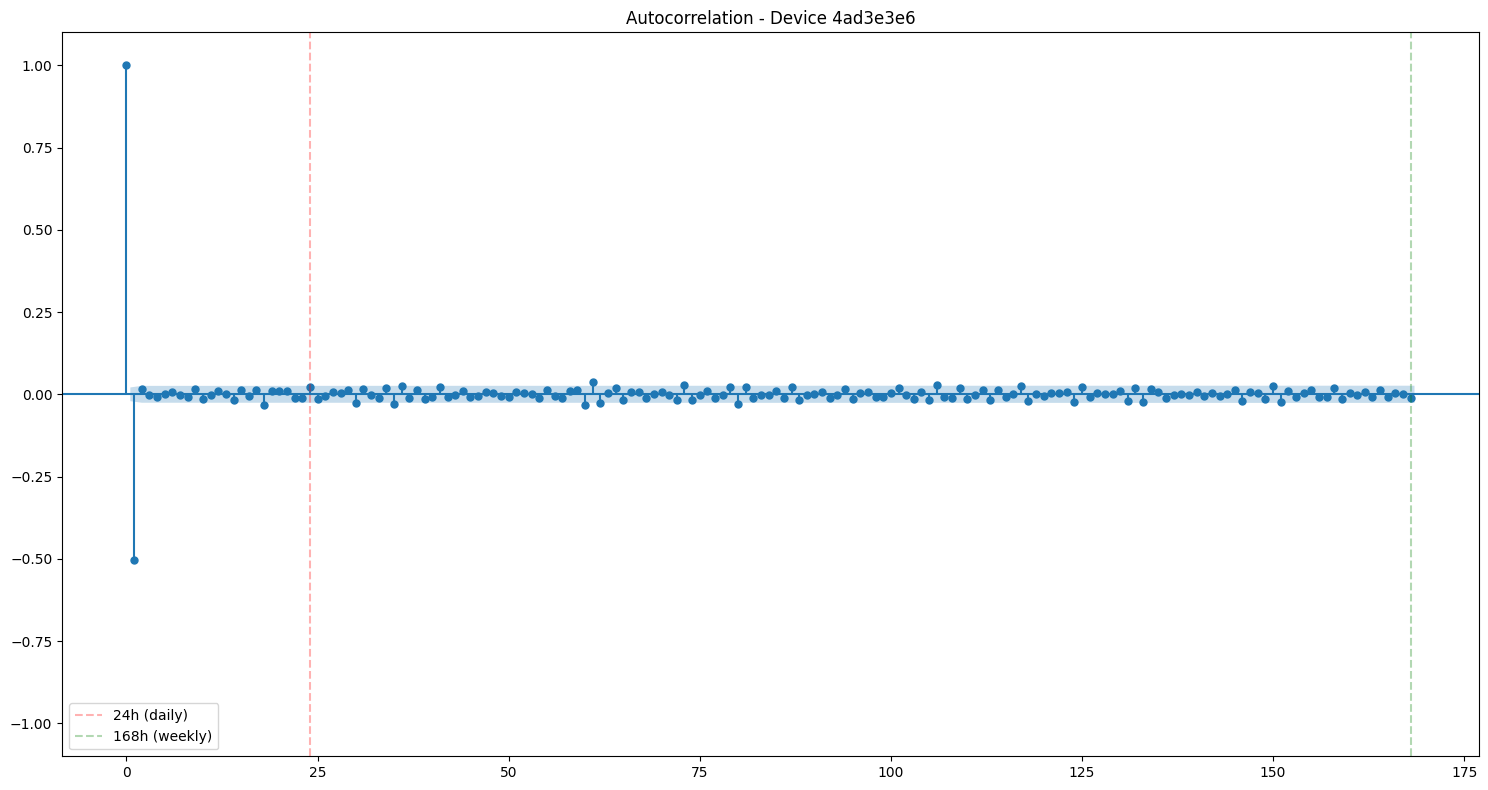

<Figure size 1500x600 with 0 Axes>

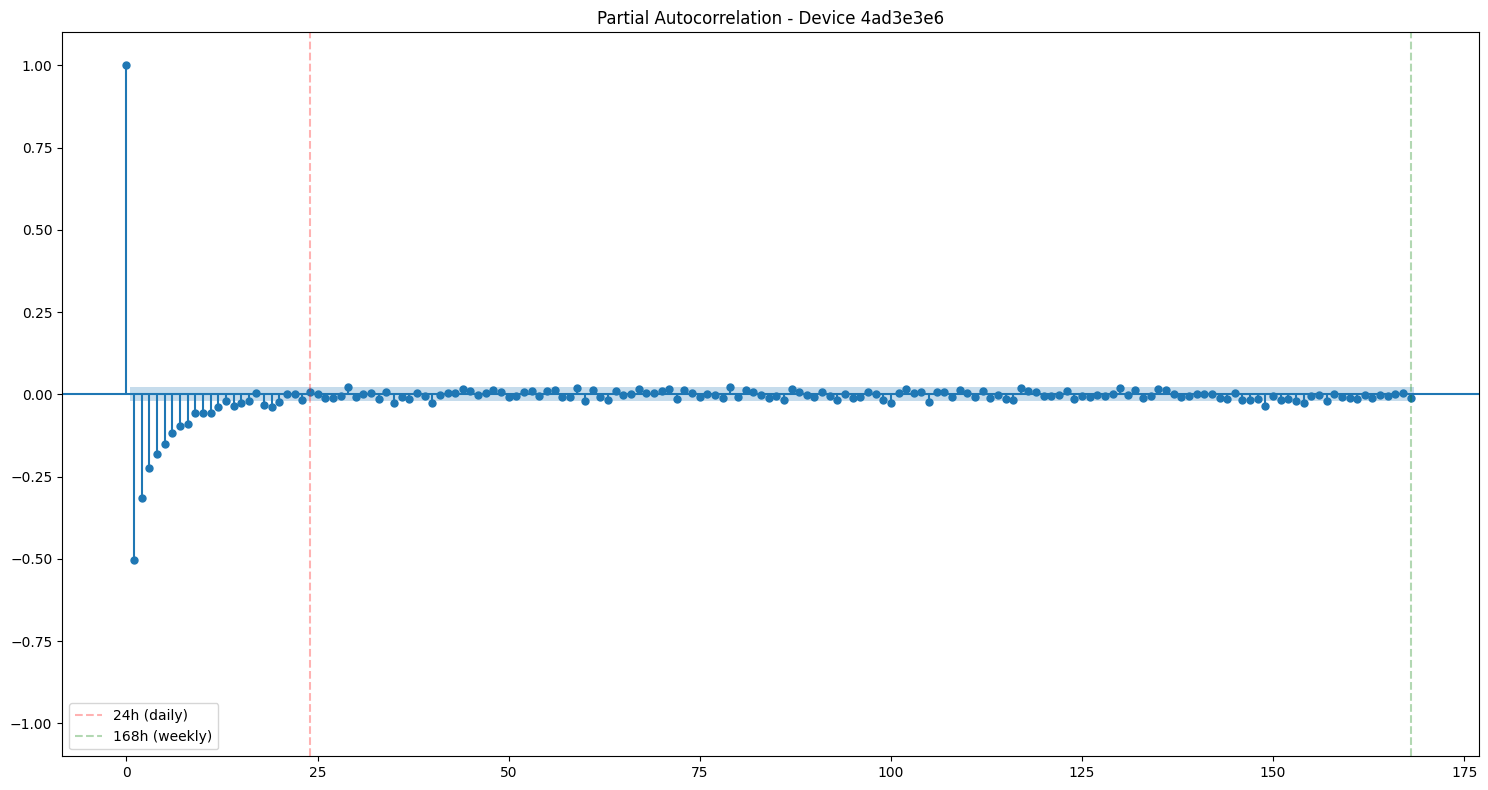

In [39]:
for device_id, hourly_data in hourly_diff_data_dict.items():
    print("="*100,f"\nDevice: {device_id[:12]}")
    # Autocorrelation analysis for the device
    plt.figure(figsize=(15, 6))
    plot_acf(hourly_data.fillna(hourly_data.median()), lags=24*7, 
             title=f'Autocorrelation - Device {device_id[:8]}')
    plt.ylim(-1.1, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Partial autocorrelation analysis
    plt.figure(figsize=(15, 6))
    plot_pacf(hourly_data.fillna(hourly_data.median()), lags=24*7, 
              title=f'Partial Autocorrelation - Device {device_id[:8]}')
    plt.ylim(-1.1, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()